# IMPORT MODUL

In [1]:
import xgboost
import skforecast
import sklearn
import lightgbm
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.feature_selection import RFECV
from skforecast.recursive import ForecasterRecursive
from skforecast.model_selection import TimeSeriesFold
from skforecast.model_selection import bayesian_search_forecaster
from skforecast.model_selection import backtesting_forecaster
from skforecast.feature_selection import select_features
from skforecast.preprocessing import RollingFeatures
import shap
# ==============================================================================
import warnings
warnings.filterwarnings('once')

color = '\033[1m\033[38;5;208m'
print(f"{color}Version skforecast: {skforecast.__version__}")
print(f"{color}Version scikit-learn: {sklearn.__version__}")
print(f"{color}Version lightgbm: {lightgbm.__version__}")

Version skforecast: 0.22.0
Version scikit-learn: 1.7.2
Version lightgbm: 4.6.0


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from darts import timeseries
from sklearn.multioutput import MultiOutputRegressor
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from xgboost import XGBRegressor
from darts import TimeSeries
from darts.models.filtering.filtering_model import FilteringModel
import statsmodels.api as sm
import statsmodels.formula.api as smf
import statsmodels.tsa.api as sm
from sklearn.metrics import mean_squared_error, mean_absolute_error
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
warnings.filterwarnings("ignore")

The StatsForecast module could not be imported. To enable support for the AutoARIMA, AutoETS and Croston models, please consider installing it.


# DATA

In [4]:
#df = pd.read_excel('brt_transjakarta.xlsx')
df = pd.read_excel('brt_baru.xlsx')

In [5]:
df

,tanggal,tahun,bulan,hari,doy,pengguna,akhir_pekan,libur_nasional,lebaran,promo_tarif,dow
0,2023-01-01,2023,1,1,1,184616,1,1,0,0,7
1,2023-01-02,2023,1,2,2,314296,0,0,0,0,1
2,2023-01-03,2023,1,3,3,339823,0,0,0,0,2
3,2023-01-04,2023,1,4,4,348919,0,0,0,0,3
4,2023-01-05,2023,1,5,5,348914,0,0,0,0,4
...,...,...,...,...,...,...,...,...,...,...,...
938,2025-07-27,2025,7,27,208,298335,1,0,0,0,7
939,2025-07-28,2025,7,28,209,476862,0,0,0,0,1
940,2025-07-29,2025,7,29,210,490471,0,0,0,0,2
941,2025-07-30,2025,7,30,211,492080,0,0,0,0,3


In [19]:
def add_annotation(tanggal, label, y_text, color):
    tanggal = pd.Timestamp(tanggal)

    baris = data_plot.iloc[
        (data_plot["tanggal"] - tanggal).abs().argsort()[:1]
    ]

    x = baris["tanggal"].iloc[0]
    y = baris["pengguna"].iloc[0]

    ax.annotate(
        label,
        xy=(x, y),
        xytext=(x, y_text),
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=color,
        arrowprops=dict(
            arrowstyle="-|>",
            color=color,
            linewidth=1.2
        )
    )

### bds

In [8]:
from statsmodels.tsa.stattools import bds
x=df['pengguna']
result = bds(x, max_dim=2, epsilon=None, distance=1.5)
print(result)


(array(24.8953864), array(8.34735578e-137))


In [9]:
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import bds


# Jalankan uji BDS
# m: embedding dimension (umumnya 2-5)
# epsilon: radius; jika None, akan dihitung otomatis
try:
    bds_stat, p_values = bds(x, max_dim=5, epsilon=None)
    
    # Tampilkan hasil dalam DataFrame agar rapi
    result_df = pd.DataFrame({
        "Embedding Dimension (m)": range(2, 6),
        "BDS Statistic": bds_stat,
        "p-value": p_values
    })
    
    print(result_df)
    
    # Interpretasi sederhana
    print("\nInterpretasi:")
    print("- H0: Data bersifat IID (independent and identically distributed)")
    print("- Jika p-value < 0.05 → Tolak H0 → Ada indikasi dependensi/non-linearitas")
    print("- Jika p-value ≥ 0.05 → Gagal tolak H0 → Data konsisten dengan IID")
    
except Exception as e:
    print(f"Terjadi kesalahan: {e}")


   Embedding Dimension (m)  BDS Statistic        p-value
0                        2      24.895386  8.347356e-137
1                        3      20.470499   3.945570e-93
2                        4      16.996891   8.659215e-65
3                        5      13.175111   1.220483e-39

Interpretasi:
- H0: Data bersifat IID (independent and identically distributed)
- Jika p-value < 0.05 → Tolak H0 → Ada indikasi dependensi/non-linearitas
- Jika p-value ≥ 0.05 → Gagal tolak H0 → Data konsisten dengan IID


In [10]:
result = bds(x)
print(f"Statistik: {result[0]:.6f}, p-value: {result[1]:.6e}")


Statistik: 24.895386, p-value: 8.347356e-137


# PREPROCESSING

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 943 entries, 0 to 942
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   tanggal         943 non-null    datetime64[ns]
 1   tahun           943 non-null    int64         
 2   bulan           943 non-null    int64         
 3   hari            943 non-null    int64         
 4   doy             943 non-null    int64         
 5   pengguna        943 non-null    int64         
 6   akhir_pekan     943 non-null    int64         
 7   libur_nasional  943 non-null    int64         
 8   lebaran         943 non-null    int64         
 9   promo_tarif     943 non-null    int64         
 10  dow             943 non-null    int64         
dtypes: datetime64[ns](1), int64(10)
memory usage: 81.2 KB


df2 = df2.astype({
    "tahun": "category",
    "bulan": "category",
    "hari": "category",
    "doy": "int64",   # tetap int karena urutan hari dalam setahun
    "dow": "category",
    "akhir_pekan": "bool",
    "libur_nasional": "bool",
    "lebaran": "bool",
    "promo_tarif": "bool"
})


## CEK MISSING VALUE

In [14]:
df.isna().sum()

tanggal           0
tahun             0
bulan             0
hari              0
doy               0
pengguna          0
akhir_pekan       0
libur_nasional    0
lebaran           0
promo_tarif       0
dow               0
dtype: int64

## DATA INFO

In [16]:
#df=df_daily.copy()
#df.index = pd.to_datetime(df.index)
#df=df.reset_index()
print("="*60)
print("DATASET OVERVIEW")
print("="*60)
print(f"Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nData types:\n{df.dtypes}")
print(f"\nMissing values:\n{df.isnull().sum()}")
print(f"\nBasic statistics:\n{df.describe()}")

DATASET OVERVIEW
Shape: (943, 11)

Columns: ['tanggal', 'tahun', 'bulan', 'hari', 'doy', 'pengguna', 'akhir_pekan', 'libur_nasional', 'lebaran', 'promo_tarif', 'dow']

Data types:
tanggal           datetime64[ns]
tahun                      int64
bulan                      int64
hari                       int64
doy                        int64
pengguna                   int64
akhir_pekan                int64
libur_nasional             int64
lebaran                    int64
promo_tarif                int64
dow                        int64
dtype: object

Missing values:
tanggal           0
tahun             0
bulan             0
hari              0
doy               0
pengguna          0
akhir_pekan       0
libur_nasional    0
lebaran           0
promo_tarif       0
dow               0
dtype: int64

Basic statistics:
                   tanggal        tahun       bulan        hari         doy  \
count                  943   943.000000  943.000000  943.000000  943.000000   
mean   2024-04-1

# EDA

## CEK KORELASI SETIAP VARIABEL TERHADAP UV

In [21]:
#df=df_max_per_day.copy()
df_selected = df.drop(columns=['tanggal','akhir_pekan'])#,'hari','tahun','bulan','doy'])#,'index','year','day','month','date','hour'])
corr_matrix = df_selected.corr()
print(corr_matrix)

                   tahun     bulan      hari       doy  pengguna  \
tahun           1.000000 -0.255909 -0.001996 -0.254540  0.334021   
bulan          -0.255909  1.000000  0.010469  0.996294  0.155887   
hari           -0.001996  0.010469  1.000000  0.096087 -0.018025   
doy            -0.254540  0.996294  0.096087  1.000000  0.154441   
pengguna        0.334021  0.155887 -0.018025  0.154441  1.000000   
libur_nasional  0.033608 -0.105115  0.005759 -0.104533 -0.384287   
lebaran         0.021951 -0.054328  0.037416 -0.051123 -0.245363   
promo_tarif     0.066770  0.004784  0.009765  0.005309  0.109128   
dow            -0.003108  0.006468 -0.004570  0.006026 -0.574889   

                libur_nasional   lebaran  promo_tarif       dow  
tahun                 0.033608  0.021951     0.066770 -0.003108  
bulan                -0.105115 -0.054328     0.004784  0.006468  
hari                  0.005759  0.037416     0.009765 -0.004570  
doy                  -0.104533 -0.051123     0.005309  

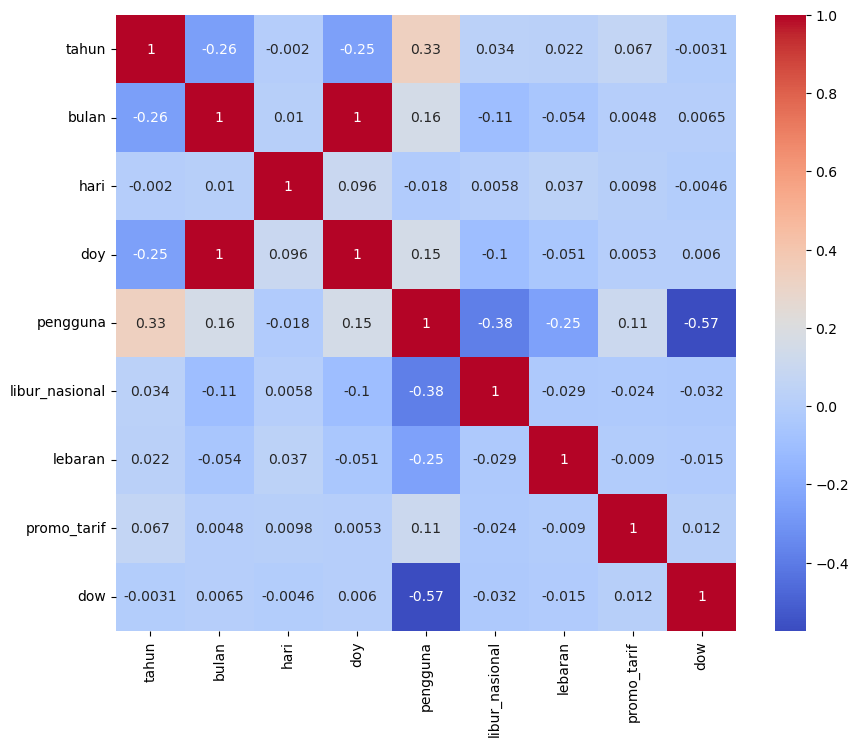

In [22]:
plt.figure(figsize=(10,8))
sns.heatmap(df_selected.corr(), annot=True, cmap='coolwarm')
plt.show()

## CEK VIF MULTIKOLINEARITAS

In [24]:
df.columns

Index(['tanggal', 'tahun', 'bulan', 'hari', 'doy', 'pengguna', 'akhir_pekan',
       'libur_nasional', 'lebaran', 'promo_tarif', 'dow'],
      dtype='object')

In [25]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Define a function for VIF calculation to reuse later if needed
def calculate_vif(df, features):# Add a constant to the features (for the intercept in the regression)
    X_vif = sm.add_constant(df[features])

    # Create a DataFrame to hold VIF values
    vif_data = pd.DataFrame()
    vif_data["feature"] = X_vif.columns

    \
    # Calculating VIF for each feature
    vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i)
                       for i in range(X_vif.shape[1])]

    # Drop the constant row if not needed
    vif_data = vif_data[vif_data["feature"] != "const"]

    return vif_data.reset_index(drop=True)

# List of features for VIF calculation
features =  ['tahun', 'doy',
       'libur_nasional', 'lebaran', 'promo_tarif']

# Call the function and print the VIF results
vif_results = calculate_vif(df, features)
print(vif_results)

          feature       VIF
0           tahun  1.074811
1             doy  1.083108
2  libur_nasional  1.012971
3         lebaran  1.004039
4     promo_tarif  1.005731


## CEK DISTRIBUSI DATA

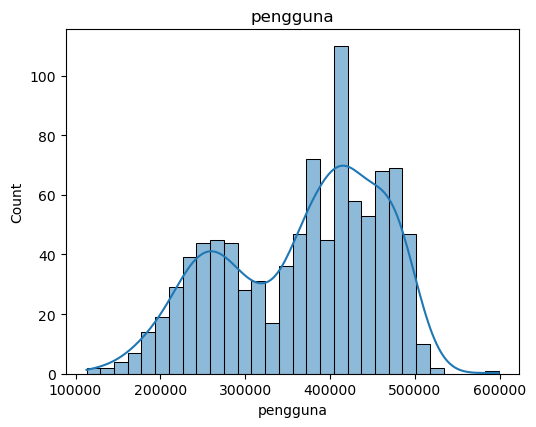

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

num_cols = ['pengguna']
#]

fig, axes = plt.subplots(3, 3, figsize=(15,12))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=axes[i])
    axes[i].set_title(col)

# hapus subplot kosong
for j in range(len(num_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


## CEK OUTLIER

Outlier tidak dibuang ataupun ditransformasi karena mengandung informasi penting

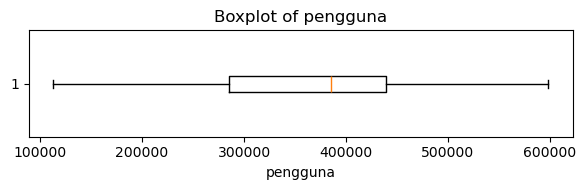

In [20]:
cols = ['pengguna']

for col in cols:
    plt.figure(figsize=(6, 2))
    plt.boxplot(df[col].dropna(), vert=False)
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.tight_layout()
    plt.show()


In [22]:
tanggal_demo = pd.to_datetime("2025-08-30")
median_weekend = df.loc[
    (df['akhir_pekan'] == 1) &
    (df['libur_nasional'] == 0),
    'pengguna'
].median()
df.loc[df['tanggal'] == tanggal_demo, 'pengguna'] = median_weekend
df.loc[df['tanggal'] == tanggal_demo, ['tanggal', 'pengguna']]

,tanggal,pengguna


In [24]:
import numpy as np

Q1 = df["pengguna"].quantile(0.25)
Q3 = df["pengguna"].quantile(0.75)
IQR = Q3 - Q1

# batas bawah dan atas
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# flag outlier
outliers = (df["pengguna"] < lower) | (df["pengguna"] > upper)

print(df[outliers])


Empty DataFrame
Columns: [tanggal, tahun, bulan, hari, doy, pengguna, akhir_pekan, libur_nasional, lebaran, promo_tarif, dow]
Index: []


In [26]:
from scipy.stats import zscore
import numpy as np

z = np.abs(zscore(df["pengguna"]))

outliers = df[z > 3]

print(outliers)

Empty DataFrame
Columns: [tanggal, tahun, bulan, hari, doy, pengguna, akhir_pekan, libur_nasional, lebaran, promo_tarif, dow]
Index: []


In [13]:
df.describe()

,tanggal,tahun,bulan,hari,doy,pengguna,akhir_pekan,libur_nasional,lebaran,promo_tarif,dow
count,943,943.000000,943.000000,943.000000,943.000000,943.000000,943.000000,943.000000,943.000000,943.000000,943.000000
mean,2024-04-16 00:00:00,2023.837752,5.957582,15.721103,165.995758,367181.673383,0.285260,0.074231,0.010604,0.007423,3.996819
min,2023-01-01 00:00:00,2023.000000,1.000000,1.000000,1.000000,112953.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2023-08-24 12:00:00,2023.000000,3.000000,8.000000,79.000000,285290.500000,0.000000,0.000000,0.000000,0.000000,2.000000
50%,2024-04-16 00:00:00,2024.000000,6.000000,16.000000,158.000000,385716.000000,0.000000,0.000000,0.000000,0.000000,4.000000
75%,2024-12-07 12:00:00,2024.000000,9.000000,23.000000,248.000000,439621.500000,1.000000,0.000000,0.000000,0.000000,6.000000
max,2025-07-31 00:00:00,2025.000000,12.000000,31.000000,366.000000,598535.000000,1.000000,1.000000,1.000000,1.000000,7.000000
std,NaN,0.765620,3.351063,8.800432,102.515889,91615.342420,0.451778,0.262286,0.102485,0.085883,2.001854


## UJI STASIONERITAS ADF DAN KPPS

In [35]:
#  Uji ADF 
ts=df['pengguna']
adf_result = adfuller(ts)
adf_stat, adf_pvalue, _, _, adf_crit = adf_result[:5]

print("=== Augmented Dickey-Fuller Test (ADF) ===")
print(f"ADF Statistic: {adf_stat:.4f}")
print(f"p-value: {adf_pvalue:.4f}")
print("Critical Values:", adf_crit)

if adf_pvalue < 0.05:
    print("→ Tolak H0: Data stasioner (tidak ada unit root).")
else:
    print("→ Gagal tolak H0: Data non-stasioner (ada unit root).")

# --- Uji KPSS ---
kpss_result = kpss(ts, regression='c')
kpss_stat, kpss_pvalue, _, kpss_crit = kpss_result

print("\n=== KPSS Test ===")
print(f"KPSS Statistic: {kpss_stat:.4f}")
print(f"p-value: {kpss_pvalue:.4f}")
print("Critical Values:", kpss_crit)

if kpss_pvalue < 0.05:
    print("→ Tolak H0: Data non-stasioner.")
else:
    print("→ Gagal tolak H0: Data stasioner.")



=== Augmented Dickey-Fuller Test (ADF) ===
ADF Statistic: -2.6685
p-value: 0.0796
Critical Values: {'1%': np.float64(-3.437470108019385), '5%': np.float64(-2.8646832620852853), '10%': np.float64(-2.5684436698650503)}
→ Gagal tolak H0: Data non-stasioner (ada unit root).

=== KPSS Test ===
KPSS Statistic: 5.0291
p-value: 0.0100
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
→ Tolak H0: Data non-stasioner.


## DATA TARGET FLUKTUASI

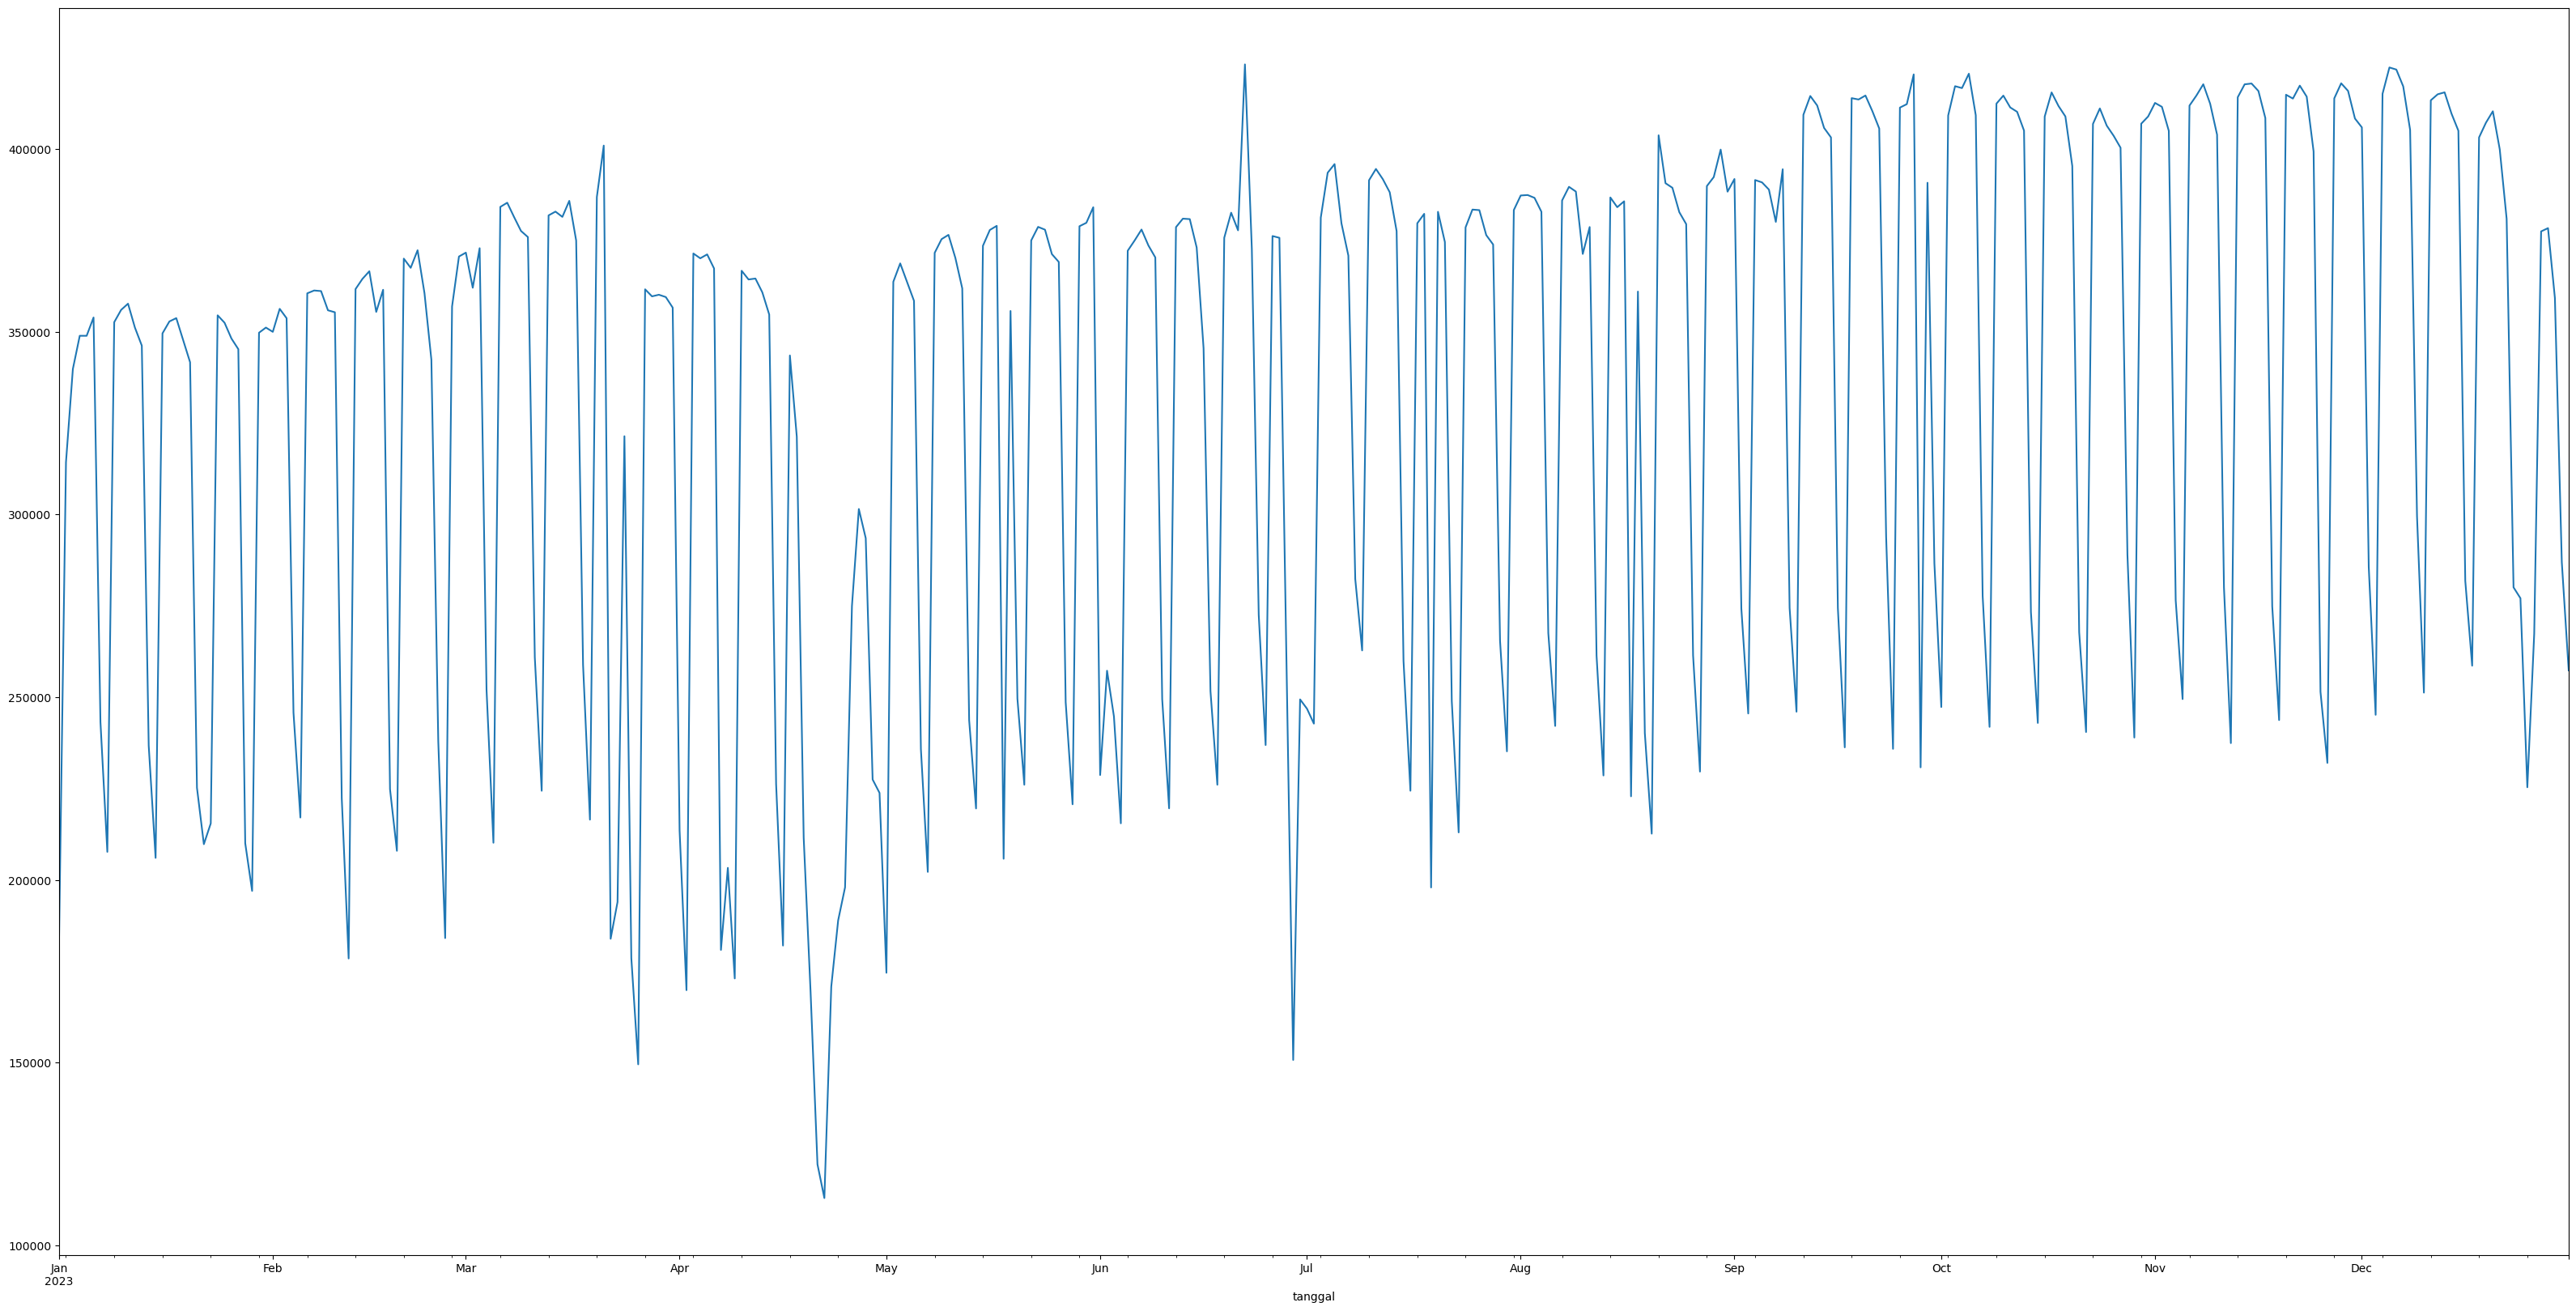

In [39]:
g = df.set_index('tanggal').head(365)
g['pengguna'].plot(figsize=(40, 20))
plt.show()

## PACF DAN ACF

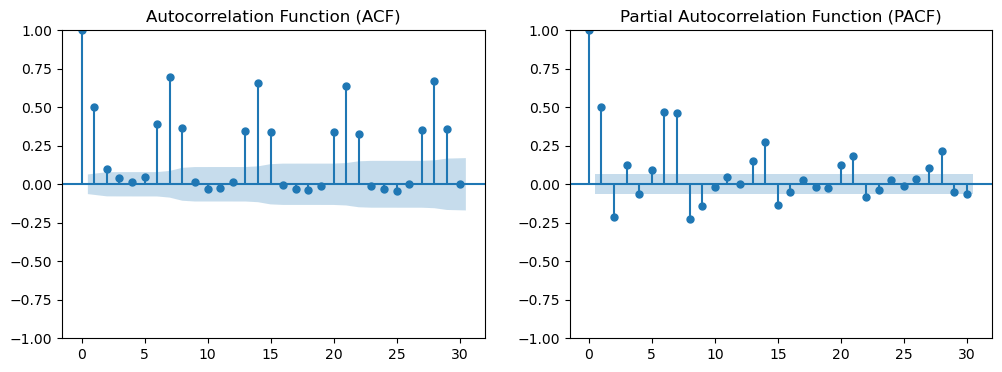

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
# Plot ACF dan PACF
fig, axes = plt.subplots(1, 2, figsize=(12,4))
ts=df['pengguna']
plot_acf(ts, lags=30, ax=axes[0])
axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(ts, lags=30, ax=axes[1], method='ywm')
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.show()


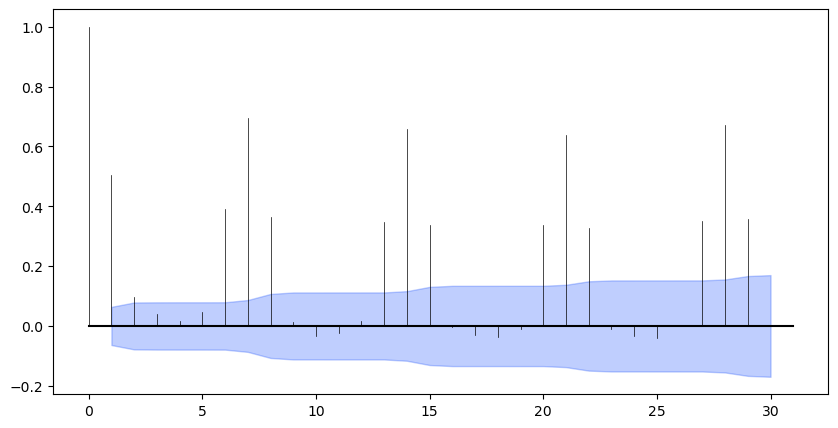

In [42]:
from darts.utils.statistics import plot_acf, check_seasonality
from darts import TimeSeries

ts = TimeSeries.from_series(df['pengguna'])
plot_acf(ts, m=30, alpha=0.05, max_lag=30)
plt.show()


In [43]:
for m in range(2, 90):
    is_seasonal, period = check_seasonality(ts, m=m, alpha=0.05, max_lag=90)
    if is_seasonal:
        print(f"There is seasonality of order {period}.")

There is seasonality of order 7.
There is seasonality of order 14.
There is seasonality of order 21.
There is seasonality of order 28.
There is seasonality of order 35.
There is seasonality of order 42.
There is seasonality of order 49.
There is seasonality of order 56.
There is seasonality of order 63.
There is seasonality of order 70.
There is seasonality of order 77.
There is seasonality of order 84.


In [61]:
for m in range(2, 90):
    is_seasonal, period = check_seasonality(ts, m=m, alpha=0.05, max_lag=90)
    if is_seasonal:
        print(f"There is seasonality of order {period}.")

There is seasonality of order 7.
There is seasonality of order 14.
There is seasonality of order 21.
There is seasonality of order 28.
There is seasonality of order 35.
There is seasonality of order 42.
There is seasonality of order 49.
There is seasonality of order 56.
There is seasonality of order 63.
There is seasonality of order 70.
There is seasonality of order 77.
There is seasonality of order 84.


adanya musiman mingguan

## DEKOMPOSISI TIMESERIES

3. TIME SERIES DECOMPOSITION (Trend + Seasonal + Residual)


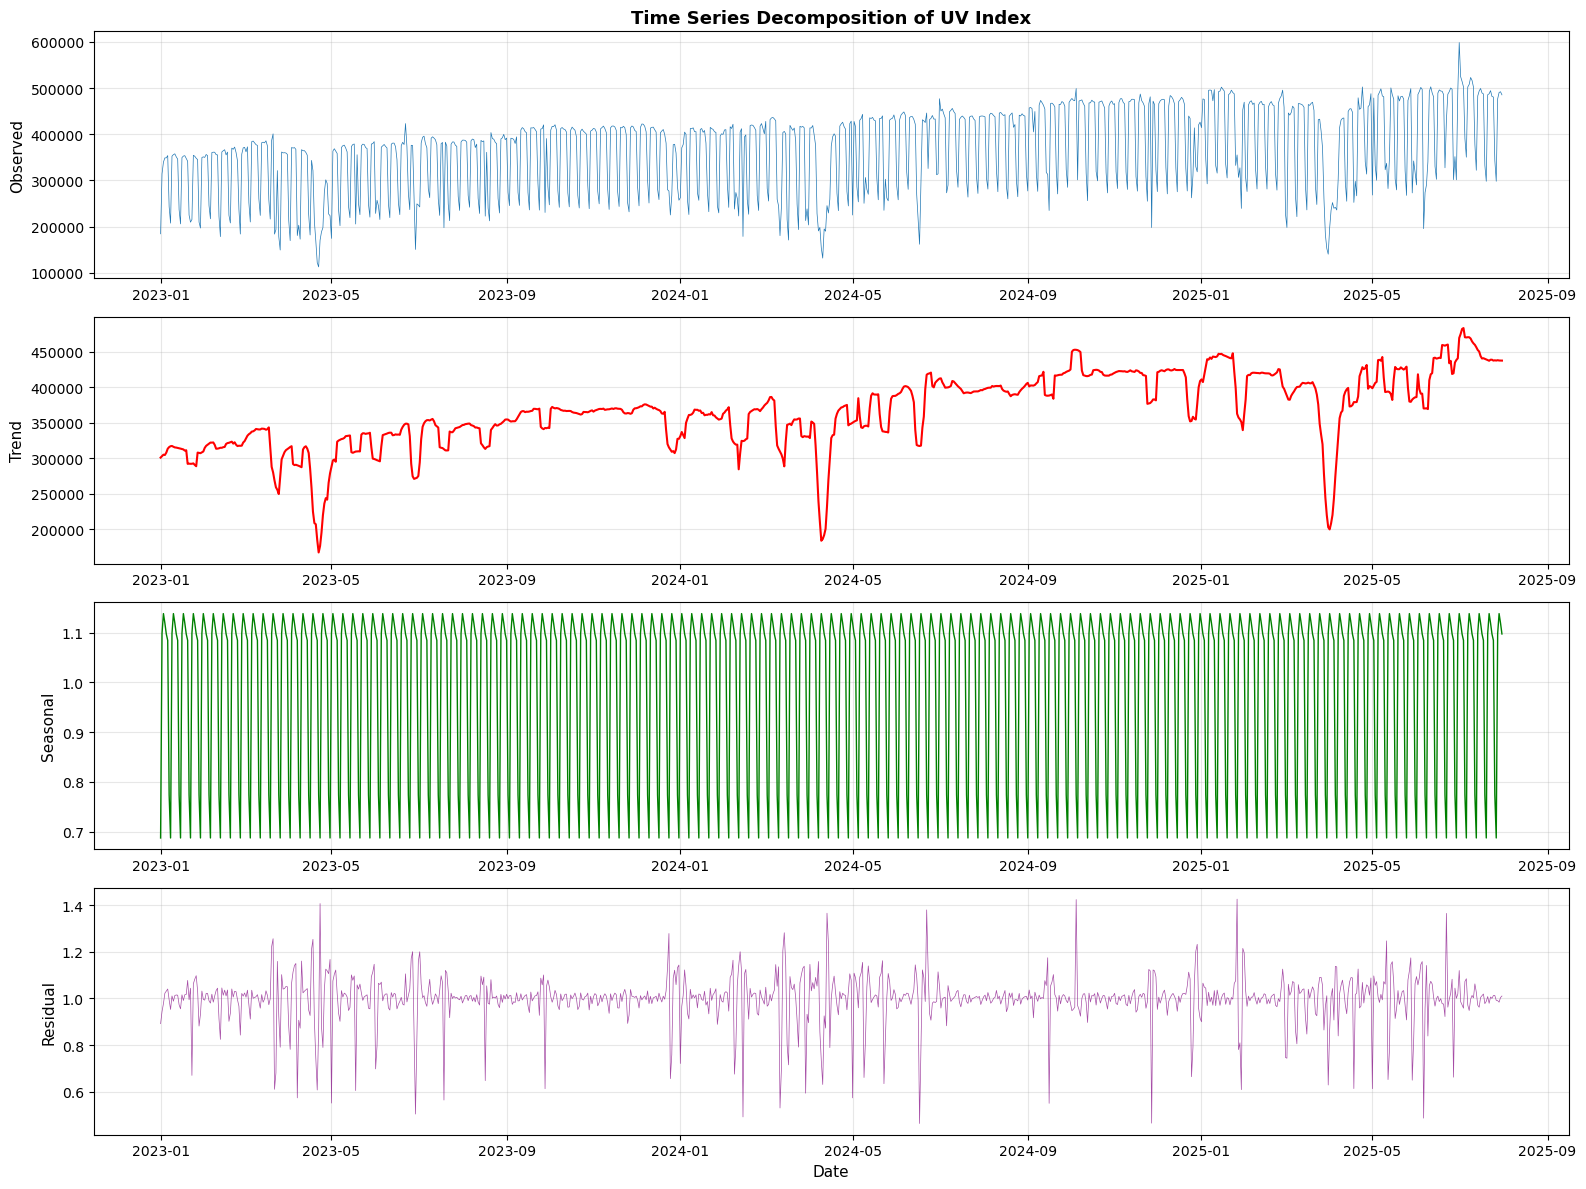

In [65]:
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
import warnings
warnings.filterwarnings('ignore')

# 3. TIME SERIES DECOMPOSITION

print("3. TIME SERIES DECOMPOSITION (Trend + Seasonal + Residual)")


# Prepare data for decomposition
ts_data = df.set_index('tanggal')['pengguna']
ts_data = ts_data.asfreq('D')  # Daily frequency

# Decompose (using additive model)
decomposition = seasonal_decompose(ts_data, model='multiplicative', period=7, extrapolate_trend='freq')

fig, axes = plt.subplots(4, 1, figsize=(16, 12))

# Original
axes[0].plot(decomposition.observed, linewidth=0.5)
axes[0].set_ylabel('Observed', fontsize=11)
axes[0].set_title('Time Series Decomposition of UV Index', fontsize=13, fontweight='bold')
axes[0].grid(alpha=0.3)

# Trend
axes[1].plot(decomposition.trend, linewidth=1.5, color='red')
axes[1].set_ylabel('Trend', fontsize=11)
axes[1].grid(alpha=0.3)

# Seasonal
axes[2].plot(decomposition.seasonal, linewidth=1, color='green')
axes[2].set_ylabel('Seasonal', fontsize=11)
axes[2].grid(alpha=0.3)

# Residual
axes[3].plot(decomposition.resid, linewidth=0.5, color='purple', alpha=0.7)
axes[3].set_ylabel('Residual', fontsize=11)
axes[3].set_xlabel('Date', fontsize=11)
axes[3].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('seasonality_decomposition.png', dpi=300, bbox_inches='tight')
plt.show()


## VISUALISASI RATA-RATA PENGGUNA 

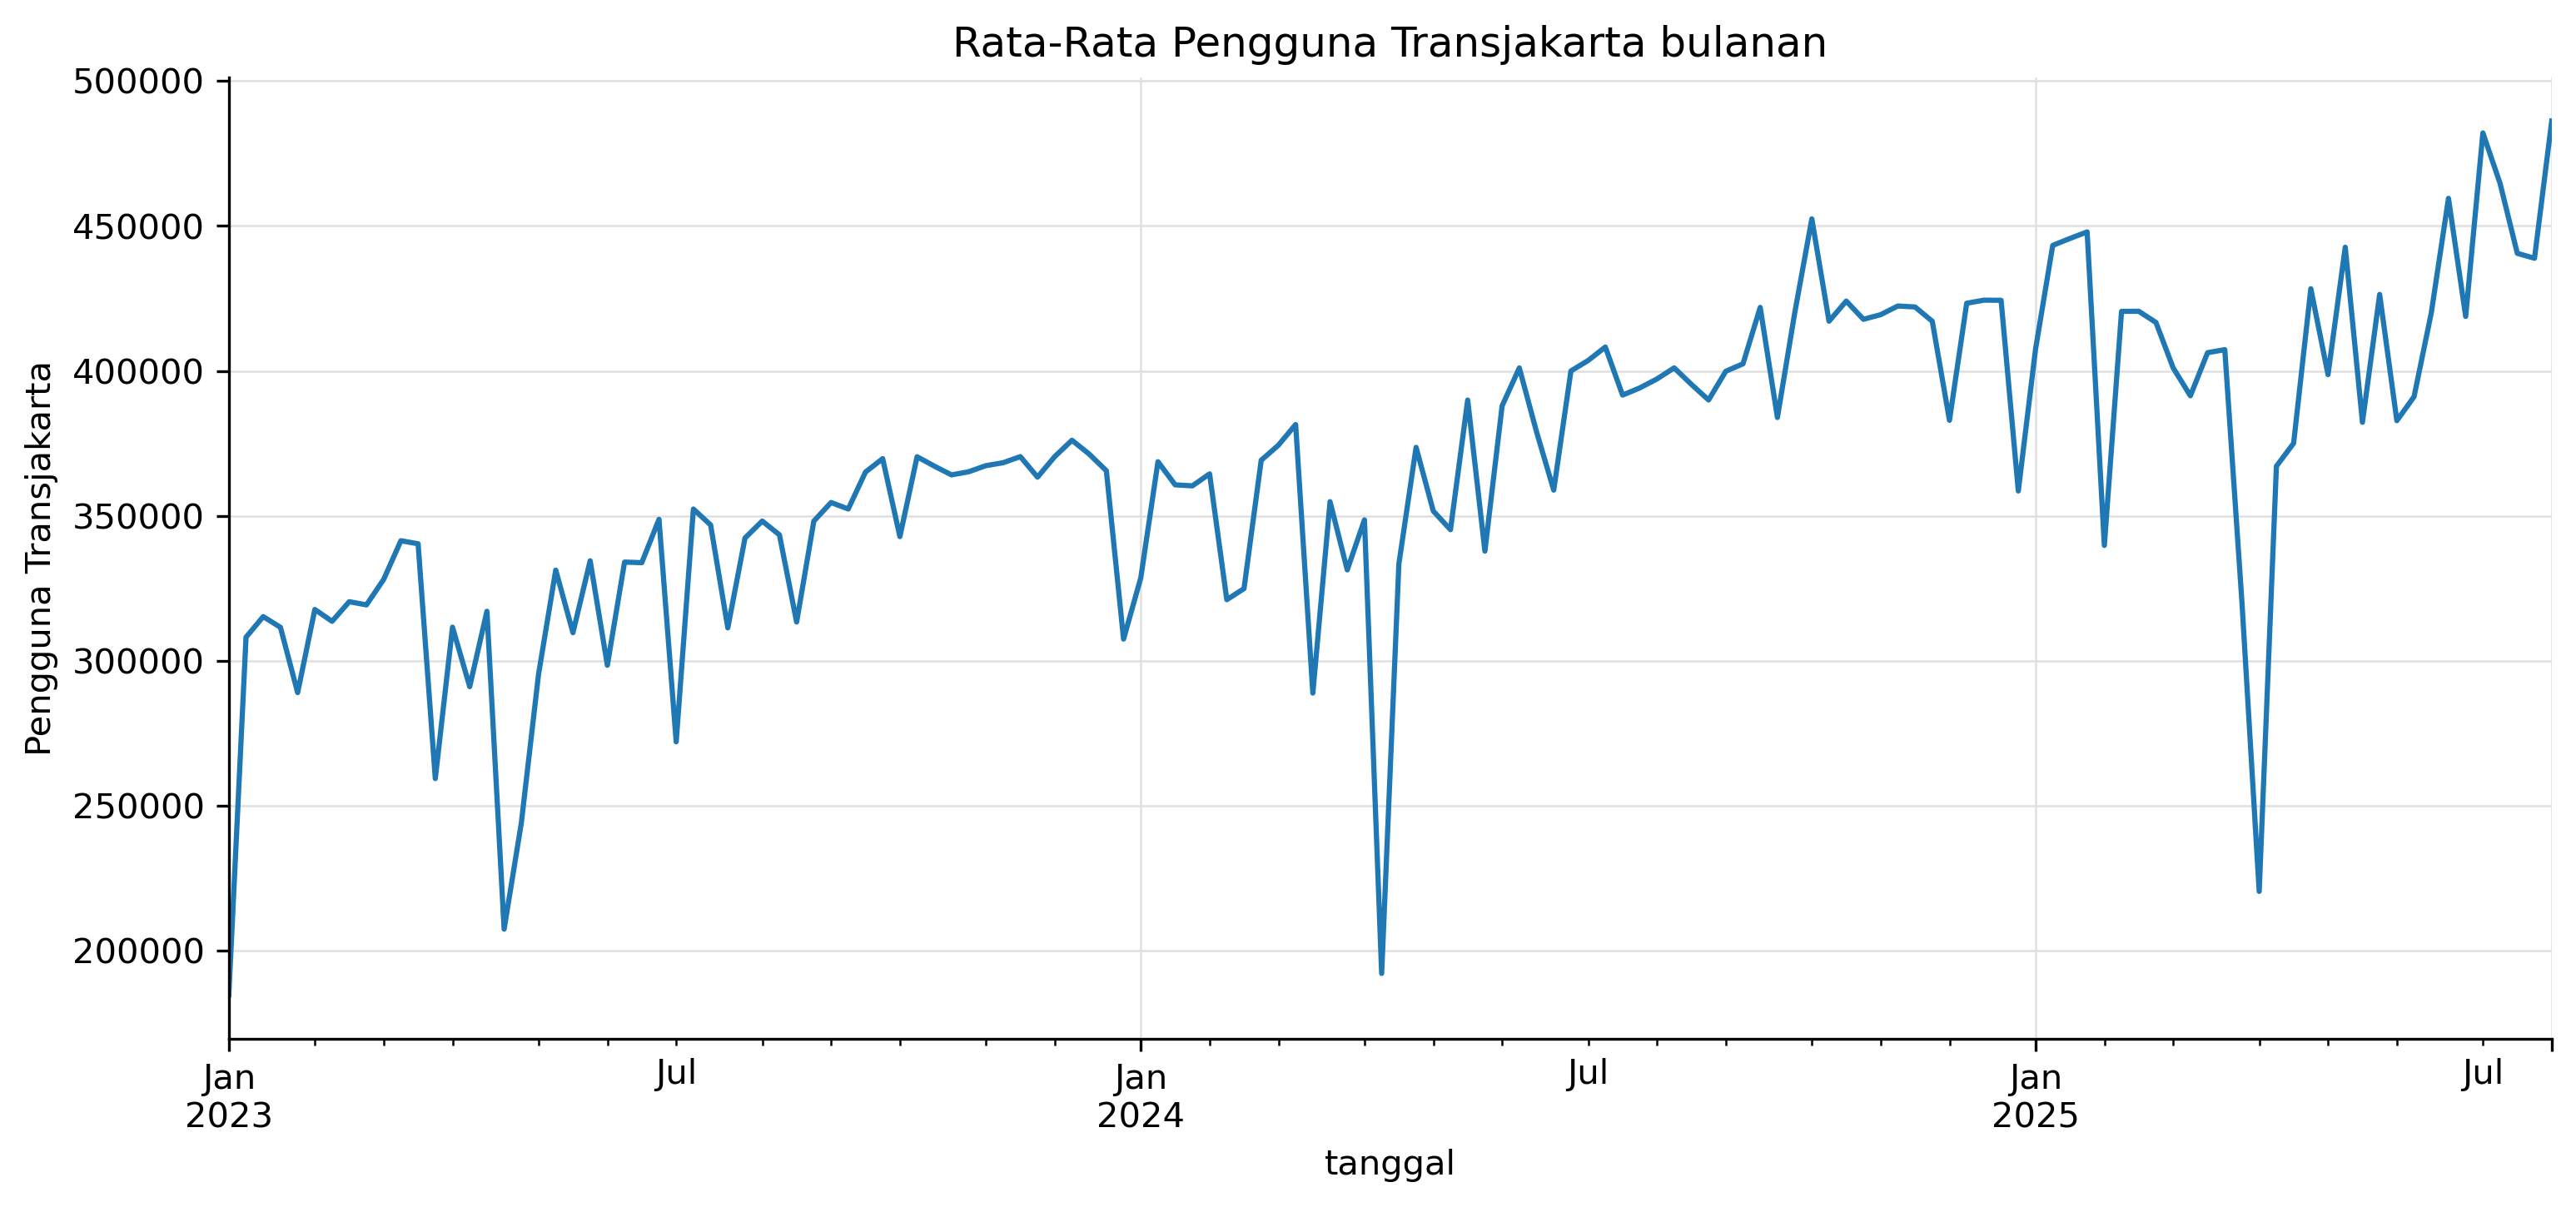

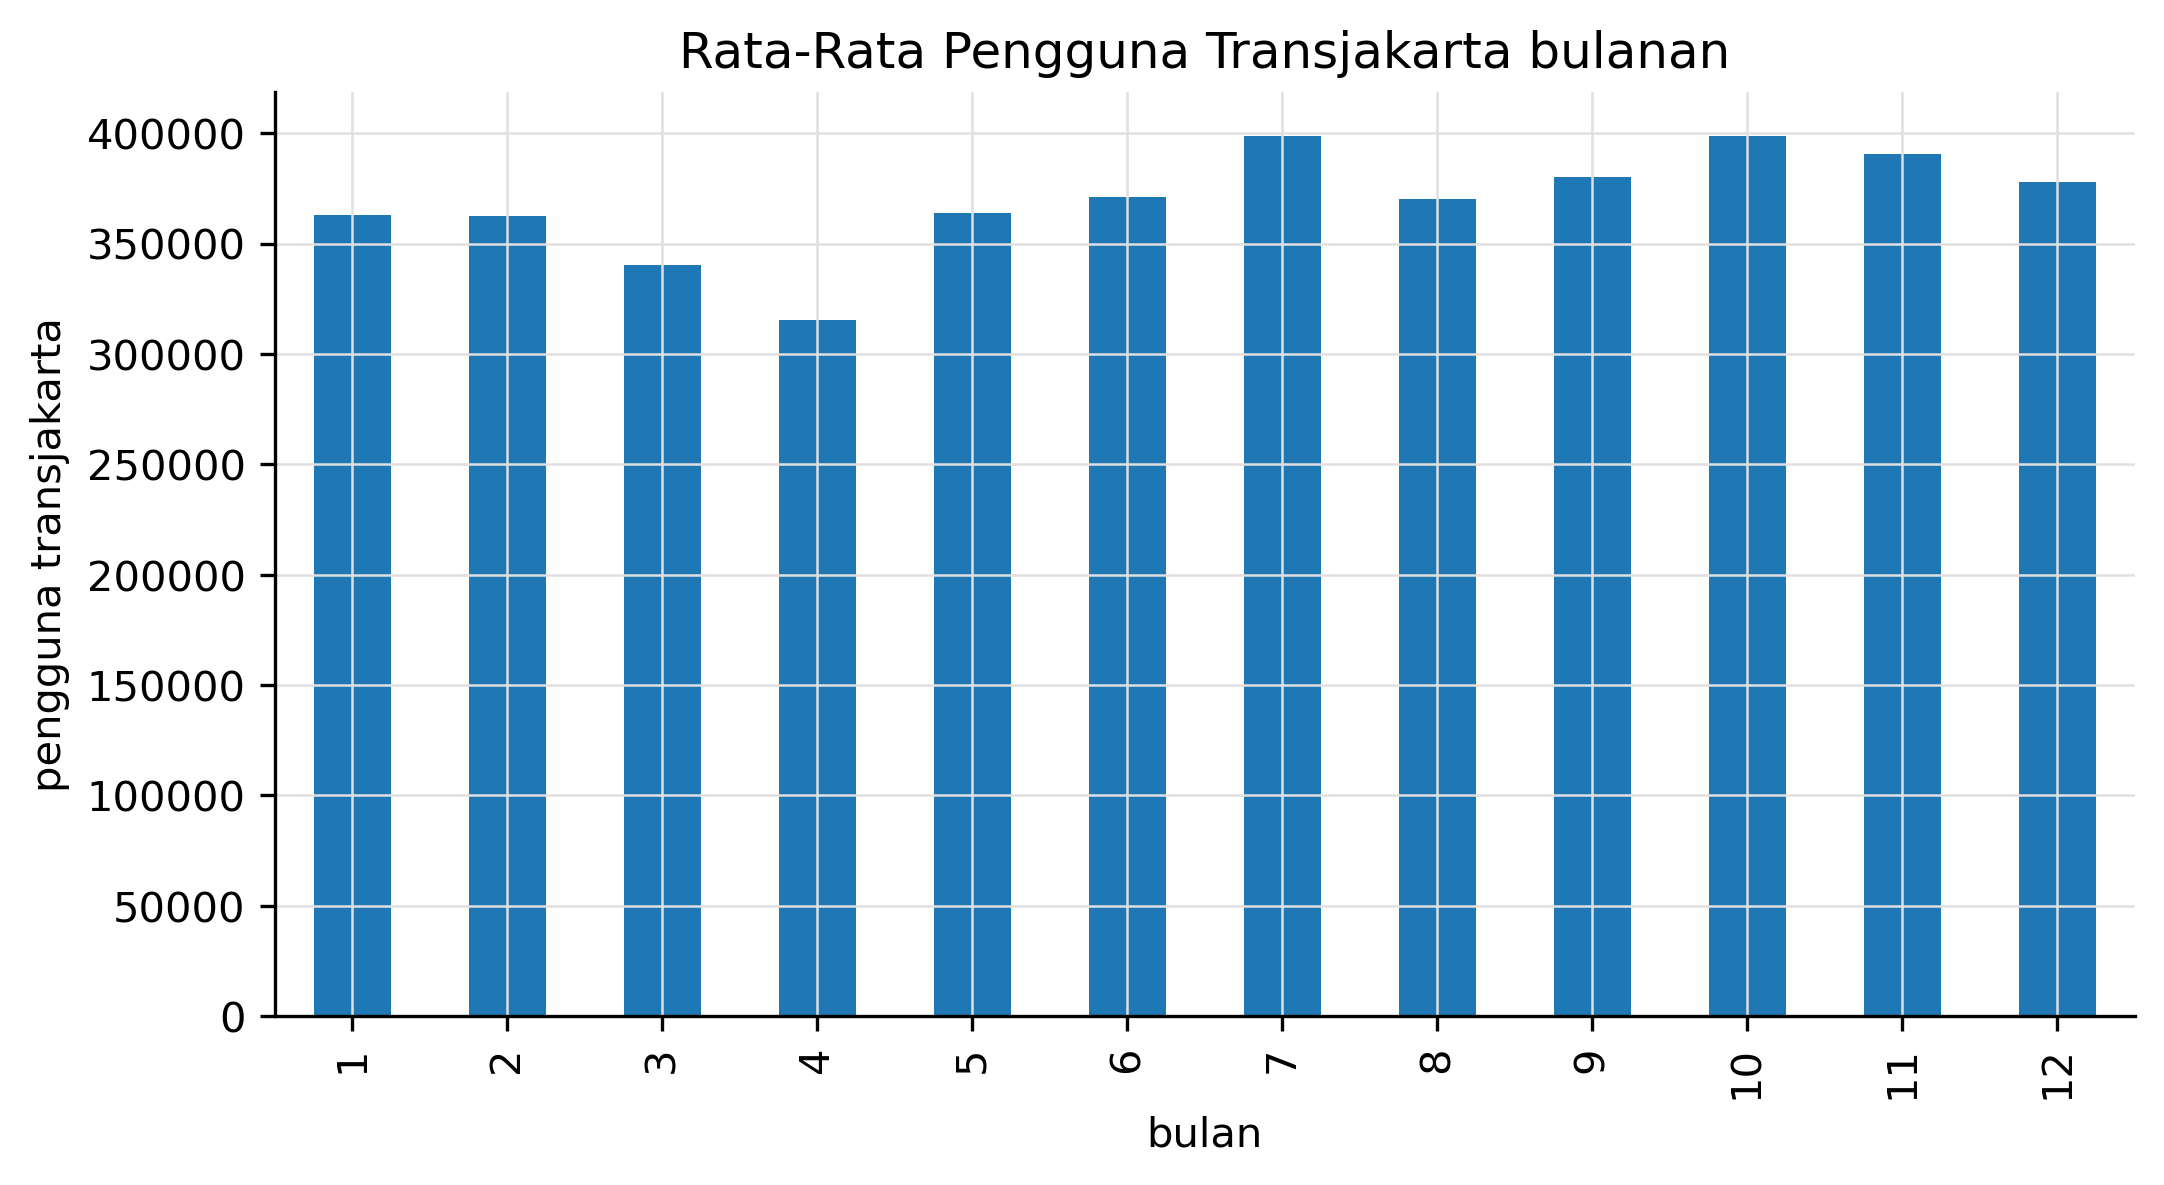

In [276]:
# 2. Rata-rata bulanan
#df["date"] = pd.to_datetime(df["date"])
f= df.set_index('tanggal')
monthly_avg = f['pengguna'].resample('w').mean()

plt.figure(figsize=(12,5))
monthly_avg.plot()
plt.title("Rata-Rata Pengguna Transjakarta bulanan")
plt.ylabel("Pengguna Transjakarta")
plt.xlabel("tanggal")
plt.show()

# lihat rata-rata per bulan (Jan, Feb, dst) across years:
f['month'] = f.index.month
monthly_mean = f.groupby('month')['pengguna'].mean()

plt.figure(figsize=(8,4))
monthly_mean.plot(kind='bar')
plt.title("Rata-Rata Pengguna Transjakarta bulanan")
plt.ylabel("pengguna transjakarta")
plt.xlabel("bulan")
plt.show()


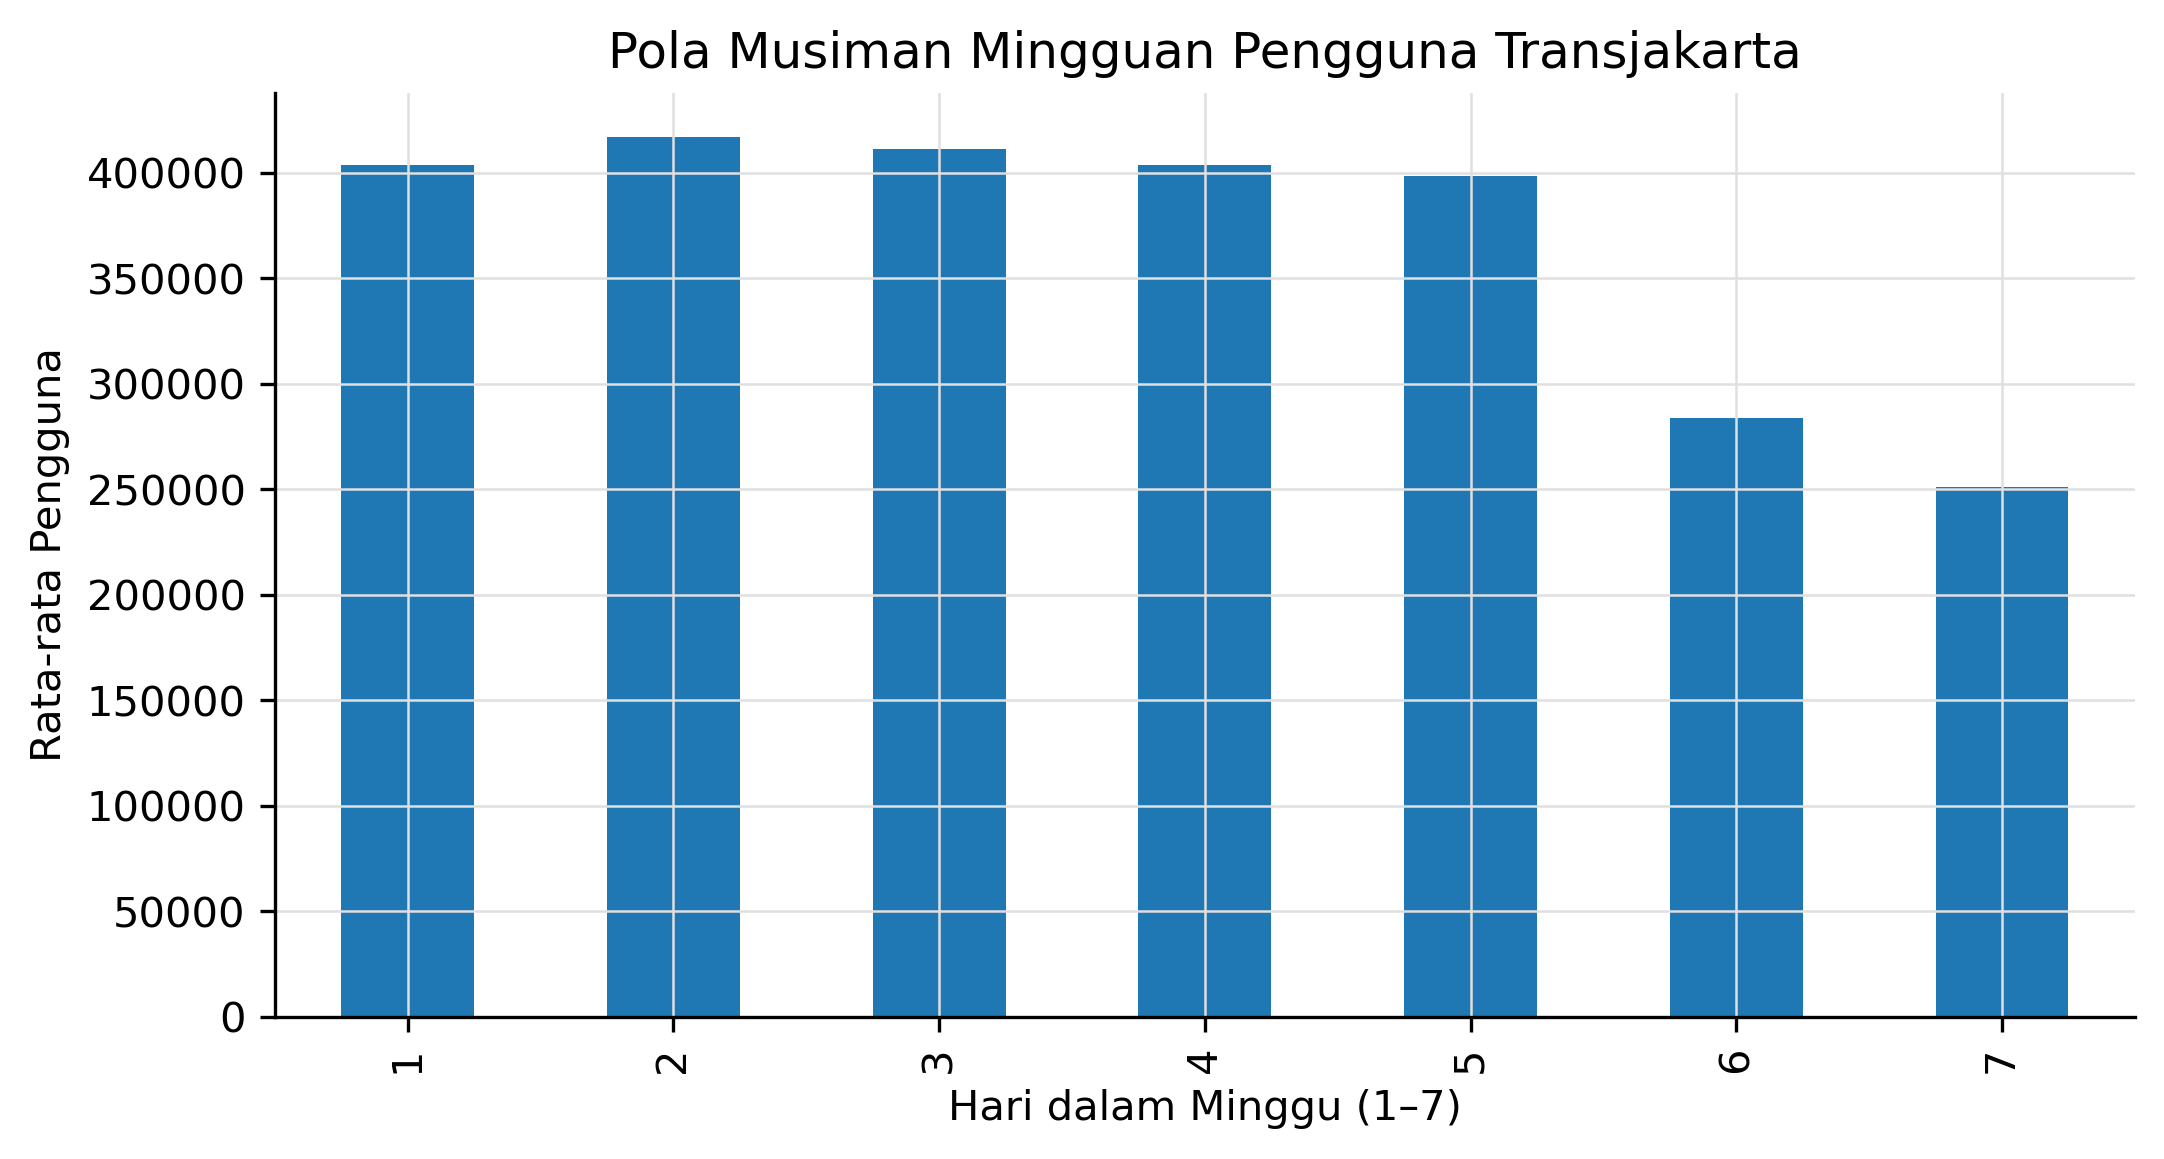

In [277]:
weekly_seasonal = df.groupby('dow')['pengguna'].mean()

plt.figure(figsize=(8,4))
weekly_seasonal.plot(kind='bar')
plt.title("Pola Musiman Mingguan Pengguna Transjakarta")
plt.xlabel("Hari dalam Minggu (1–7)")
plt.ylabel("Rata-rata Pengguna")
plt.show()

<Figure size 3000x1500 with 0 Axes>

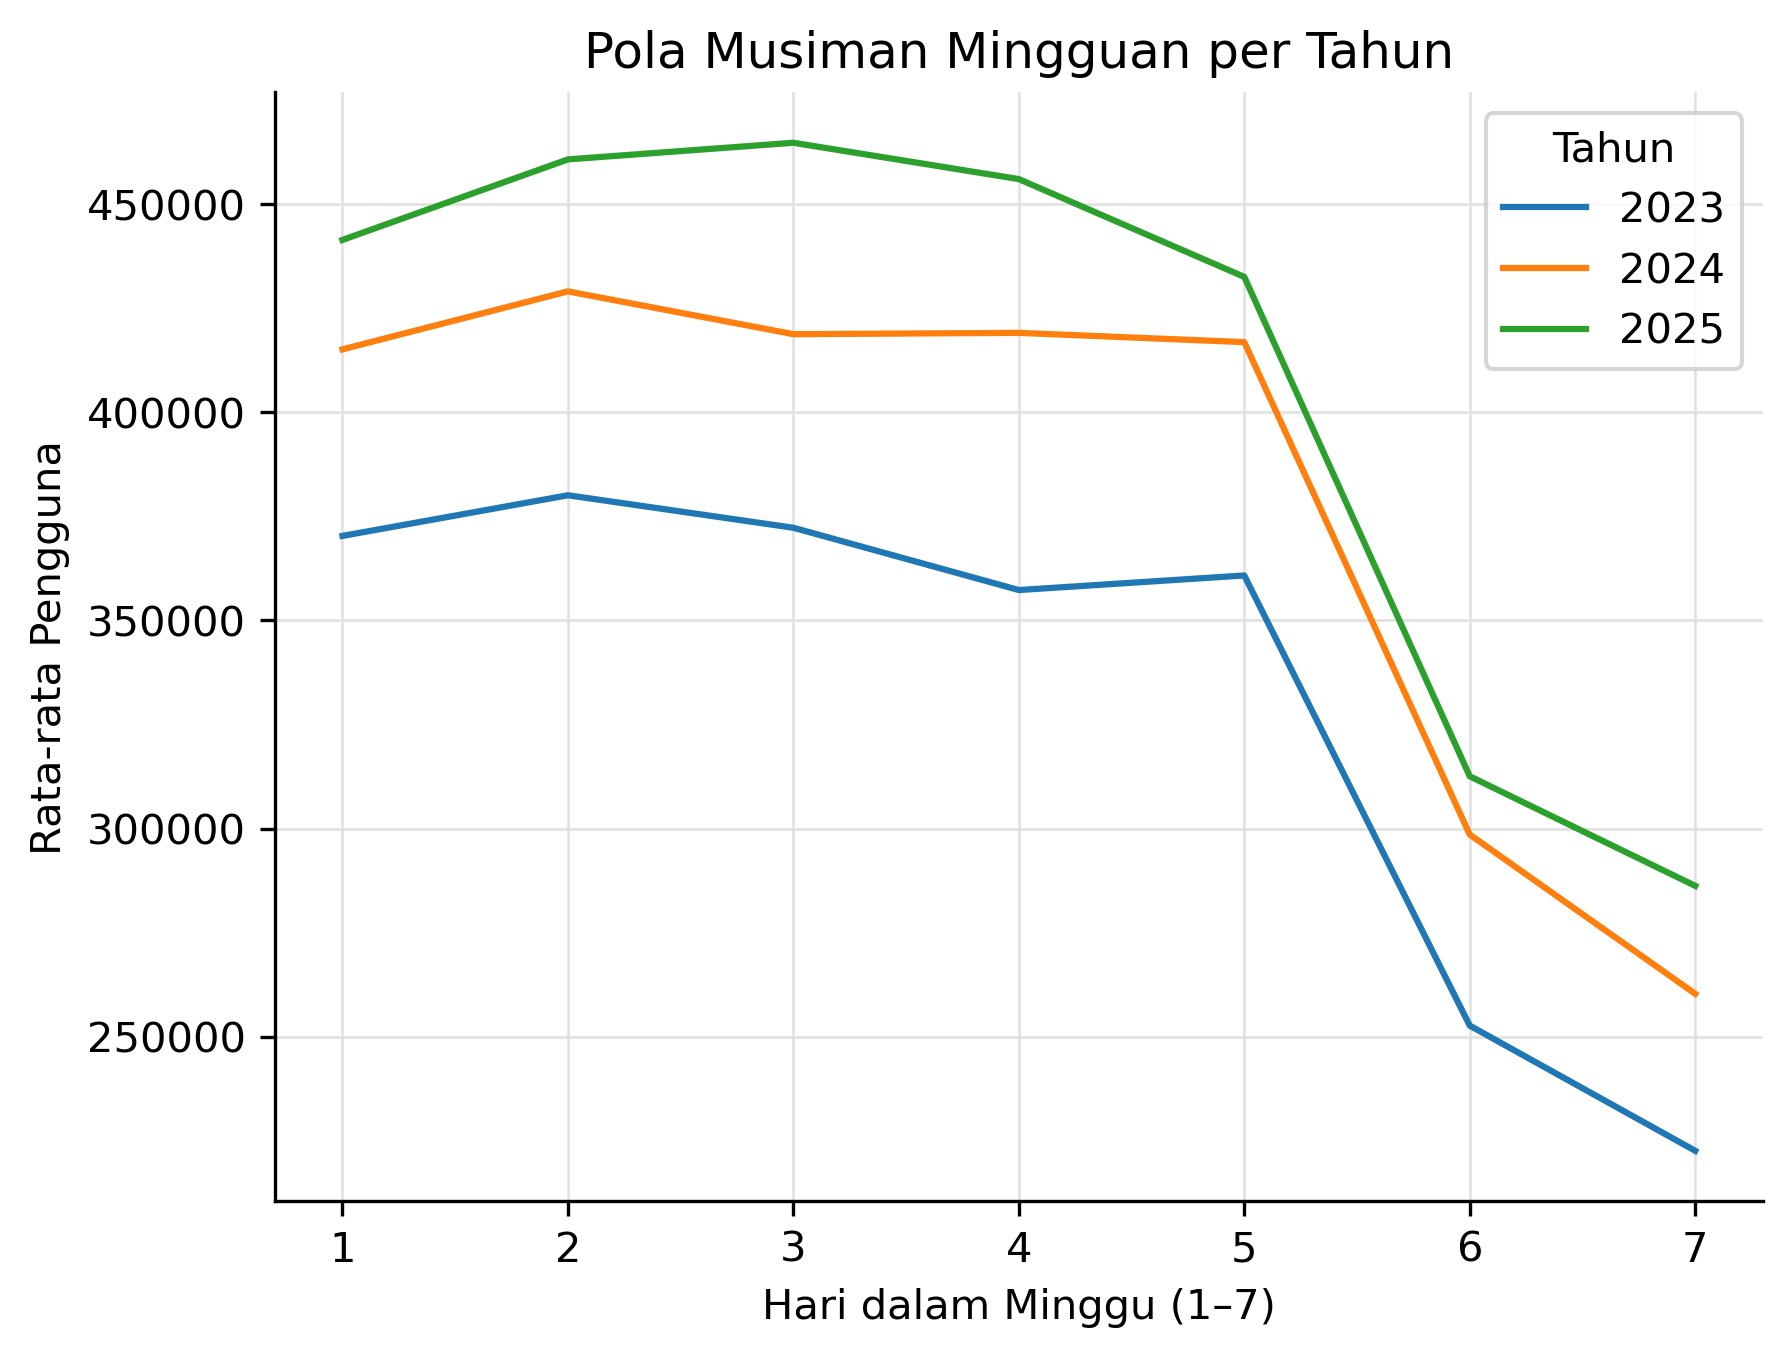

In [278]:
weekly_year = (
    df.groupby(['tahun','dow'])['pengguna']
      .mean()
      .unstack()
)
plt.figure(figsize=(10,5))
weekly_year.T.plot()
plt.title("Pola Musiman Mingguan per Tahun")
plt.xlabel("Hari dalam Minggu (1–7)")
plt.ylabel("Rata-rata Pengguna")
plt.legend(title="Tahun")
plt.show()

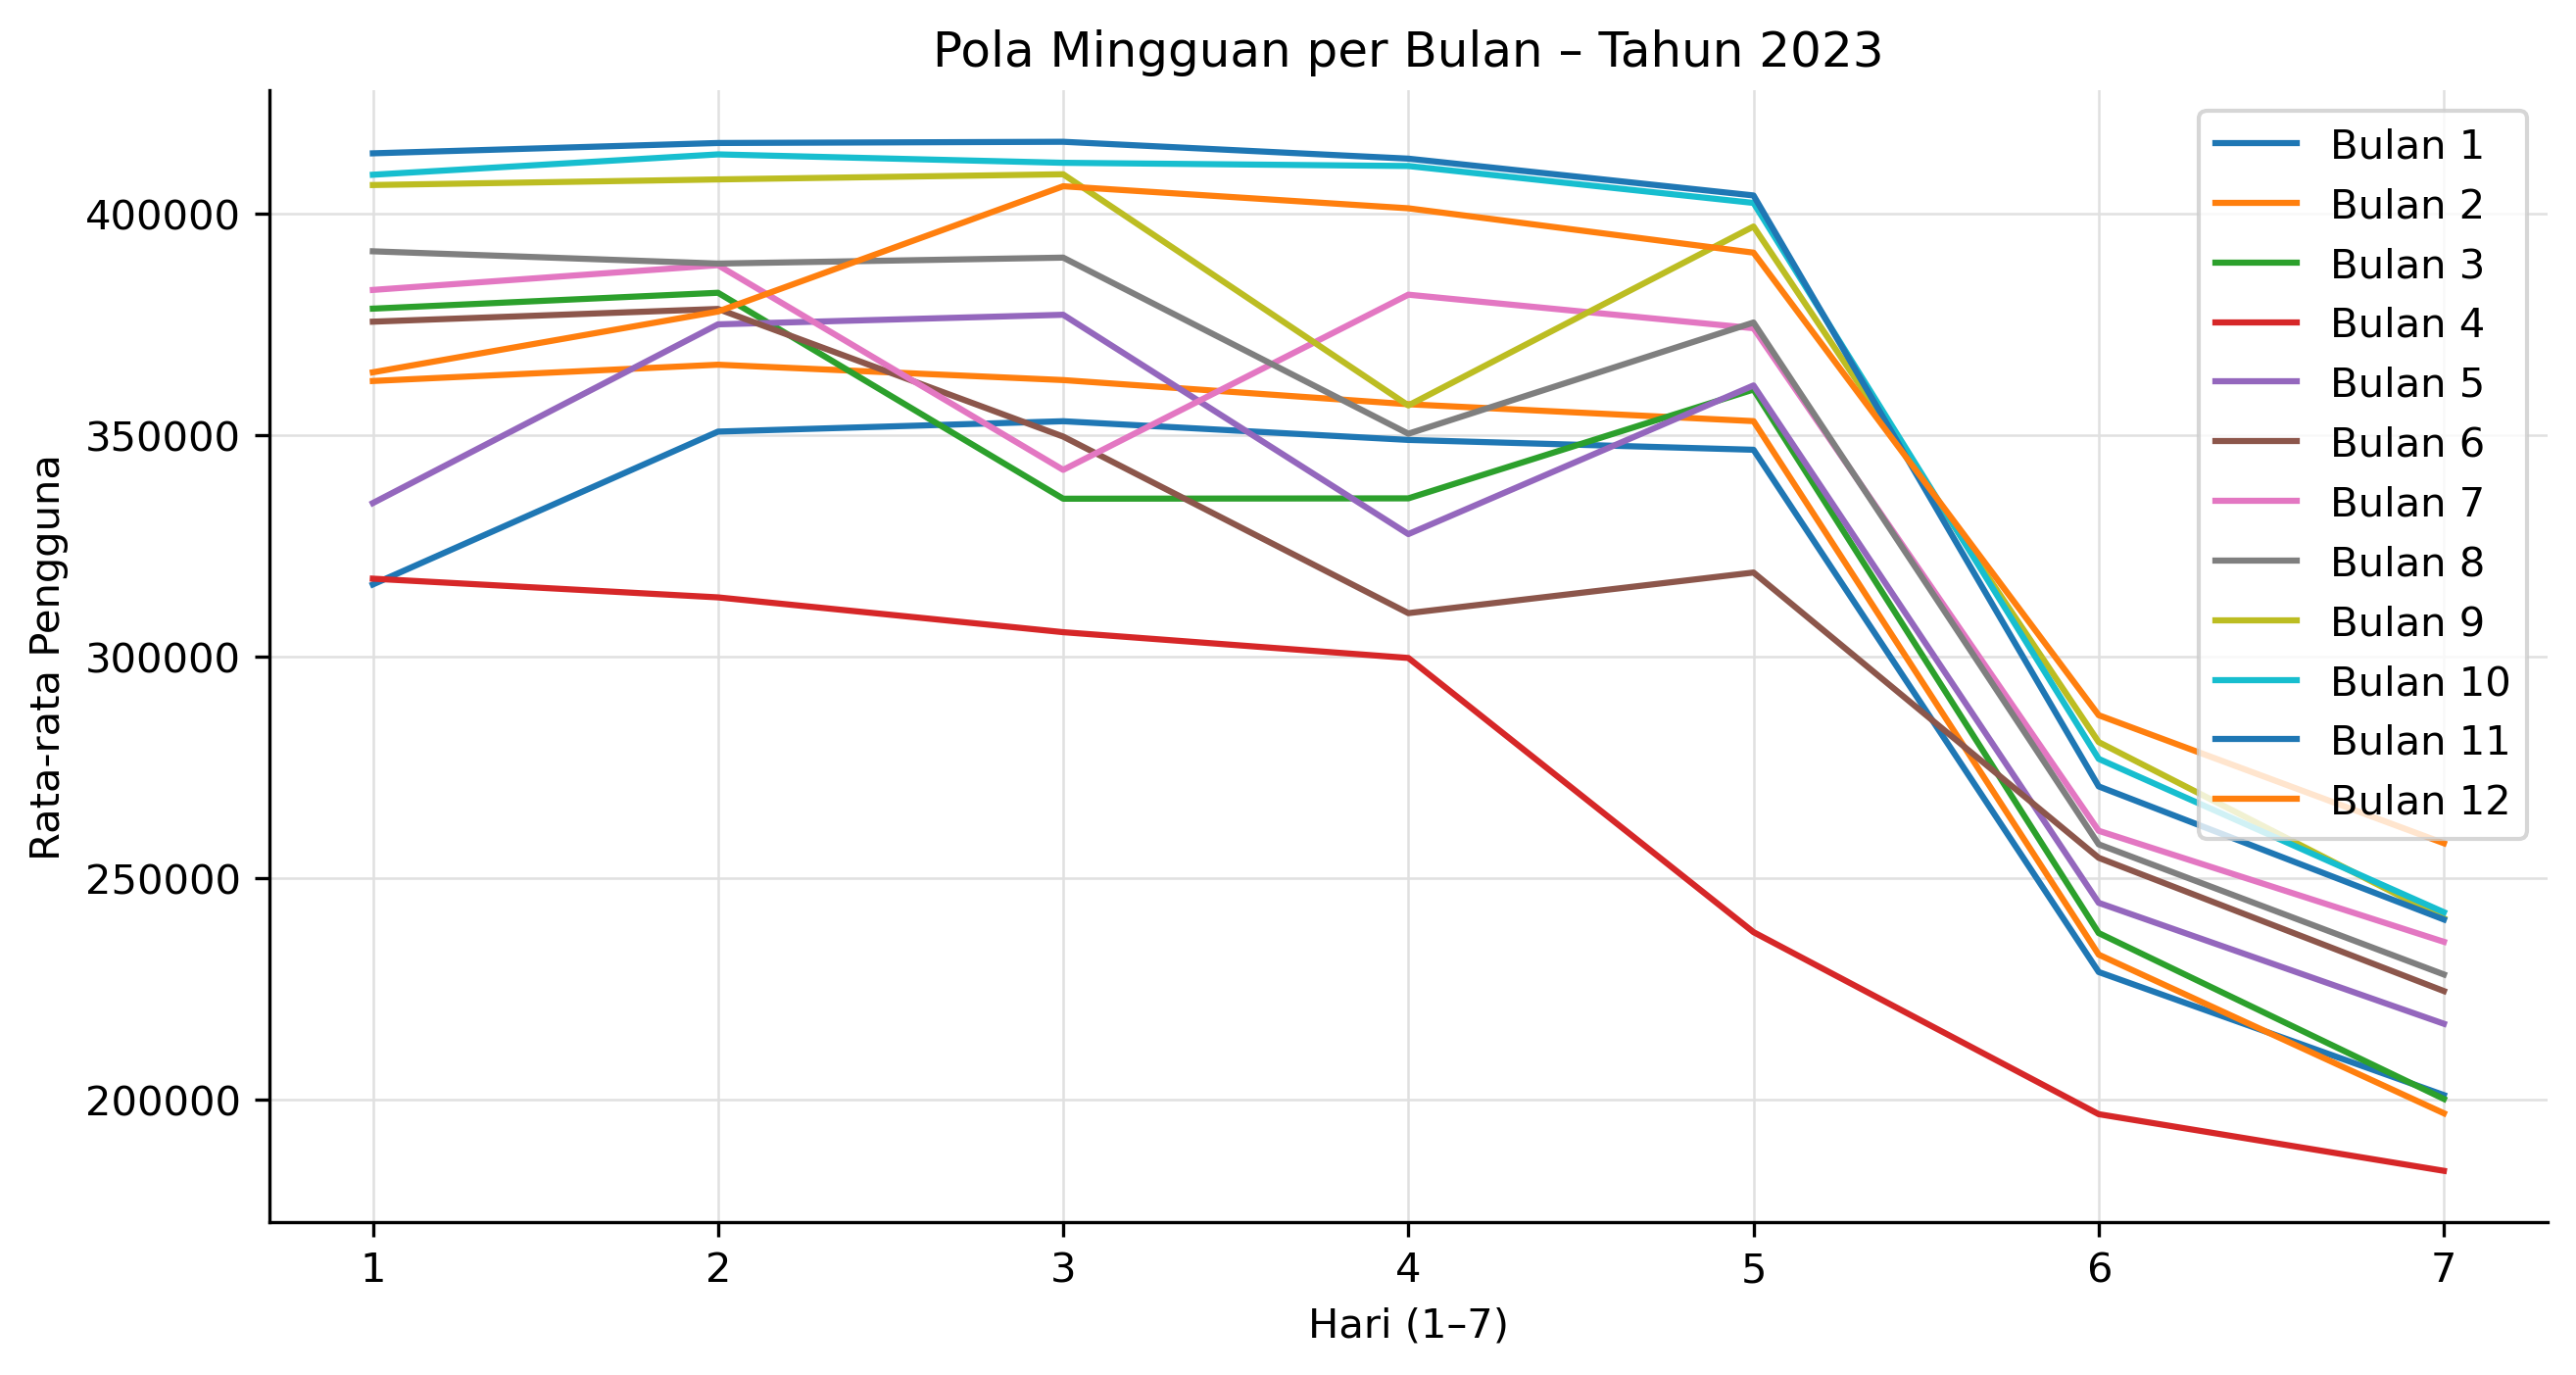

In [279]:
ym_dow = (
    df.groupby(['tahun','bulan','dow'])['pengguna']
      .mean()
      .reset_index()
)
ym_dow_pivot = ym_dow.pivot_table(
    index=['tahun','bulan'],
    columns='dow',
    values='pengguna'
)

data_2023 = ym_dow[ym_dow['tahun'] == 2023]

plt.figure(figsize=(10,5))
for b in sorted(data_2023['bulan'].unique()):
    tmp = data_2023[data_2023['bulan'] == b]
    plt.plot(tmp['dow'], tmp['pengguna'], label=f'Bulan {b}')

plt.title("Pola Mingguan per Bulan – Tahun 2023")
plt.xlabel("Hari (1–7)")
plt.ylabel("Rata-rata Pengguna")
plt.legend()
plt.show()

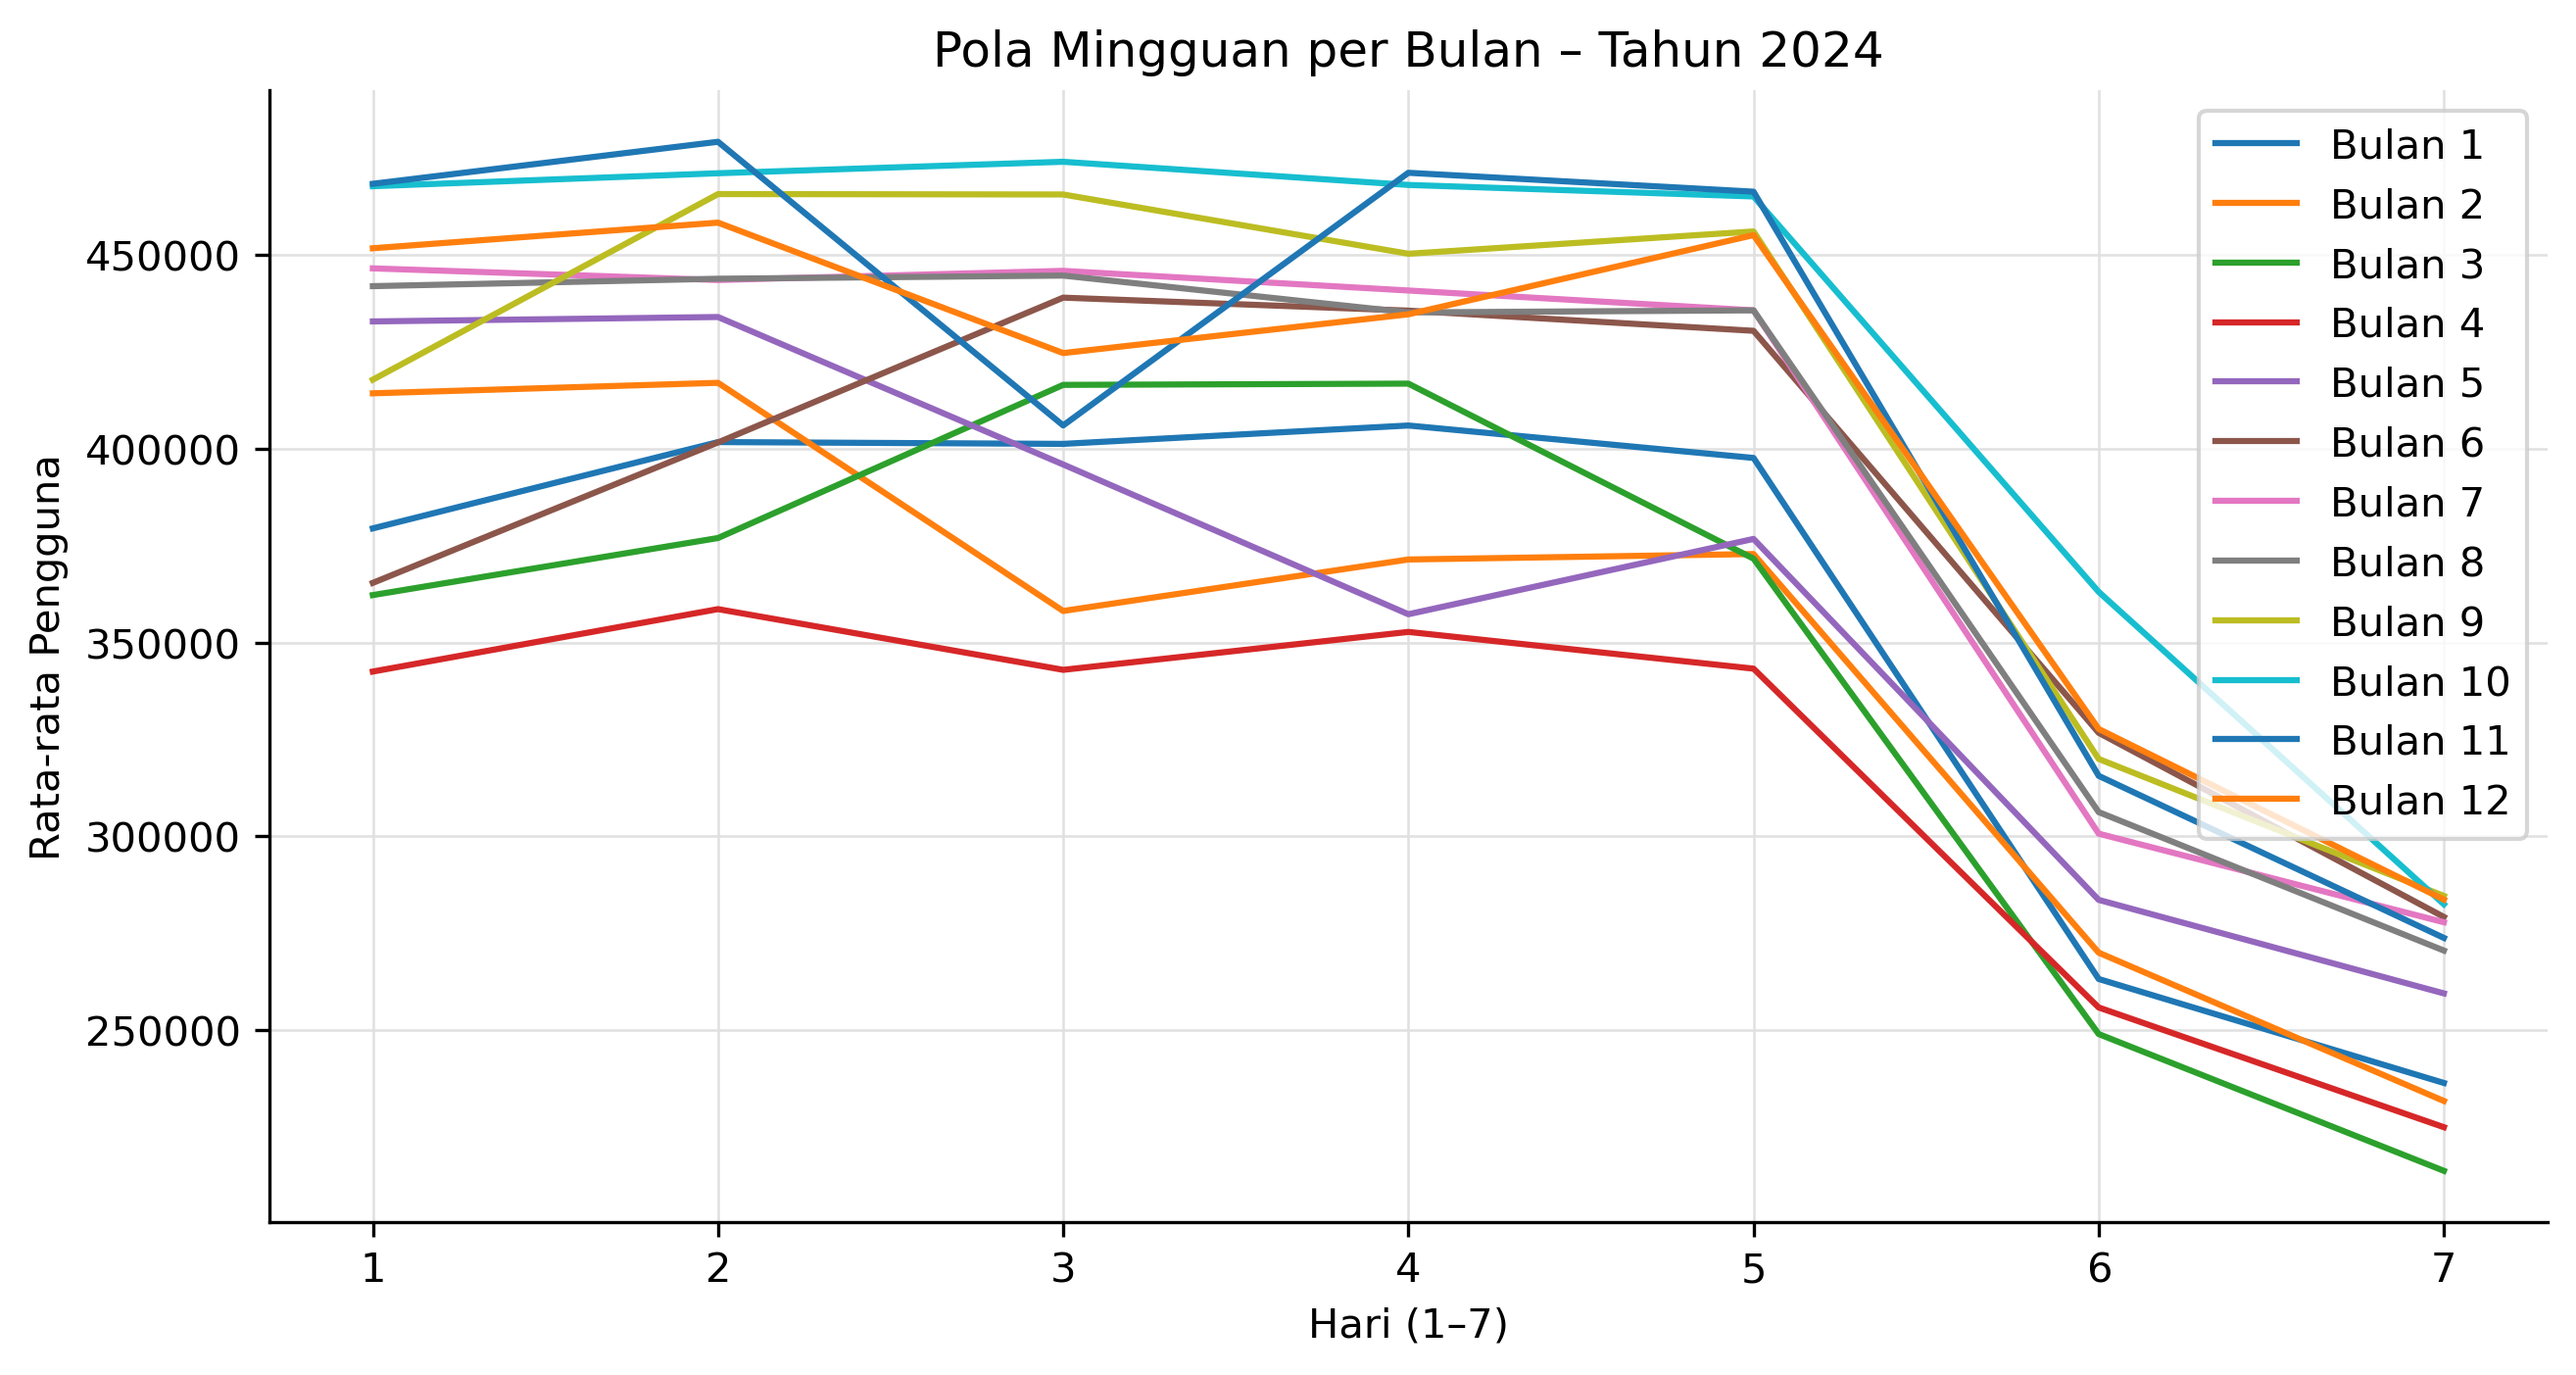

In [280]:

data_2024 = ym_dow[ym_dow['tahun'] == 2024]

plt.figure(figsize=(10,5))
for b in sorted(data_2024['bulan'].unique()):
    tmp = data_2024[data_2024['bulan'] == b]
    plt.plot(tmp['dow'], tmp['pengguna'], label=f'Bulan {b}')

plt.title("Pola Mingguan per Bulan – Tahun 2024")
plt.xlabel("Hari (1–7)")
plt.ylabel("Rata-rata Pengguna")
plt.legend()
plt.show()

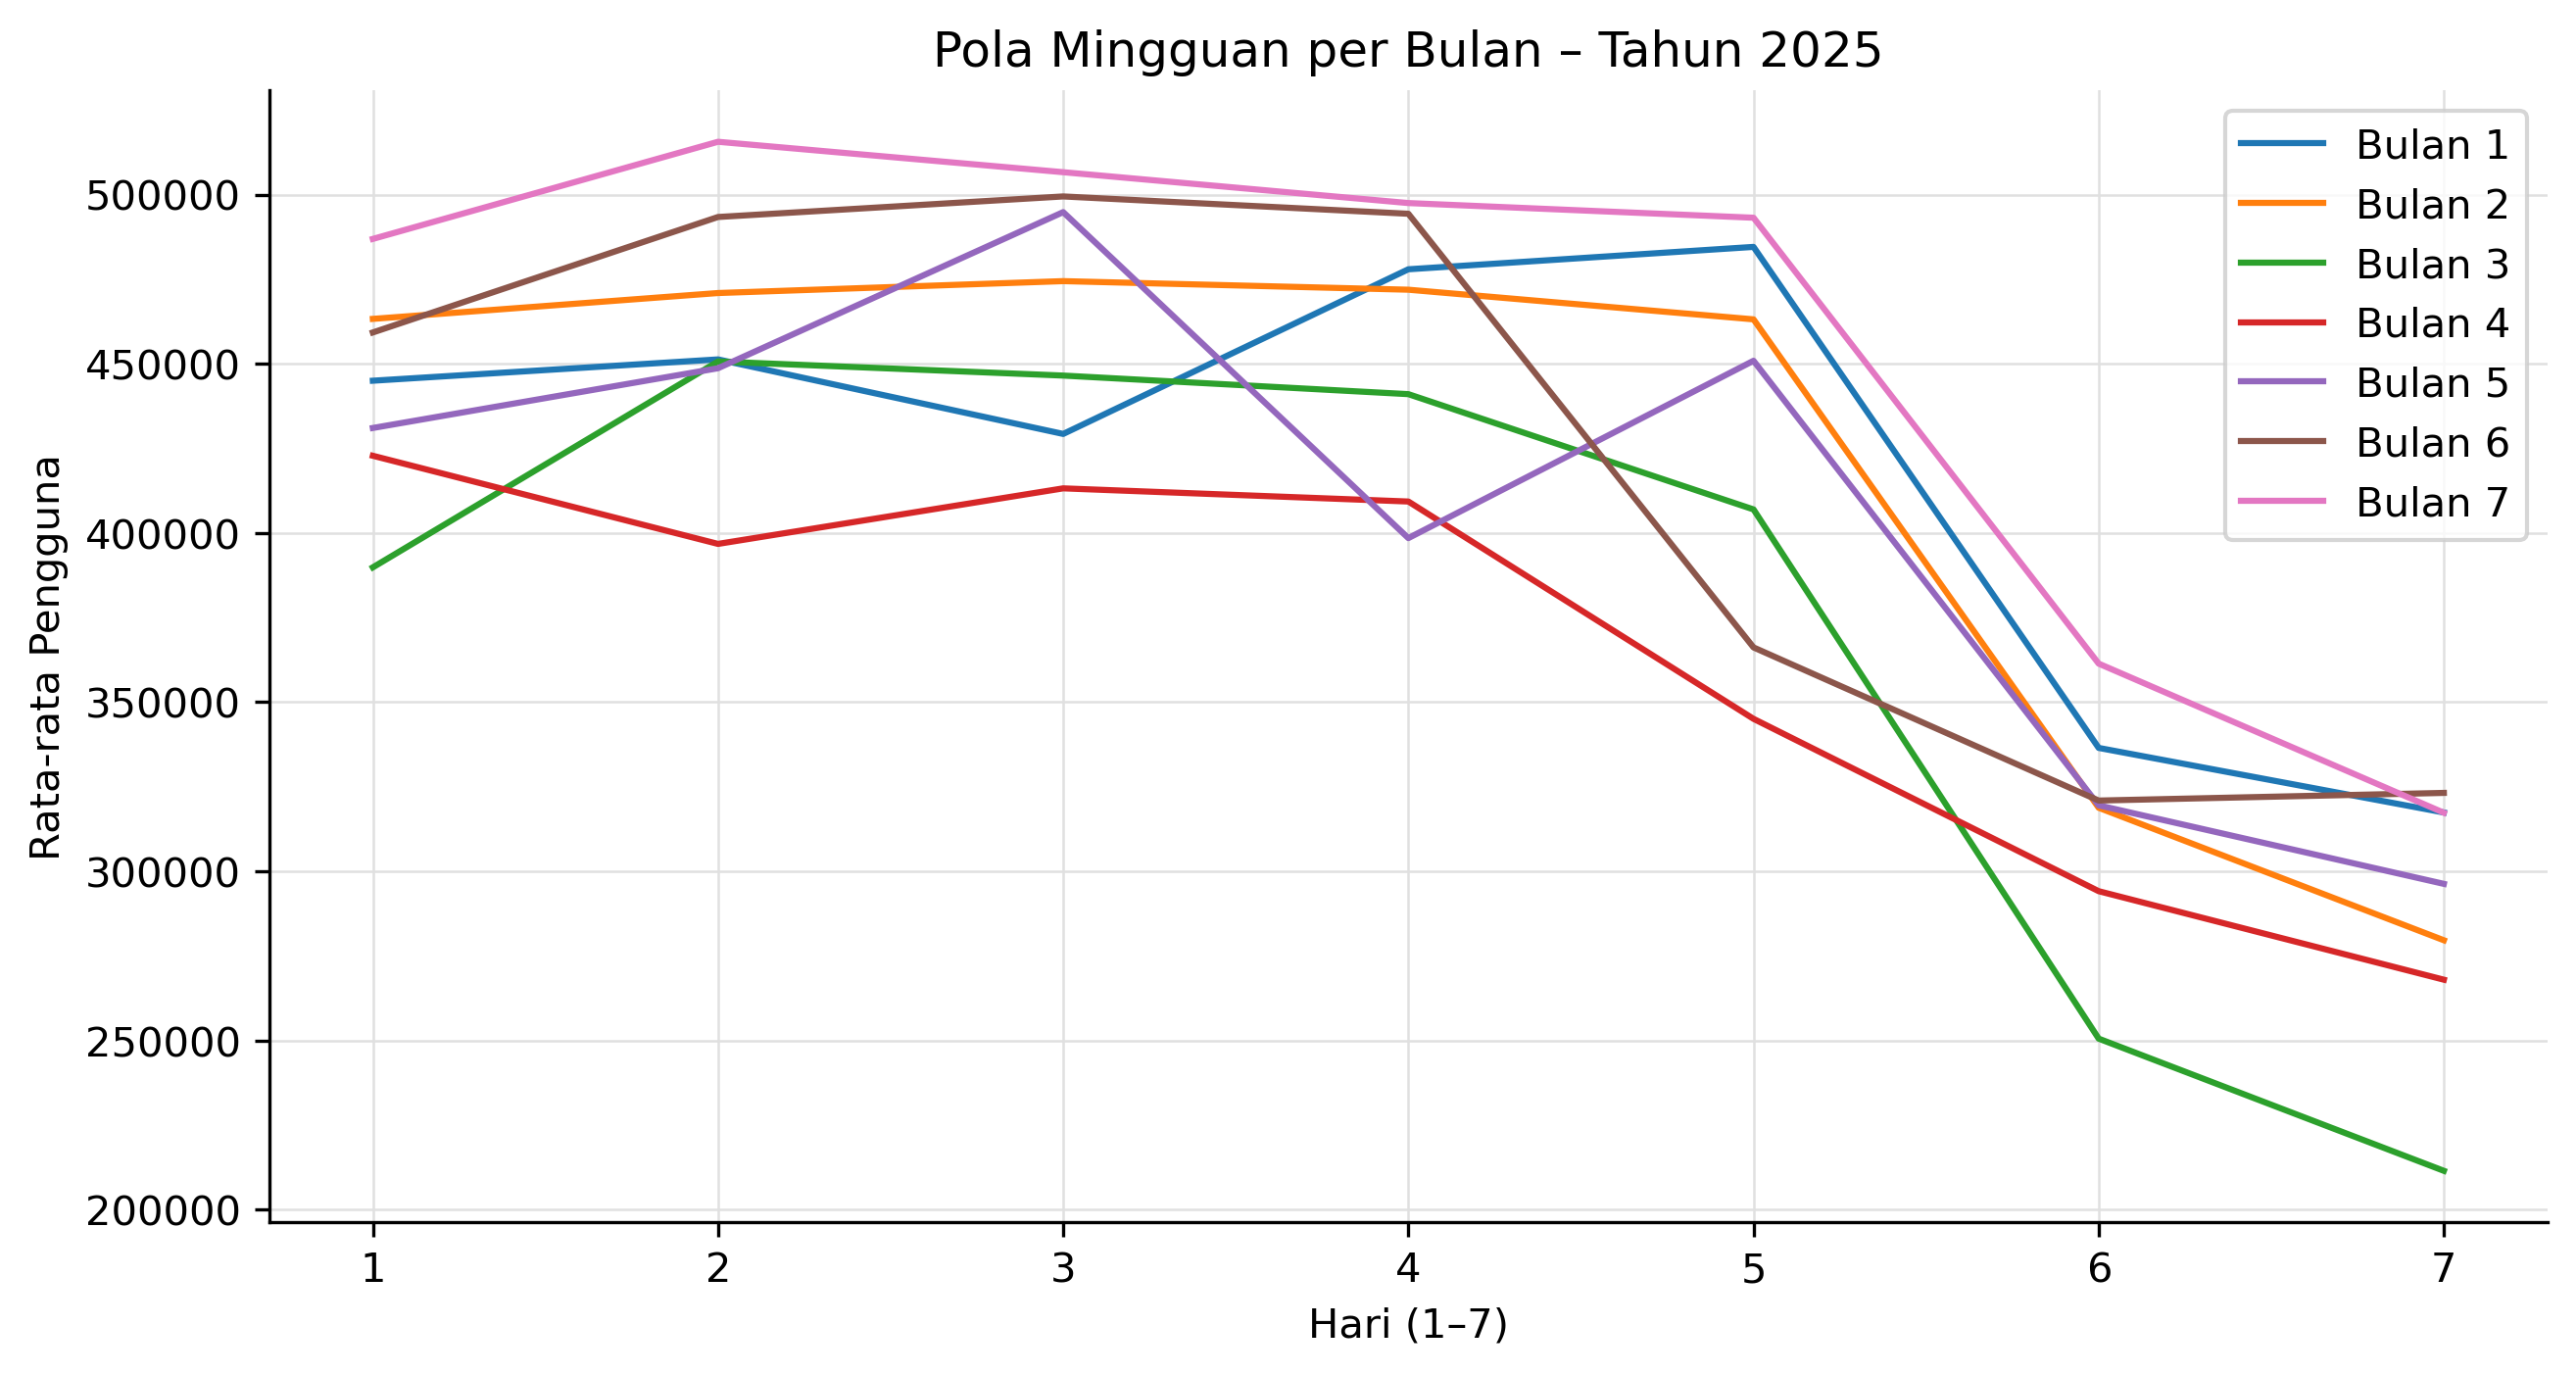

In [282]:
data_2025 = ym_dow[ym_dow['tahun'] == 2025]

plt.figure(figsize=(10,5))
for b in sorted(data_2025['bulan'].unique()):
    tmp = data_2025[data_2025['bulan'] == b]
    plt.plot(tmp['dow'], tmp['pengguna'], label=f'Bulan {b}')

plt.title("Pola Mingguan per Bulan – Tahun 2025")
plt.xlabel("Hari (1–7)")
plt.ylabel("Rata-rata Pengguna")
plt.legend()
plt.show()

# FEATURE ENGINEERING

In [7]:
df.columns

Index(['tanggal', 'tahun', 'bulan', 'hari', 'doy', 'pengguna', 'akhir_pekan',
       'libur_nasional', 'lebaran', 'promo_tarif', 'dow'],
      dtype='object')

In [8]:
df_fe=df.copy()
#df_fe['dow2'] = df_fe['tanggal'].dt.day
df_fe['sin_dow'] = np.sin(2 * np.pi * df_fe['dow'] / 7)
df_fe['cos_dow'] = np.cos(2 * np.pi * df_fe['dow'] / 7)


#df_fe['sin_month'] 


In [9]:
#df_fe=df.copy()

In [10]:
# Drop rows with NaN created by lag features
df_fe = df_fe.dropna()

print(f"Features created: {df_fe.shape[1]} columns")
print(f"setelah menghapus NaN: {df_fe.shape[0]}")

Features created: 13 columns
setelah menghapus NaN: 943


In [11]:
df_fe.head(21)

,tanggal,tahun,bulan,hari,doy,pengguna,akhir_pekan,libur_nasional,lebaran,promo_tarif,dow,sin_dow,cos_dow
0,2023-01-01,2023,1,1,1,184616,1,1,0,0,7,-2.449294e-16,1.000000
1,2023-01-02,2023,1,2,2,314296,0,0,0,0,1,7.818315e-01,0.623490
2,2023-01-03,2023,1,3,3,339823,0,0,0,0,2,9.749279e-01,-0.222521
3,2023-01-04,2023,1,4,4,348919,0,0,0,0,3,4.338837e-01,-0.900969
4,2023-01-05,2023,1,5,5,348914,0,0,0,0,4,-4.338837e-01,-0.900969
5,2023-01-06,2023,1,6,6,353928,0,0,0,0,5,-9.749279e-01,-0.222521
6,2023-01-07,2023,1,7,7,243228,1,0,0,0,6,-7.818315e-01,0.623490
7,2023-01-08,2023,1,8,8,207692,1,0,0,0,7,-2.449294e-16,1.000000
8,2023-01-09,2023,1,9,9,352644,0,0,0,0,1,7.818315e-01,0.623490
9,2023-01-10,2023,1,10,10,356003,0,0,0,0,2,9.749279e-01,-0.222521


In [12]:
df_fe.columns

Index(['tanggal', 'tahun', 'bulan', 'hari', 'doy', 'pengguna', 'akhir_pekan',
       'libur_nasional', 'lebaran', 'promo_tarif', 'dow', 'sin_dow',
       'cos_dow'],
      dtype='object')

# SPLIT DATA 

In [14]:
df2=df_fe.copy()

In [15]:
df2 = df2.reset_index()
df2['tanggal'] = pd.to_datetime(df2['tanggal'])
df2 = df2.set_index('tanggal')
if pd.__version__ < '2.2':
    data = data.asfreq('D')
else:
    df2 = df2.asfreq('d')
df2 = df2.sort_index()
df2.head(21)


,index,tahun,bulan,hari,doy,pengguna,akhir_pekan,libur_nasional,lebaran,promo_tarif,dow,sin_dow,cos_dow
tanggal,,,,,,,,,,,,,
2023-01-01,0,2023,1,1,1,184616,1,1,0,0,7,-2.449294e-16,1.000000
2023-01-02,1,2023,1,2,2,314296,0,0,0,0,1,7.818315e-01,0.623490
2023-01-03,2,2023,1,3,3,339823,0,0,0,0,2,9.749279e-01,-0.222521
2023-01-04,3,2023,1,4,4,348919,0,0,0,0,3,4.338837e-01,-0.900969
2023-01-05,4,2023,1,5,5,348914,0,0,0,0,4,-4.338837e-01,-0.900969
2023-01-06,5,2023,1,6,6,353928,0,0,0,0,5,-9.749279e-01,-0.222521
2023-01-07,6,2023,1,7,7,243228,1,0,0,0,6,-7.818315e-01,0.623490
2023-01-08,7,2023,1,8,8,207692,1,0,0,0,7,-2.449294e-16,1.000000
2023-01-09,8,2023,1,9,9,352644,0,0,0,0,1,7.818315e-01,0.623490


In [16]:
df2 .head(21)

,index,tahun,bulan,hari,doy,pengguna,akhir_pekan,libur_nasional,lebaran,promo_tarif,dow,sin_dow,cos_dow
tanggal,,,,,,,,,,,,,
2023-01-01,0,2023,1,1,1,184616,1,1,0,0,7,-2.449294e-16,1.000000
2023-01-02,1,2023,1,2,2,314296,0,0,0,0,1,7.818315e-01,0.623490
2023-01-03,2,2023,1,3,3,339823,0,0,0,0,2,9.749279e-01,-0.222521
2023-01-04,3,2023,1,4,4,348919,0,0,0,0,3,4.338837e-01,-0.900969
2023-01-05,4,2023,1,5,5,348914,0,0,0,0,4,-4.338837e-01,-0.900969
2023-01-06,5,2023,1,6,6,353928,0,0,0,0,5,-9.749279e-01,-0.222521
2023-01-07,6,2023,1,7,7,243228,1,0,0,0,6,-7.818315e-01,0.623490
2023-01-08,7,2023,1,8,8,207692,1,0,0,0,7,-2.449294e-16,1.000000
2023-01-09,8,2023,1,9,9,352644,0,0,0,0,1,7.818315e-01,0.623490


In [17]:
# Split train-validation-test
# ==============================================================================
end_train = '2025-03-31 23:59:00'
end_validation = '2025-05-31 23:59:00'
data_train = df2.loc[: end_train, :]
data_val   = df2.loc[end_train:end_validation, :]
data_test  = df2.loc[end_validation:, :]

print(f"Dates train      : {data_train.index.min()} --- {data_train.index.max()}  (n={len(data_train)})")
print(f"Dates validation : {data_val.index.min()} --- {data_val.index.max()}  (n={len(data_val)})")
print(f"Dates test       : {data_test.index.min()} --- {data_test.index.max()}  (n={len(data_test)})")


Dates train      : 2023-01-01 00:00:00 --- 2025-03-31 00:00:00  (n=821)
Dates validation : 2025-04-01 00:00:00 --- 2025-05-31 00:00:00  (n=61)
Dates test       : 2025-06-01 00:00:00 --- 2025-07-31 00:00:00  (n=61)


In [18]:
data_train

,index,tahun,bulan,hari,doy,pengguna,akhir_pekan,libur_nasional,lebaran,promo_tarif,dow,sin_dow,cos_dow
tanggal,,,,,,,,,,,,,
2023-01-01,0,2023,1,1,1,184616,1,1,0,0,7,-2.449294e-16,1.000000
2023-01-02,1,2023,1,2,2,314296,0,0,0,0,1,7.818315e-01,0.623490
2023-01-03,2,2023,1,3,3,339823,0,0,0,0,2,9.749279e-01,-0.222521
2023-01-04,3,2023,1,4,4,348919,0,0,0,0,3,4.338837e-01,-0.900969
2023-01-05,4,2023,1,5,5,348914,0,0,0,0,4,-4.338837e-01,-0.900969
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-03-27,816,2025,3,27,86,370730,0,0,0,0,4,-4.338837e-01,-0.900969
2025-03-28,817,2025,3,28,87,261056,0,1,0,0,5,-9.749279e-01,-0.222521
2025-03-29,818,2025,3,29,88,182986,1,0,1,0,6,-7.818315e-01,0.623490


In [19]:
data_val

,index,tahun,bulan,hari,doy,pengguna,akhir_pekan,libur_nasional,lebaran,promo_tarif,dow,sin_dow,cos_dow
tanggal,,,,,,,,,,,,,
2025-04-01,821,2025,4,1,91,196803,0,1,0,0,2,0.974928,-0.222521
2025-04-02,822,2025,4,2,92,235382,0,1,0,0,3,0.433884,-0.900969
2025-04-03,823,2025,4,3,93,252259,0,1,0,0,4,-0.433884,-0.900969
2025-04-04,824,2025,4,4,94,239899,0,1,0,0,5,-0.974928,-0.222521
2025-04-05,825,2025,4,5,95,241917,1,0,0,0,6,-0.781831,0.623490
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-05-27,877,2025,5,27,147,483747,0,0,0,0,2,0.974928,-0.222521
2025-05-28,878,2025,5,28,148,498894,0,0,0,0,3,0.433884,-0.900969
2025-05-29,879,2025,5,29,149,273087,0,1,0,0,4,-0.433884,-0.900969


In [21]:
data_test

,index,tahun,bulan,hari,doy,pengguna,akhir_pekan,libur_nasional,lebaran,promo_tarif,dow,sin_dow,cos_dow
tanggal,,,,,,,,,,,,,
2025-06-01,882,2025,6,1,152,290405,1,1,0,0,7,-2.449294e-16,1.000000
2025-06-02,883,2025,6,2,153,486281,0,0,0,0,1,7.818315e-01,0.623490
2025-06-03,884,2025,6,3,154,492714,0,0,0,0,2,9.749279e-01,-0.222521
2025-06-04,885,2025,6,4,155,501444,0,0,0,0,3,4.338837e-01,-0.900969
2025-06-05,886,2025,6,5,156,497127,0,0,0,0,4,-4.338837e-01,-0.900969
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-27,938,2025,7,27,208,298335,1,0,0,0,7,-2.449294e-16,1.000000
2025-07-28,939,2025,7,28,209,476862,0,0,0,0,1,7.818315e-01,0.623490
2025-07-29,940,2025,7,29,210,490471,0,0,0,0,2,9.749279e-01,-0.222521


In [22]:
data_train.columns

Index(['index', 'tahun', 'bulan', 'hari', 'doy', 'pengguna', 'akhir_pekan',
       'libur_nasional', 'lebaran', 'promo_tarif', 'dow', 'sin_dow',
       'cos_dow'],
      dtype='object')

In [26]:
y_train = data_train['pengguna']
y_test  = data_test['pengguna']
y_val   = data_val['pengguna']

X_train = data_train.drop(columns=['tahun','index', 'bulan','hari','pengguna','akhir_pekan','dow','doy'])#,,'sin_dow','cos_dow'])
X_test  = data_test.drop(columns=[ 'tahun','index', 'bulan','hari','pengguna','akhir_pekan','dow','doy'])#,'sin_dow','cos_dow'])
X_val   = data_val.drop(columns=[ 'tahun','index', 'bulan','hari','pengguna','akhir_pekan','dow','doy'])#,'sin_dow','cos_dow'])


In [34]:
X_trainh = data_train.drop(columns=['tahun','index', 'bulan','hari','pengguna','akhir_pekan','dow','doy','sin_dow','cos_dow'])
X_testh  = data_test.drop(columns=[ 'tahun','index', 'bulan','hari','pengguna','akhir_pekan','dow','doy','sin_dow','cos_dow'])
X_valh   = data_val.drop(columns=[ 'tahun','index', 'bulan','hari','pengguna','akhir_pekan','dow','doy','sin_dow','cos_dow'])


In [42]:
X_train

,libur_nasional,lebaran,promo_tarif,sin_dow,cos_dow
tanggal,,,,,
2023-01-01,1,0,0,-2.449294e-16,1.000000
2023-01-02,0,0,0,7.818315e-01,0.623490
2023-01-03,0,0,0,9.749279e-01,-0.222521
2023-01-04,0,0,0,4.338837e-01,-0.900969
2023-01-05,0,0,0,-4.338837e-01,-0.900969
...,...,...,...,...,...
2025-03-27,0,0,0,-4.338837e-01,-0.900969
2025-03-28,1,0,0,-9.749279e-01,-0.222521
2025-03-29,0,1,0,-7.818315e-01,0.623490


# LIGHTGBM

In [46]:
variabel_dummy = [
    'libur_nasional',
    'lebaran',
    'promo_tarif'
]

jumlah_value = df[variabel_dummy].apply(pd.Series.value_counts).fillna(0).astype(int)

print(jumlah_value)

   libur_nasional  lebaran  promo_tarif
0             875      931          933
1              68       12           10


# DENGAN ROLL STAT

In [49]:
from skforecast.recursive import ForecasterRecursive
from skforecast.model_selection import TimeSeriesFold, bayesian_search_forecaster
from lightgbm import LGBMRegressor

window_features = RollingFeatures(
    stats=["mean", "std"],
    window_sizes=[7, 7]
)

forecaster = ForecasterRecursive(
    estimator=LGBMRegressor(random_state=42, verbose=-1),
    lags=14,#[1,2,3,7, 14, 21],
    window_features=window_features,
)

lags_grid = [
    [1,2,3,7,14,21],
    [1,2,7,14,21],
    [1,7,14,21],
    [1,2,3,7],
    [1,2,3,7,14],
    [1,2,7,14],
    [1,7,14],
    [1,2,7],
    [1,7],
    [1,2,3],
    [1,2]
    #[1,2,3,4,5,6,7],
    #[1,2,3,4,5]
]

def search_space(trial):

    search_space = {
        'n_estimators'    : trial.suggest_int('n_estimators', 100, 500),
        'max_depth'       : trial.suggest_int('max_depth', 3, 7),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 20, 50),
        'learning_rate'   : trial.suggest_float('learning_rate', 0.01, 0.1),
        'num_leaves'      : trial.suggest_int('num_leaves', 2, 50),
        'reg_alpha'       : trial.suggest_float('reg_alpha', 0, 1, step=0.1),
        'reg_lambda'      : trial.suggest_float('reg_lambda', 0, 1, step=0.1),
        'lags'            : trial.suggest_categorical('lags', lags_grid)
    }
    return search_space

cv_search = TimeSeriesFold(
    steps=61,
    initial_train_size=638,
    fixed_train_size=False,
    refit=True,
)

results_search, frozen_trial = bayesian_search_forecaster(
    forecaster=forecaster,
    y=pd.concat([y_train, y_val]),
    exog=pd.concat([X_train, X_val]),
    cv=cv_search,
    search_space=search_space,
    metric='mean_absolute_error',#'mean_absolute_percentage_error'],
    n_trials=75,
    random_state=42,
    return_best=True
)

best_params = results_search['params'].iat[0]
best_params = best_params | {'random_state': 42, 'verbose': -1}
best_lags = results_search['lags'].iat[0]

print("Best params:", best_params)
print("Best lags:", best_lags)

  0%|          | 0/75 [00:00<?, ?it/s]

Best params: {'n_estimators': 472, 'max_depth': 7, 'min_data_in_leaf': 21, 'learning_rate': 0.08940425812764564, 'num_leaves': 38, 'reg_alpha': 0.9, 'reg_lambda': 0.30000000000000004, 'random_state': 42, 'verbose': -1}
Best lags: [ 1  7 14 21]


In [116]:
X_test

,libur_nasional,lebaran,promo_tarif,sin_dow,cos_dow
tanggal,,,,,
2025-06-01,1,0,0,-2.449294e-16,1.000000
2025-06-02,0,0,0,7.818315e-01,0.623490
2025-06-03,0,0,0,9.749279e-01,-0.222521
2025-06-04,0,0,0,4.338837e-01,-0.900969
2025-06-05,0,0,0,-4.338837e-01,-0.900969
...,...,...,...,...,...
2025-07-27,0,0,0,-2.449294e-16,1.000000
2025-07-28,0,0,0,7.818315e-01,0.623490
2025-07-29,0,0,0,9.749279e-01,-0.222521


In [50]:
results_search.head(50)

,trial_number,lags,params,mean_absolute_error,n_estimators,max_depth,min_data_in_leaf,learning_rate,num_leaves,reg_alpha,reg_lambda
0,59,"[1, 7, 14, 21]","{'n_estimators': 472, 'max_depth': 7, 'min_dat...",35101.652582,472.0,7.0,21.0,0.089404,38.0,0.9,0.3
1,61,"[1, 7, 14, 21]","{'n_estimators': 481, 'max_depth': 7, 'min_dat...",37223.152578,481.0,7.0,27.0,0.080861,40.0,0.9,0.4
2,54,"[1, 2, 3, 7, 14, 21]","{'n_estimators': 253, 'max_depth': 7, 'min_dat...",37662.488032,253.0,7.0,20.0,0.023716,27.0,0.5,0.6
3,65,"[1, 2, 3, 7, 14, 21]","{'n_estimators': 489, 'max_depth': 7, 'min_dat...",38192.132644,489.0,7.0,22.0,0.016193,48.0,0.5,0.4
4,39,"[1, 2, 7, 14, 21]","{'n_estimators': 320, 'max_depth': 6, 'min_dat...",38226.072882,320.0,6.0,28.0,0.030900,37.0,0.4,0.7
5,35,"[1, 2, 7, 14, 21]","{'n_estimators': 309, 'max_depth': 6, 'min_dat...",38464.854591,309.0,6.0,26.0,0.024534,41.0,0.6,0.6
6,48,"[1, 2, 3, 7, 14, 21]","{'n_estimators': 371, 'max_depth': 7, 'min_dat...",38511.773380,371.0,7.0,20.0,0.025912,32.0,0.5,0.7
7,52,"[1, 2, 3, 7, 14, 21]","{'n_estimators': 399, 'max_depth': 7, 'min_dat...",38810.686072,399.0,7.0,21.0,0.026099,33.0,0.5,0.6
8,68,"[1, 7, 14, 21]","{'n_estimators': 423, 'max_depth': 7, 'min_dat...",38935.704485,423.0,7.0,26.0,0.085619,39.0,0.6,0.5
9,47,"[1, 7, 14, 21]","{'n_estimators': 496, 'max_depth': 7, 'min_dat...",39178.699271,496.0,7.0,21.0,0.077173,40.0,1.0,0.3


## EVALUASI LIGHTGBM HASIL TUNNING PARAMETER

In [50]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    root_mean_squared_error
)

# Fit model final menggunakan train + validation
forecaster.fit(
    y=pd.concat([y_train, y_val]),
    exog=pd.concat([X_train, X_val])
)

# Prediksi data testing
pred_lgbm = forecaster.predict(
    steps=len(y_test),
    exog=X_test
)

# Evaluasi pada data testing
mape_lgbm = mean_absolute_percentage_error(
    y_test, pred_lgbm
) * 100

mae_lgbm = mean_absolute_error(
    y_test, pred_lgbm
)

rmse_lgbm = root_mean_squared_error(
    y_test, pred_lgbm
)

print(f"MAPE: {mape_lgbm:.4f}%")
print(f"MAE: {mae_lgbm:.2f}")
print(f"RMSE: {rmse_lgbm:.2f}")

MAPE: 7.8895%
MAE: 27439.20
RMSE: 48278.42


In [51]:
from sklearn.metrics import r2_score

# y_true = nilai aktual
# y_pred = hasil prediksi model

r2 = r2_score(y_test, pred_lgbm)

print("R² =", r2)

R² = 0.6979035524014479


## VISUALISASI DATA AKTUAL VS DATA PREDIKSI LIGHTGBM

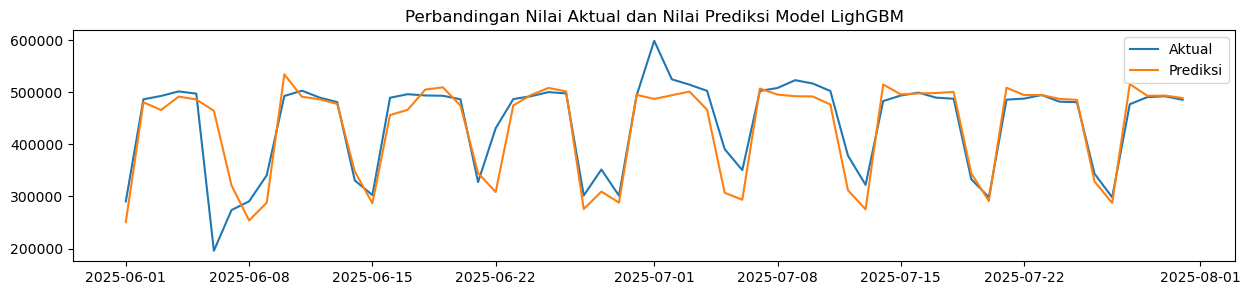

In [52]:
plt.figure(figsize=(15,3))
y_true_1=y_test
plt.plot(
    y_true_1.tail(61).index,
    y_true_1.tail(61).values,
    label='Aktual'
)

plt.plot(
    y_true_1.tail(61).index,
    pred_lgbm,
    label='Prediksi'
)

plt.legend()
plt.title('Perbandingan Nilai Aktual dan Nilai Prediksi Model LighGBM')
plt.show()

In [67]:
pred_lgbm.head(30)

2025-06-01    250830.064062
2025-06-02    480504.054267
2025-06-03    465759.949744
2025-06-04    491491.610248
2025-06-05    485993.968779
2025-06-06    464259.556721
2025-06-07    321251.823366
2025-06-08    253923.059579
2025-06-09    287883.628101
2025-06-10    534145.455000
2025-06-11    491143.134602
2025-06-12    486362.307447
2025-06-13    477512.871833
2025-06-14    347904.475185
2025-06-15    286913.103858
2025-06-16    456044.250042
2025-06-17    466044.020668
2025-06-18    504887.980636
2025-06-19    509291.329160
2025-06-20    474247.729242
2025-06-21    344758.079384
2025-06-22    308417.979336
2025-06-23    474537.595971
2025-06-24    494535.079492
2025-06-25    508047.116432
2025-06-26    501481.887766
2025-06-27    275810.578347
2025-06-28    309304.569698
2025-06-29    288178.621324
2025-06-30    494853.362407
Freq: D, Name: pred, dtype: float64

In [54]:
import pandas as pd

df_pred = pd.DataFrame({
    'Prediksi_LightGBM': pred_lgbm
})

df_pred.to_excel('prediksi_lgbm_terbaru2.xlsx', index=False)

# HYBRID

## DATA

In [69]:
#residual=pd.read_csv('resid_train.csv')
#residual=pd.read_csv('resid_train6g.csv')
residual=pd.read_csv('resid_train6i.csv')

residual

,tanggal,residual_sarimax
0,2023-01-01,16.066574
1,2023-01-02,7.095602
2,2023-01-03,6.134597
3,2023-01-04,5.120260
4,2023-01-05,4.084246
...,...,...
877,2025-05-27,564.188171
878,2025-05-28,1508.696087
879,2025-05-29,-4066.702198
880,2025-05-30,2130.510508


## FEATURES ENGINEERING

In [72]:
df6=df_fe.copy()

df6['lag_1']  = df6['pengguna'].shift(1)
df6['lag_2']  = df6['pengguna'].shift(2)
df6['lag_3']  = df6['pengguna'].shift(3)
df6['lag_7']  = df6['pengguna'].shift(7)
df6['lag_14'] = df6['pengguna'].shift(14)
df6['lag_21'] = df6['pengguna'].shift(21)

# Rolling features
df6['roll_mean_7'] = df6['pengguna'].shift(1).rolling(window=7).mean()
df6['roll_std_7']  = df6['pengguna'].shift(1).rolling(window=7).std()

# Drop baris yang masih ada NaN
df7= df6.dropna()

print(df7.head(10))

      tanggal  tahun  bulan  hari  doy  pengguna  akhir_pekan  libur_nasional  \
21 2023-01-22   2023      1    22   22    209790            1               1   
22 2023-01-23   2023      1    23   23    215476            0               1   
23 2023-01-24   2023      1    24   24    354516            0               0   
24 2023-01-25   2023      1    25   25    352487            0               0   
25 2023-01-26   2023      1    26   26    348169            0               0   
26 2023-01-27   2023      1    27   27    345249            0               0   
27 2023-01-28   2023      1    28   28    210053            1               0   
28 2023-01-29   2023      1    29   29    197003            1               0   
29 2023-01-30   2023      1    30   30    349756            0               0   
30 2023-01-31   2023      1    31   31    351163            0               0   

    lebaran  promo_tarif  ...       sin_dow   cos_dow     lag_1     lag_2  \
21        0            0  ... -

In [74]:
df4=residual.copy()

In [76]:


df4['lag_1']  = df4['residual_sarimax'].shift(1)
df4['lag_2']  = df4['residual_sarimax'].shift(2)
df4['lag_3']  = df4['residual_sarimax'].shift(3)
df4['lag_7']  = df4['residual_sarimax'].shift(7)
df4['lag_14'] = df4['residual_sarimax'].shift(14)
df4['lag_21'] = df4['residual_sarimax'].shift(21)

# Rolling features
df4['roll_mean_7'] = df4['residual_sarimax'].shift(1).rolling(window=7).mean()
df4['roll_std_7']  = df4['residual_sarimax'].shift(1).rolling(window=7).std()

# Drop baris yang masih ada NaN
df5= df4.dropna()

print(df5.head(10))

       tanggal  residual_sarimax        lag_1        lag_2        lag_3  \
21  2023-01-22       6978.919943  -606.320956    85.834012   467.341931   
22  2023-01-23       -823.567553  6978.919943  -606.320956    85.834012   
23  2023-01-24        -80.398083  -823.567553  6978.919943  -606.320956   
24  2023-01-25       -508.070986   -80.398083  -823.567553  6978.919943   
25  2023-01-26       -379.845127  -508.070986   -80.398083  -823.567553   
26  2023-01-27       -394.697379  -379.845127  -508.070986   -80.398083   
27  2023-01-28      -2002.005604  -394.697379  -379.845127  -508.070986   
28  2023-01-29      -4248.478905 -2002.005604  -394.697379  -379.845127   
29  2023-01-30       1846.679610 -4248.478905 -2002.005604  -394.697379   
30  2023-01-31        293.474393  1846.679610 -4248.478905 -2002.005604   

          lag_7       lag_14       lag_21  roll_mean_7   roll_std_7  
21 -1911.239615   -99.456268    16.066574   360.416043  1452.125478  
22  2806.810399  5970.608934     7

In [78]:
import pandas as pd


df4.to_excel('fe_res_no_mv.xlsx', index=False)

## UBAH FORMAT TANGGAL

In [80]:
residual['tanggal'] = pd.to_datetime(residual['tanggal'])
resid = residual.set_index('tanggal')['residual_sarimax']

print(resid.shape)  # harusnya (851,)
print(resid.head())

(882,)
tanggal
2023-01-01    16.066574
2023-01-02     7.095602
2023-01-03     6.134597
2023-01-04     5.120260
2023-01-05     4.084246
Name: residual_sarimax, dtype: float64


In [81]:
print(type(resid))
print(resid.shape)
print(resid.head())

<class 'pandas.core.series.Series'>
(882,)
tanggal
2023-01-01    16.066574
2023-01-02     7.095602
2023-01-03     6.134597
2023-01-04     5.120260
2023-01-05     4.084246
Name: residual_sarimax, dtype: float64


## BAGI DATA

In [83]:
# y untuk LightGBM hybrid = residual SARIMAX
y_resid = resid.copy()
y_resid.index = pd.DatetimeIndex(y_resid.index, freq='D')

print(y_resid.index)
#y_resid = resid  # 882 baris

# Split sama seperti LightGBM standalone
y_train2 = y_resid.loc[:'2025-04-30']  # 851
y_val2   = y_resid.loc['2025-05-01':'2025-05-31']  # 31

print(len(y_train2))  # 851
print(len(y_val2))    # 31

# Exog sama seperti standalone
# X_train, X_val, X_test sudah ada

DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
               '2023-01-05', '2023-01-06', '2023-01-07', '2023-01-08',
               '2023-01-09', '2023-01-10',
               ...
               '2025-05-22', '2025-05-23', '2025-05-24', '2025-05-25',
               '2025-05-26', '2025-05-27', '2025-05-28', '2025-05-29',
               '2025-05-30', '2025-05-31'],
              dtype='datetime64[ns]', name='tanggal', length=882, freq='D')
851
31


# Hybrid Dengan Roll Stat

In [85]:
from skforecast.recursive import ForecasterRecursive
from skforecast.model_selection import TimeSeriesFold, bayesian_search_forecaster
from lightgbm import LGBMRegressor

window_features = RollingFeatures(
    stats=[ "mean","std"],
    window_sizes=[7,7]
)

forecaster = ForecasterRecursive(
    estimator=LGBMRegressor(random_state=42, verbose=-1),
    lags=[1, 2,3, 7, 14,21],
    window_features=window_features,
)

lags_grid = [
    [1,2,3,7,14,21],
    [1,2,7,14,21],
    [1,7,14,21],
    [1,2,3,7],
    [1,2,3,7,14],
    [1,2,7,14],
    [1,7,14],
    [1,2,7],
    [1,7],
    [1,2,3],
    [1,2]]
def search_space(trial):
    
    search_space = {
        'n_estimators'    : trial.suggest_int('n_estimators', 100, 500),
        'max_depth'       : trial.suggest_int('max_depth', 3, 7),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 20, 50),
        'learning_rate'   : trial.suggest_float('learning_rate', 0.01, 0.1),
        'num_leaves'      : trial.suggest_int('num_leaves', 2, 50),
        'reg_alpha'       : trial.suggest_float('reg_alpha', 0, 1,step=0.1),
        'reg_lambda'      : trial.suggest_float('reg_lambda', 0, 1,step=0.1),
        'lags'            : trial.suggest_categorical('lags', lags_grid)
    }
    return search_space

cv_search = TimeSeriesFold(
    steps=61,
    initial_train_size=638,
    fixed_train_size=False,
    refit=True,
)

results_search, frozen_trial = bayesian_search_forecaster(
    forecaster=forecaster,
    y=pd.concat([y_train2, y_val2]),
    exog=pd.concat([X_train, X_val]),
    cv=cv_search,
    search_space=search_space,
    metric='mean_absolute_error',
    n_trials=75,
    random_state=42,
    return_best=True
)

best_params = results_search['params'].iat[0]
best_params = best_params | {'random_state': 42, 'verbose': -1}
best_lags = results_search['lags'].iat[0]

print("Best params:", best_params)
print("Best lags:", best_lags)

  0%|          | 0/75 [00:00<?, ?it/s]

Best params: {'n_estimators': 153, 'max_depth': 5, 'min_data_in_leaf': 30, 'learning_rate': 0.03846123230919066, 'num_leaves': 14, 'reg_alpha': 0.4, 'reg_lambda': 0.6000000000000001, 'random_state': 42, 'verbose': -1}
Best lags: [1 2 3]


## EVALUASI

In [96]:
# Pastikan kedua prediksi menggunakan indeks tanggal yang sama
pred_res_lgbm = pd.Series(
    pred_res_lgbm.to_numpy(),
    index=X_test.index,
    name="pred_residual"
)

pred_sarimax_test = pred_sarimax_test.reindex(X_test.index)

if pred_sarimax_test.isna().any():
    raise ValueError("Tanggal prediksi SARIMAX tidak sesuai dengan X_test.")

if not pred_sarimax_test.index.equals(pred_res_lgbm.index):
    raise ValueError("Indeks prediksi SARIMAX dan residual tidak sama.")

# Penjumlahan berdasarkan tanggal, bukan sekadar posisi
pred_hybrid_boxcox = pred_sarimax_test + pred_res_lgbm

pred_hybrid_asli = pd.Series(
    inv_boxcox(pred_hybrid_boxcox, lambda_boxcox),
    index=pred_hybrid_boxcox.index,
    name="pred_hybrid"
)

y_test_aligned = y_test.reindex(pred_hybrid_asli.index)

mape_hybrid = (
    np.abs(
        (y_test_aligned - pred_hybrid_asli) /
        y_test_aligned
    ).mean() * 100
)
mae_hybrid = np.abs(
    y_test_aligned - pred_hybrid_asli
).mean()
rmse_hybrid = np.sqrt(
    ((y_test_aligned - pred_hybrid_asli) ** 2).mean()
)

In [98]:
print("MAPE Hybrid:", f"{mape_hybrid:.4f}%")
print("MAE Hybrid :", f"{mae_hybrid:.2f}")
print("RMSE Hybrid:", f"{rmse_hybrid:.2f}")

print("\nCuplikan hasil prediksi hybrid:")
print(pred_hybrid_asli.head())

MAPE Hybrid: 5.6688%
MAE Hybrid : 22364.07
RMSE Hybrid: 30489.99

Cuplikan hasil prediksi hybrid:
tanggal
2025-06-01    176991.457045
2025-06-02    482048.627278
2025-06-03    476875.231976
2025-06-04    486522.340865
2025-06-05    481379.571208
Freq: D, Name: pred_hybrid, dtype: float64


In [94]:
from scipy.special import inv_boxcox
pred_res_lgbm = forecaster.predict(steps=61, exog=X_test)
# Load prediksi SARIMAX test
pred_sarimax_test = pd.read_csv("pred_sarimax_test6i.csv", parse_dates=['tanggal'])
pred_sarimax_test = pred_sarimax_test.set_index('tanggal')['pred_sarimax']

# Gabung → prediksi hybrid dalam skala Box-Cox
pred_hybrid_boxcox = pred_sarimax_test.values + pred_res_lgbm.values
lambda_boxcox = 0.7894795

pred_hybrid_asli = inv_boxcox(pred_hybrid_boxcox, lambda_boxcox)

# Hitung MAPE
mape_hybrid = np.mean(np.abs((y_test.values - pred_hybrid_asli) / y_test.values)) * 100
mae_hybrid = np.mean(np.abs(y_test.values - pred_hybrid_asli))
rmse_hybrid = np.sqrt(np.mean((y_test.values - pred_hybrid_asli) ** 2))

print(f"MAPE Hybrid: {mape_hybrid:.4f}%")
print(f"MAE Hybrid:  {mae_hybrid:.2f}")
print(f"RMSE Hybrid: {rmse_hybrid:.2f}")

from sklearn.metrics import r2_score

# y_true = nilai aktual
# y_pred = hasil prediksi model

r2 = r2_score(y_test, pred_hybrid_asli)

print("R² =", r2)

MAPE Hybrid: 5.6688%
MAE Hybrid:  22364.07
RMSE Hybrid: 30489.99
R² = 0.8795091704957865


In [104]:
pred_hybrid_asli.tail(31)

tanggal
2025-07-01    543717.451653
2025-07-02    479890.368992
2025-07-03    475895.336838
2025-07-04    471781.984937
2025-07-05    328446.807433
2025-07-06    294505.352203
2025-07-07    474789.956475
2025-07-08    479314.576289
2025-07-09    483136.537199
2025-07-10    474888.474301
2025-07-11    473419.474304
2025-07-12    328985.653735
2025-07-13    293909.050959
2025-07-14    475684.243364
2025-07-15    479778.374986
2025-07-16    483932.981880
2025-07-17    475682.038964
2025-07-18    474212.521894
2025-07-19    329720.248644
2025-07-20    294986.857316
2025-07-21    476478.087603
2025-07-22    480573.651799
2025-07-23    484729.702599
2025-07-24    476475.882429
2025-07-25    475005.848786
2025-07-26    330455.188259
2025-07-27    295344.179576
2025-07-28    477272.210373
2025-07-29    481369.205766
2025-07-30    485526.699096
2025-07-31    477270.004425
Freq: D, Name: pred_hybrid, dtype: float64

In [88]:
import pandas as pd

df_pred2 = pd.DataFrame({
    'Prediksi_Hybrid': pred_hybrid_asli
})

df_pred2.to_excel('prediksi_hybrid_terbaru.xlsx', index=False)

## VISUALISASI

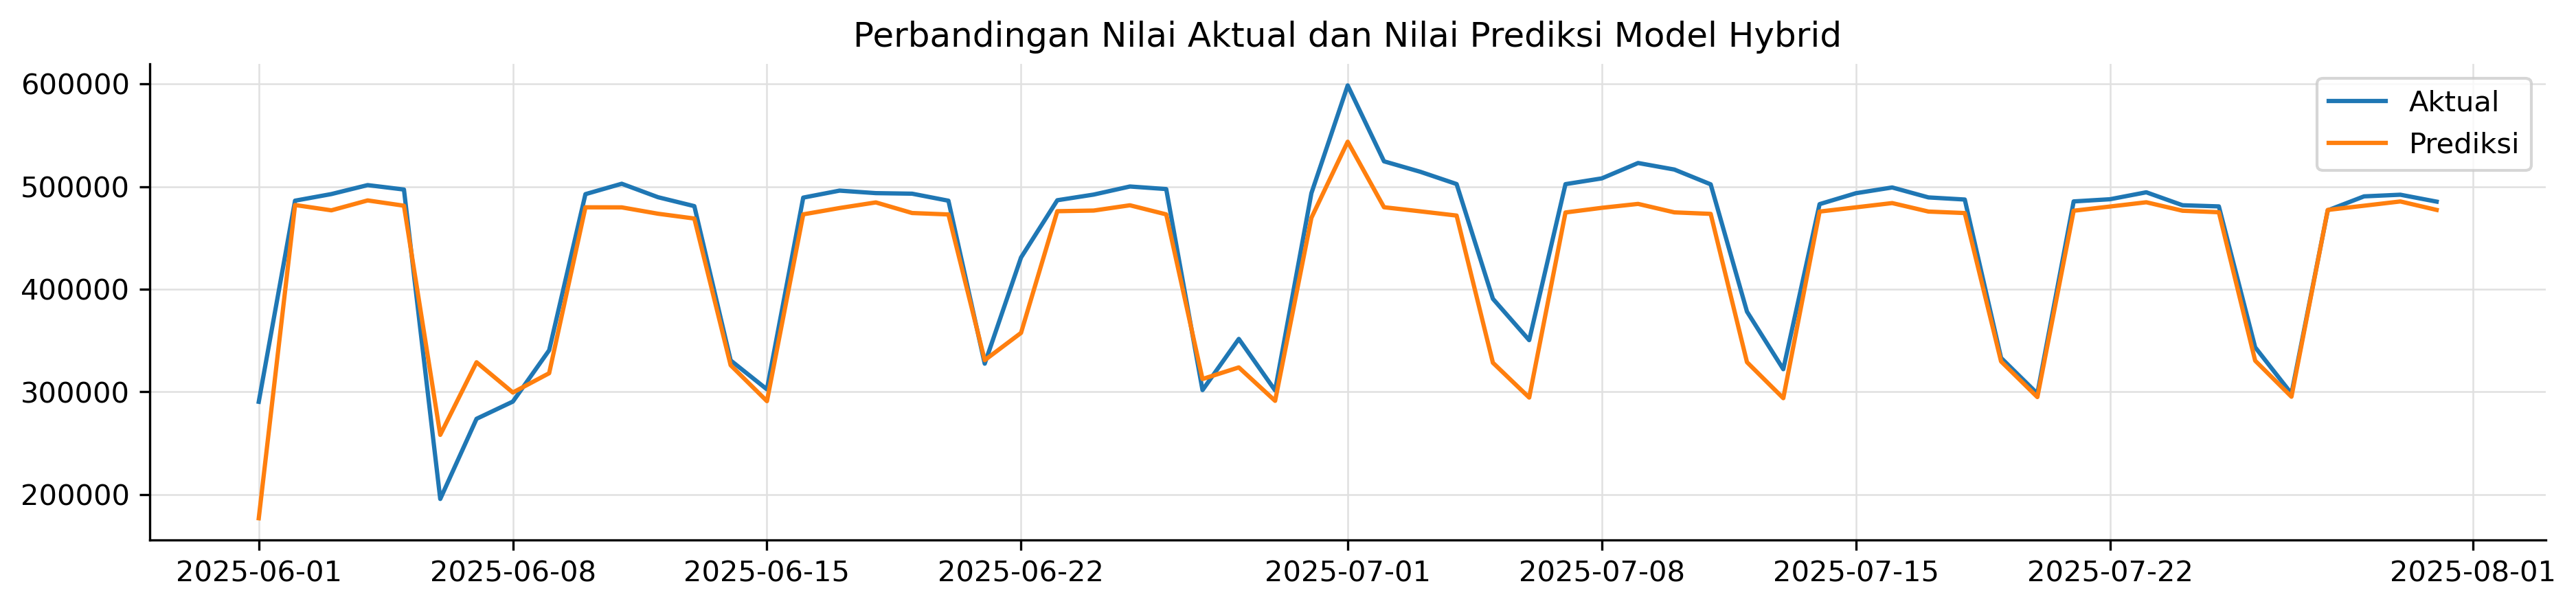

In [367]:
plt.figure(figsize=(15,3))

plt.plot(
    y_true_1.tail(61).index,
    y_true_1.tail(61).values,
    label='Aktual'
)

plt.plot(
    y_true_1.tail(61).index,
    pred_hybrid_asli,
    label='Prediksi'
)

plt.legend()
plt.title('Perbandingan Nilai Aktual dan Nilai Prediksi Model Hybrid')
plt.show()

## SARIMAX

## VISUALISASI

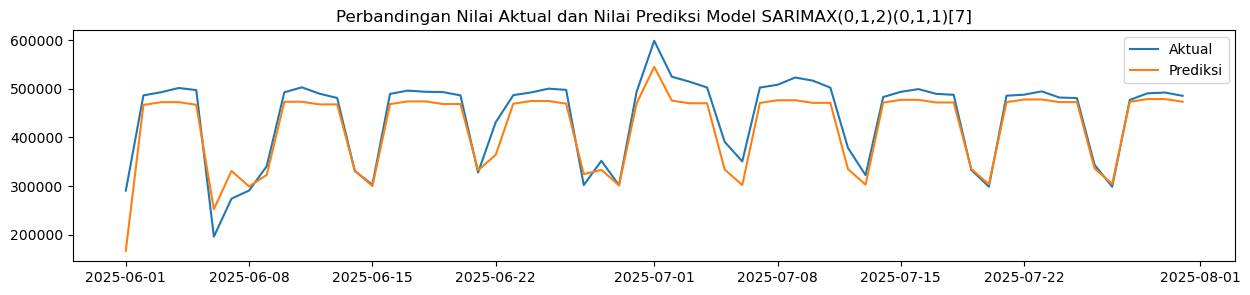

In [106]:
pred_sarimax_asli = inv_boxcox(pred_sarimax_test, lambda_boxcox)
plt.figure(figsize=(15,3))

plt.plot(
    y_true_1.tail(61).index,
    y_true_1.tail(61).values,
    label='Aktual'
)

plt.plot(
    y_true_1.tail(61).index,
    pred_sarimax_asli,
    label='Prediksi'
)

plt.legend()
plt.title('Perbandingan Nilai Aktual dan Nilai Prediksi Model SARIMAX(0,1,2)(0,1,1)[7]')
plt.show()

## EVALUASI SARIMAX

In [108]:
# Hitung MAPE
mape_sarimax = np.mean(np.abs((y_test.values - pred_sarimax_asli) / y_test.values)) * 100
mae_sarimax = np.mean(np.abs(y_test.values - pred_sarimax_asli))
rmse_sarimax = np.sqrt(np.mean((y_test.values - pred_sarimax_asli) ** 2))

print(f"MAPE sarimax: {mape_sarimax:.5f}%")
print(f"MAE sarimax:  {mae_sarimax:.2f}")
print(f"RMSE sarimax: {rmse_sarimax:.2f}")

MAPE sarimax: 6.10530%
MAE sarimax:  24918.89
RMSE sarimax: 32161.33


In [112]:
pred_sarimax_asli.tail(31)

tanggal
2025-07-01    544823.586330
2025-07-02    475498.660185
2025-07-03    470062.014471
2025-07-04    470076.865024
2025-07-05    333788.695701
2025-07-06    301881.870476
2025-07-07    470652.963343
2025-07-08    476232.802732
2025-07-09    476292.439257
2025-07-10    470853.875501
2025-07-11    470868.731317
2025-07-12    334525.533523
2025-07-13    302603.300568
2025-07-14    471445.033704
2025-07-15    477026.839480
2025-07-16    477086.496922
2025-07-17    471646.016984
2025-07-18    471660.878058
2025-07-19    335262.713176
2025-07-20    303325.092926
2025-07-21    472237.384315
2025-07-22    477821.154573
2025-07-23    477880.832914
2025-07-24    472438.438647
2025-07-25    472453.304974
2025-07-26    336000.234224
2025-07-27    304047.247050
2025-07-28    473030.014902
2025-07-29    478615.747745
2025-07-30    478675.446963
2025-07-31    473231.140219
Freq: D, Name: pred_sarimax, dtype: float64

In [97]:
from sklearn.metrics import r2_score

# y_true = nilai aktual
# y_pred = hasil prediksi model

r2 = r2_score(y_test, pred_sarimax_asli)

print("R² =", r2)

R² = 0.8659374478442567


In [99]:
import pandas as pd


# Simpan menjadi Excel
pred_sarimax_asli.to_excel("pred_sarimax_asli_terbaru.xlsx", index=False)

# VISUALISASI PERBANDINGAN

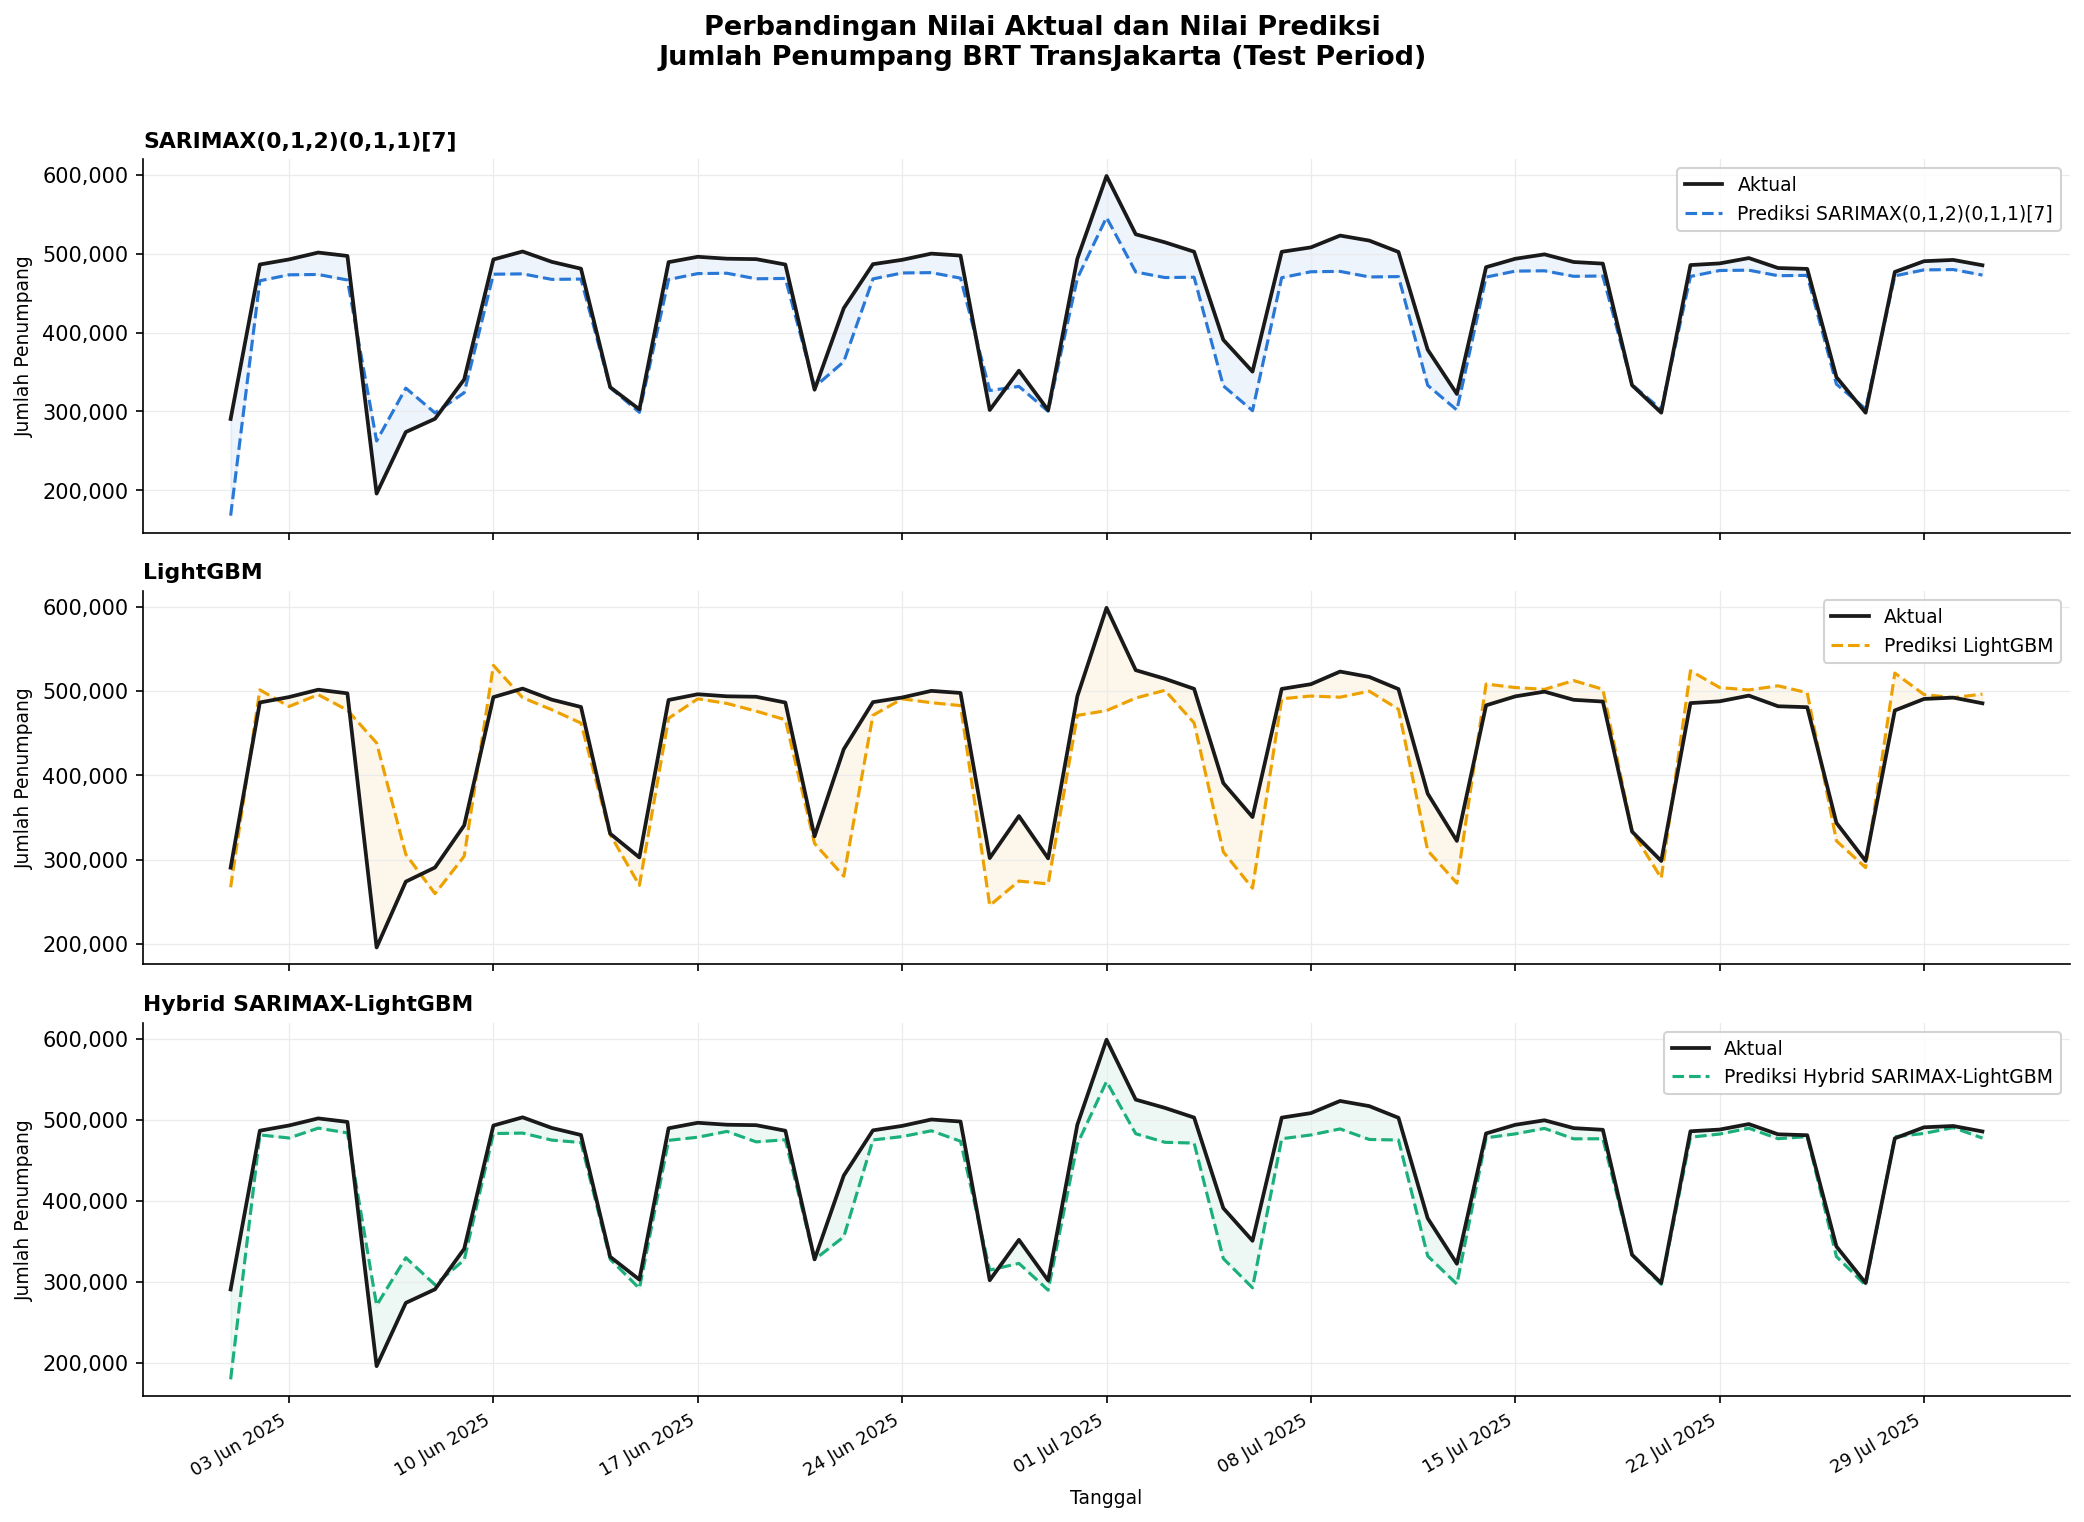

In [207]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ─────────────────────────────────────────────
# GANTI DENGAN DATA ASLIMU
# pred_sarimax, pred_lgbm, pred_hybrid = array/series hasil prediksi
# y_test = series aktual dengan DatetimeIndex
# ─────────────────────────────────────────────

plt.rcParams.update({
    "font.family":       "DejaVu Sans",
    "font.size":         10,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.grid":         True,
    "grid.color":        "#ebebeb",
    "grid.linewidth":    0.6,
    "figure.dpi":        150,
})

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
fig.suptitle(
    "Perbandingan Nilai Aktual dan Nilai Prediksi\nJumlah Penumpang BRT TransJakarta (Test Period)",
    fontsize=13, fontweight="bold", y=1.01
)

configs = [
    ("SARIMAX(0,1,2)(0,1,1)[7]", pred_sarimax_asli, "#2a78d6"),
    ("LightGBM",                  pred_lgbm,    "#eda100"),
    ("Hybrid SARIMAX-LightGBM",   pred_hybrid_asli,  "#1baf7a"),
]

idx = y_test.tail(61).index

for ax, (model_name, pred, color) in zip(axes, configs):
    ax.plot(idx, y_test.tail(61).values,
            color="#1a1a1a", lw=1.8, label="Aktual", zorder=3)
    ax.plot(idx, pred,
            color=color, lw=1.5, ls="--", label=f"Prediksi {model_name}", zorder=2)

    ax.fill_between(idx, y_test.tail(61).values, pred,
                    alpha=0.08, color=color)

    ax.set_title(model_name, fontsize=10.5, fontweight="bold", loc="left", pad=6)
    ax.set_ylabel("Jumlah Penumpang", fontsize=9)
    ax.legend(loc="upper right", fontsize=9, framealpha=0.85)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))

axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
axes[-1].xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
plt.setp(axes[-1].get_xticklabels(), rotation=30, ha="right", fontsize=8.5)
axes[-1].set_xlabel("Tanggal", fontsize=9)

plt.tight_layout()
plt.savefig("visualisasi_prediksi.png", bbox_inches="tight", dpi=150)
plt.show()

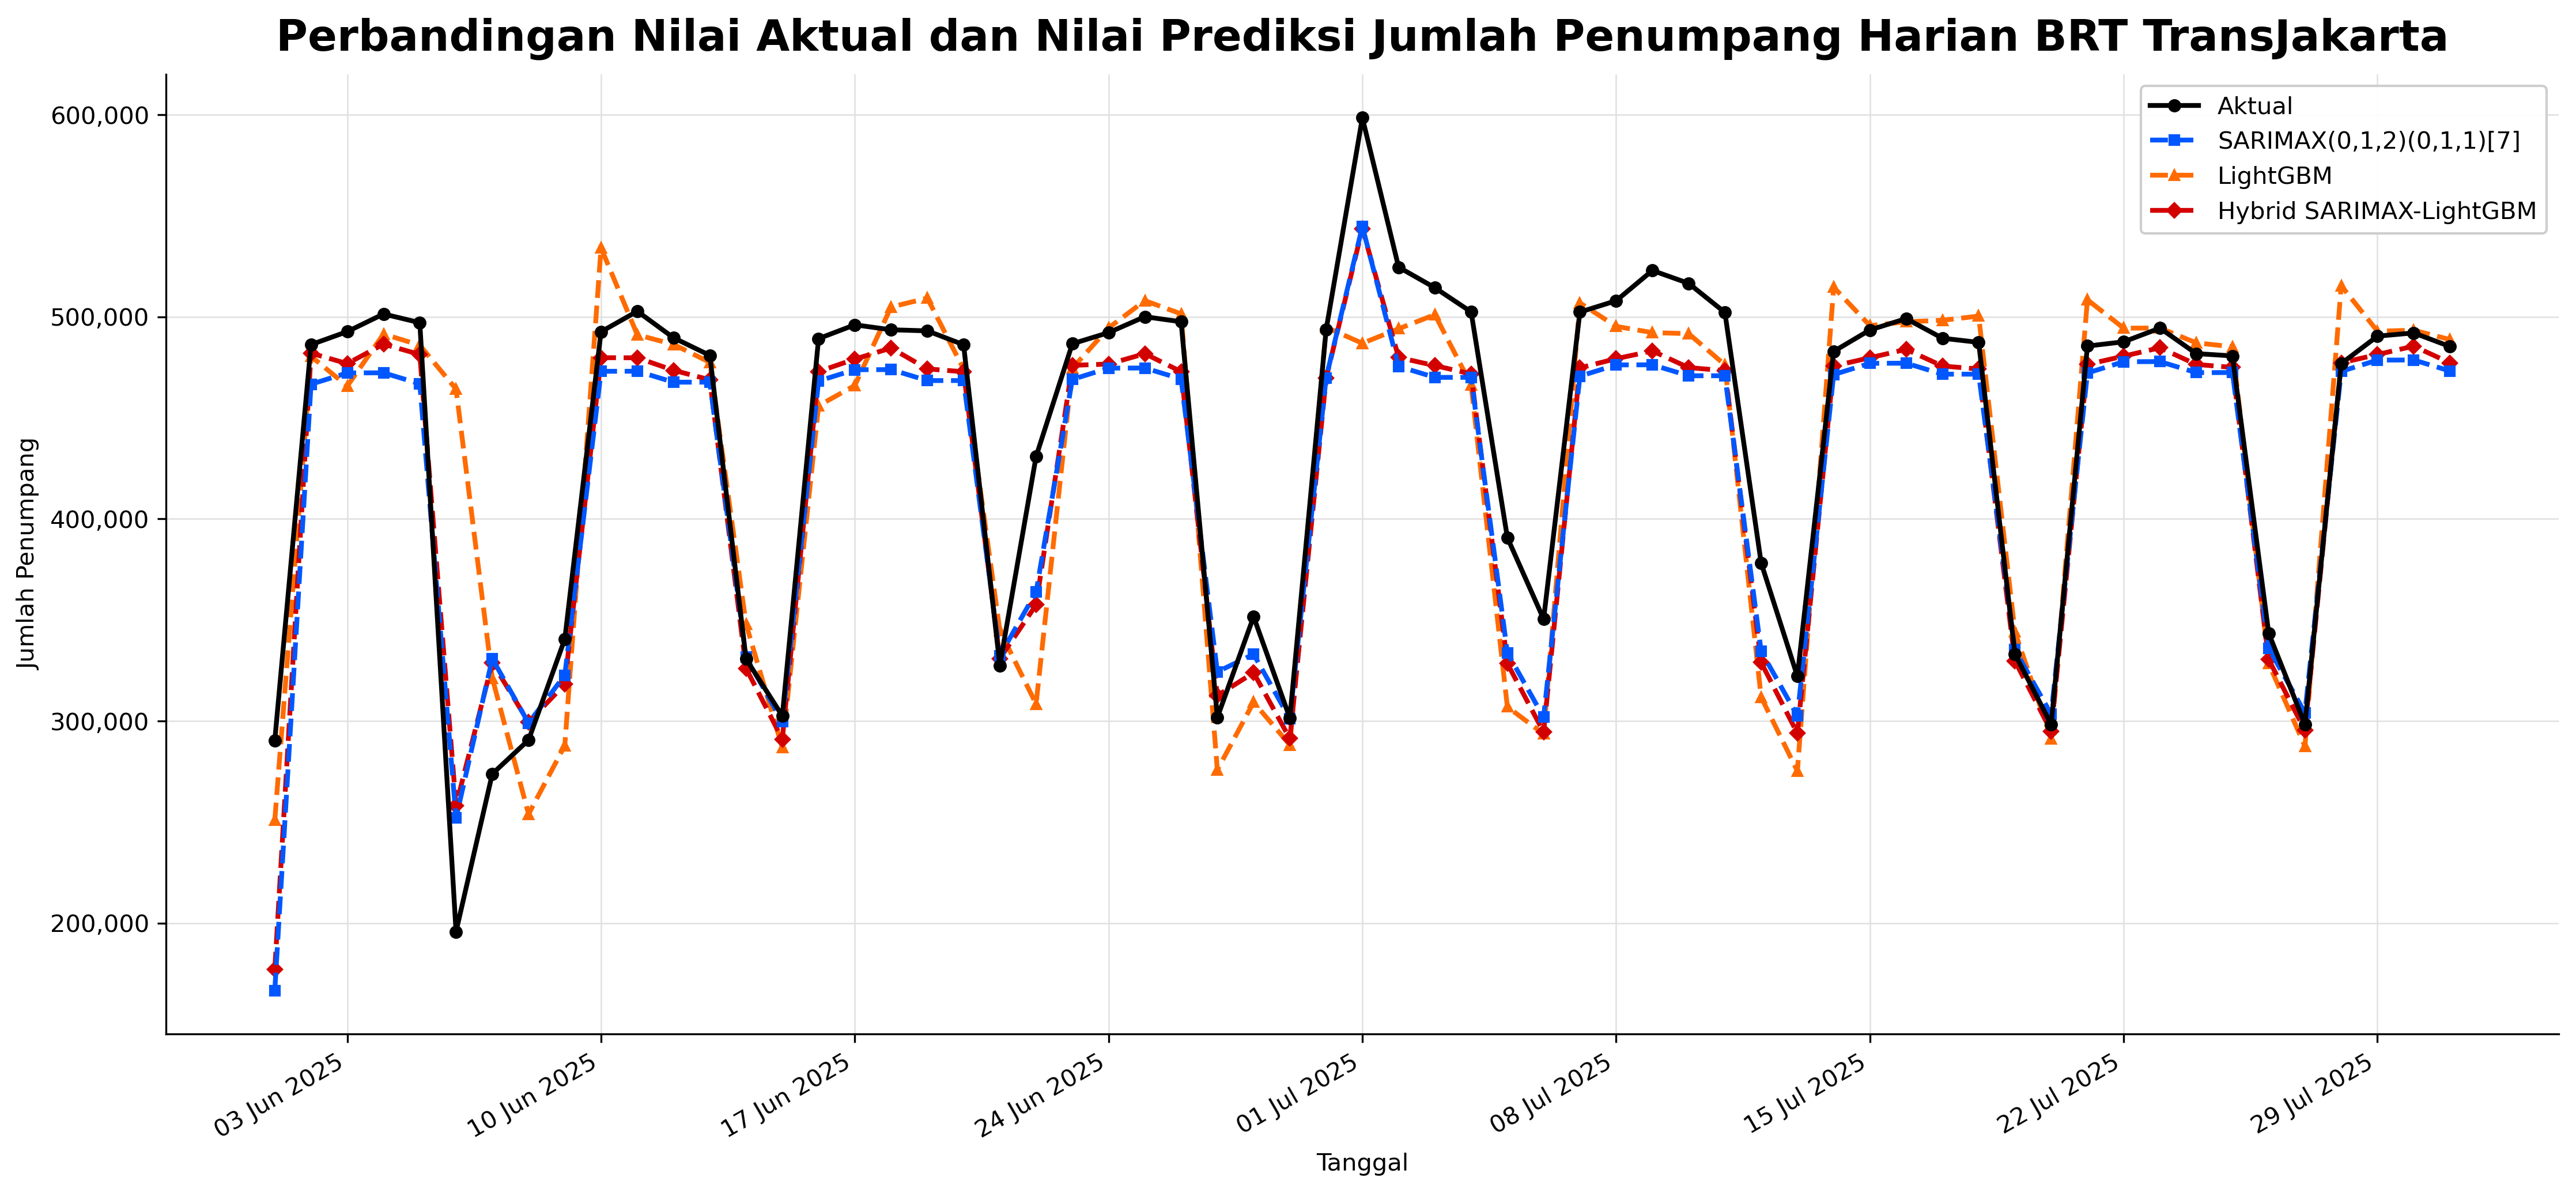

In [373]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# ─────────────────────────────────────────────
# GANTI DENGAN DATA ASLIMU
# pred_sarimax, pred_lgbm, pred_hybrid = array/series hasil prediksi
# y_test = series aktual dengan DatetimeIndex
# ─────────────────────────────────────────────

plt.rcParams.update({
    "font.family":       "DejaVu Sans",
    "font.size":         10,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.grid":         True,
    "grid.color":        "#e0e0e0",
    "grid.linewidth":    0.6,
    "figure.dpi":        300,
})

idx    = y_test.tail(61).index
aktual = y_test.tail(61).values

fig, ax = plt.subplots(figsize=(15, 7))

ax.plot(idx, aktual,
        color="#000000", lw=2.0, marker="o", markersize=4.5,
        label="Aktual", zorder=5)

ax.plot(idx, pred_sarimax_asli,
        color="#0057FF", lw=2.0, ls="--", marker="s", markersize=4,
        label="SARIMAX(0,1,2)(0,1,1)[7]", zorder=4)

ax.plot(idx, pred_lgbm,
        color="#FF6B00", lw=2.0, ls="--", marker="^", markersize=4,
        label="LightGBM", zorder=3)

ax.plot(idx, pred_hybrid_asli,
        color="#D30000", lw=2.0, ls="--", marker="D", markersize=4,
        label="Hybrid SARIMAX-LightGBM", zorder=3)

ax.set_title(
    "Perbandingan Nilai Aktual dan Nilai Prediksi Jumlah Penumpang Harian BRT TransJakarta",
    fontsize=18, fontweight="bold", pad=10
)
ax.set_ylabel("Jumlah Penumpang")
ax.set_xlabel("Tanggal")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b %Y"))
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
plt.setp(ax.get_xticklabels(), rotation=30, ha="right", fontsize=10)
ax.legend(loc="upper right", fontsize=10, framealpha=0.95)

plt.tight_layout()
plt.savefig("visualisasi_prediksi.png", bbox_inches="tight", dpi=150)
plt.show()

In [763]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [469]:
from scipy.stats import boxcox

# Transformasi data train
y_train_bc, lambda_bc = boxcox(y_train3)

print(lambda_bc)

NameError: name 'y_train3' is not defined

In [955]:
from scipy.stats import boxcox

y_train_bc = boxcox(y_train3, lmbda=0.7894795)

In [957]:
# Split train-validation-test
# ==============================================================================
end_train1 = '2025-05-31 23:59:00'
data_train3 = df2.loc[: end_train1, :]
data_test3  = df2.loc[end_train1:, :]

print(f"Dates train      : {data_train3.index.min()} --- {data_train3.index.max()}  (n={len(data_train3)})")
print(f"Dates test       : {data_test3.index.min()} --- {data_test3.index.max()}  (n={len(data_test3)})")


Dates train      : 2023-01-01 00:00:00 --- 2025-05-31 00:00:00  (n=882)
Dates test       : 2025-06-01 00:00:00 --- 2025-07-31 00:00:00  (n=61)


In [959]:
y_train3 = data_train3['pengguna']
y_test3  = data_test3['pengguna']
X_train3 =data_train3.drop(columns=['tahun','index', 'bulan','hari','pengguna','akhir_pekan','dow','doy','sin_dow','cos_dow'])
X_test3  = data_test3.drop(columns=[ 'tahun','index', 'bulan','hari','pengguna','akhir_pekan','dow','doy','sin_dow','cos_dow'])

In [960]:
X_train3

,libur_nasional,lebaran,promo_tarif
tanggal,,,
2023-01-01,1,0,0
2023-01-02,0,0,0
2023-01-03,0,0,0
2023-01-04,0,0,0
2023-01-05,0,0,0
...,...,...,...
2025-05-27,0,0,0
2025-05-28,0,0,0
2025-05-29,1,0,0


In [961]:
20536.263

20536.263

In [969]:
model = SARIMAX(
    y_train_bc,
    exog=X_train3,
    order=(0,1,2),
    seasonal_order=(0,1,1,7)
)

results = model.fit()

In [970]:
results.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                      
===========================================================================================
Dep. Variable:                                   y   No. Observations:                  882
Model:             SARIMAX(0, 1, 2)x(0, 1, [1], 7)   Log Likelihood               -7873.349
Date:                             Sat, 25 Jul 2026   AIC                          15760.697
Time:                                     10:45:45   BIC                          15794.109
Sample:                                 01-01-2023   HQIC                         15773.478
                                      - 05-31-2025                                         
Covariance Type:                               opg                                         
==================================================================================
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
libur_nasional -8939.3819    105.355    -84.850      0.000   -9145.874   -8732.890
lebaran         -1.33e+04    296.806    -44.796      0.000   -1.39e+04   -1.27e+04
promo_tarif     5221.9459    395.320     13.209      0.000    4447.134    5996.758
ma.L1             -0.6959      0.021    -32.839      0.000      -0.737      -0.654
ma.L2             -0.1048      0.028     -3.715      0.000      -0.160      -0.050
ma.S.L7           -0.9995      0.023    -43.103      0.000      -1.045      -0.954
sigma2          3.446e+06      0.031    1.1e+08      0.000    3.45e+06    3.45e+06
===================================================================================
Ljung-Box (L1) (Q):                   0.88   Jarque-Bera (JB):              1194.89
Prob(Q):                              0.35   Prob(JB):                         0.00
Heteroskedasticity (H):               1.14   Skew:                            -0.50
Prob(H) (two-sided):                  0.25   Kurtosis:                         8.64
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
[2] Covariance matrix is singular or near-singular, with condition number 4.76e+23. Standard errors may be unstable.
"""

In [492]:
from statsmodels.stats.diagnostic import het_arch

arch_test = het_arch(results.resid)

print("LM Statistic :", arch_test[0])
print("p-value      :", arch_test[1])

LM Statistic : 147.50292843834833
p-value      : 1.2158728145700374e-26


In [493]:
print(X_train3.corr())

                libur_nasional   lebaran  promo_tarif
libur_nasional        1.000000 -0.025848    -0.020400
lebaran              -0.025848  1.000000    -0.007224
promo_tarif          -0.020400 -0.007224     1.000000


In [494]:
X_train3.sum()

libur_nasional    60
lebaran            8
promo_tarif        5
dtype: int64

In [973]:
fore = results.forecast(
    steps=len(y_test3),
    exog=X_test3
)
lmbda=0.7894795
fore = inv_boxcox(fore, lmbda)

In [975]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mape = mean_absolute_percentage_error(y_test3, fore)
mae = mean_absolute_error(y_test3, fore)
rmse = np.sqrt(mean_squared_error(y_test3, fore))
r2 = r2_score(y_test3, fore)

print("MAPE:", mape)
print("MAPE (%):", mape * 100)
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAPE: 0.06277421470696803
MAPE (%): 6.277421470696804
MAE : 25546.62911320381
RMSE: 31877.88896877751
R²  : 0.8682900300845566


In [359]:
df

,tanggal,tahun,bulan,hari,doy,pengguna,akhir_pekan,libur_nasional,lebaran,promo_tarif,dow
0,2023-01-01,2023,1,1,1,184616,1,1,0,0,7
1,2023-01-02,2023,1,2,2,314296,0,0,0,0,1
2,2023-01-03,2023,1,3,3,339823,0,0,0,0,2
3,2023-01-04,2023,1,4,4,348919,0,0,0,0,3
4,2023-01-05,2023,1,5,5,348914,0,0,0,0,4
...,...,...,...,...,...,...,...,...,...,...,...
938,2025-07-27,2025,7,27,208,298335,1,0,0,0,7
939,2025-07-28,2025,7,28,209,476862,0,0,0,0,1
940,2025-07-29,2025,7,29,210,490471,0,0,0,0,2
941,2025-07-30,2025,7,30,211,492080,0,0,0,0,3


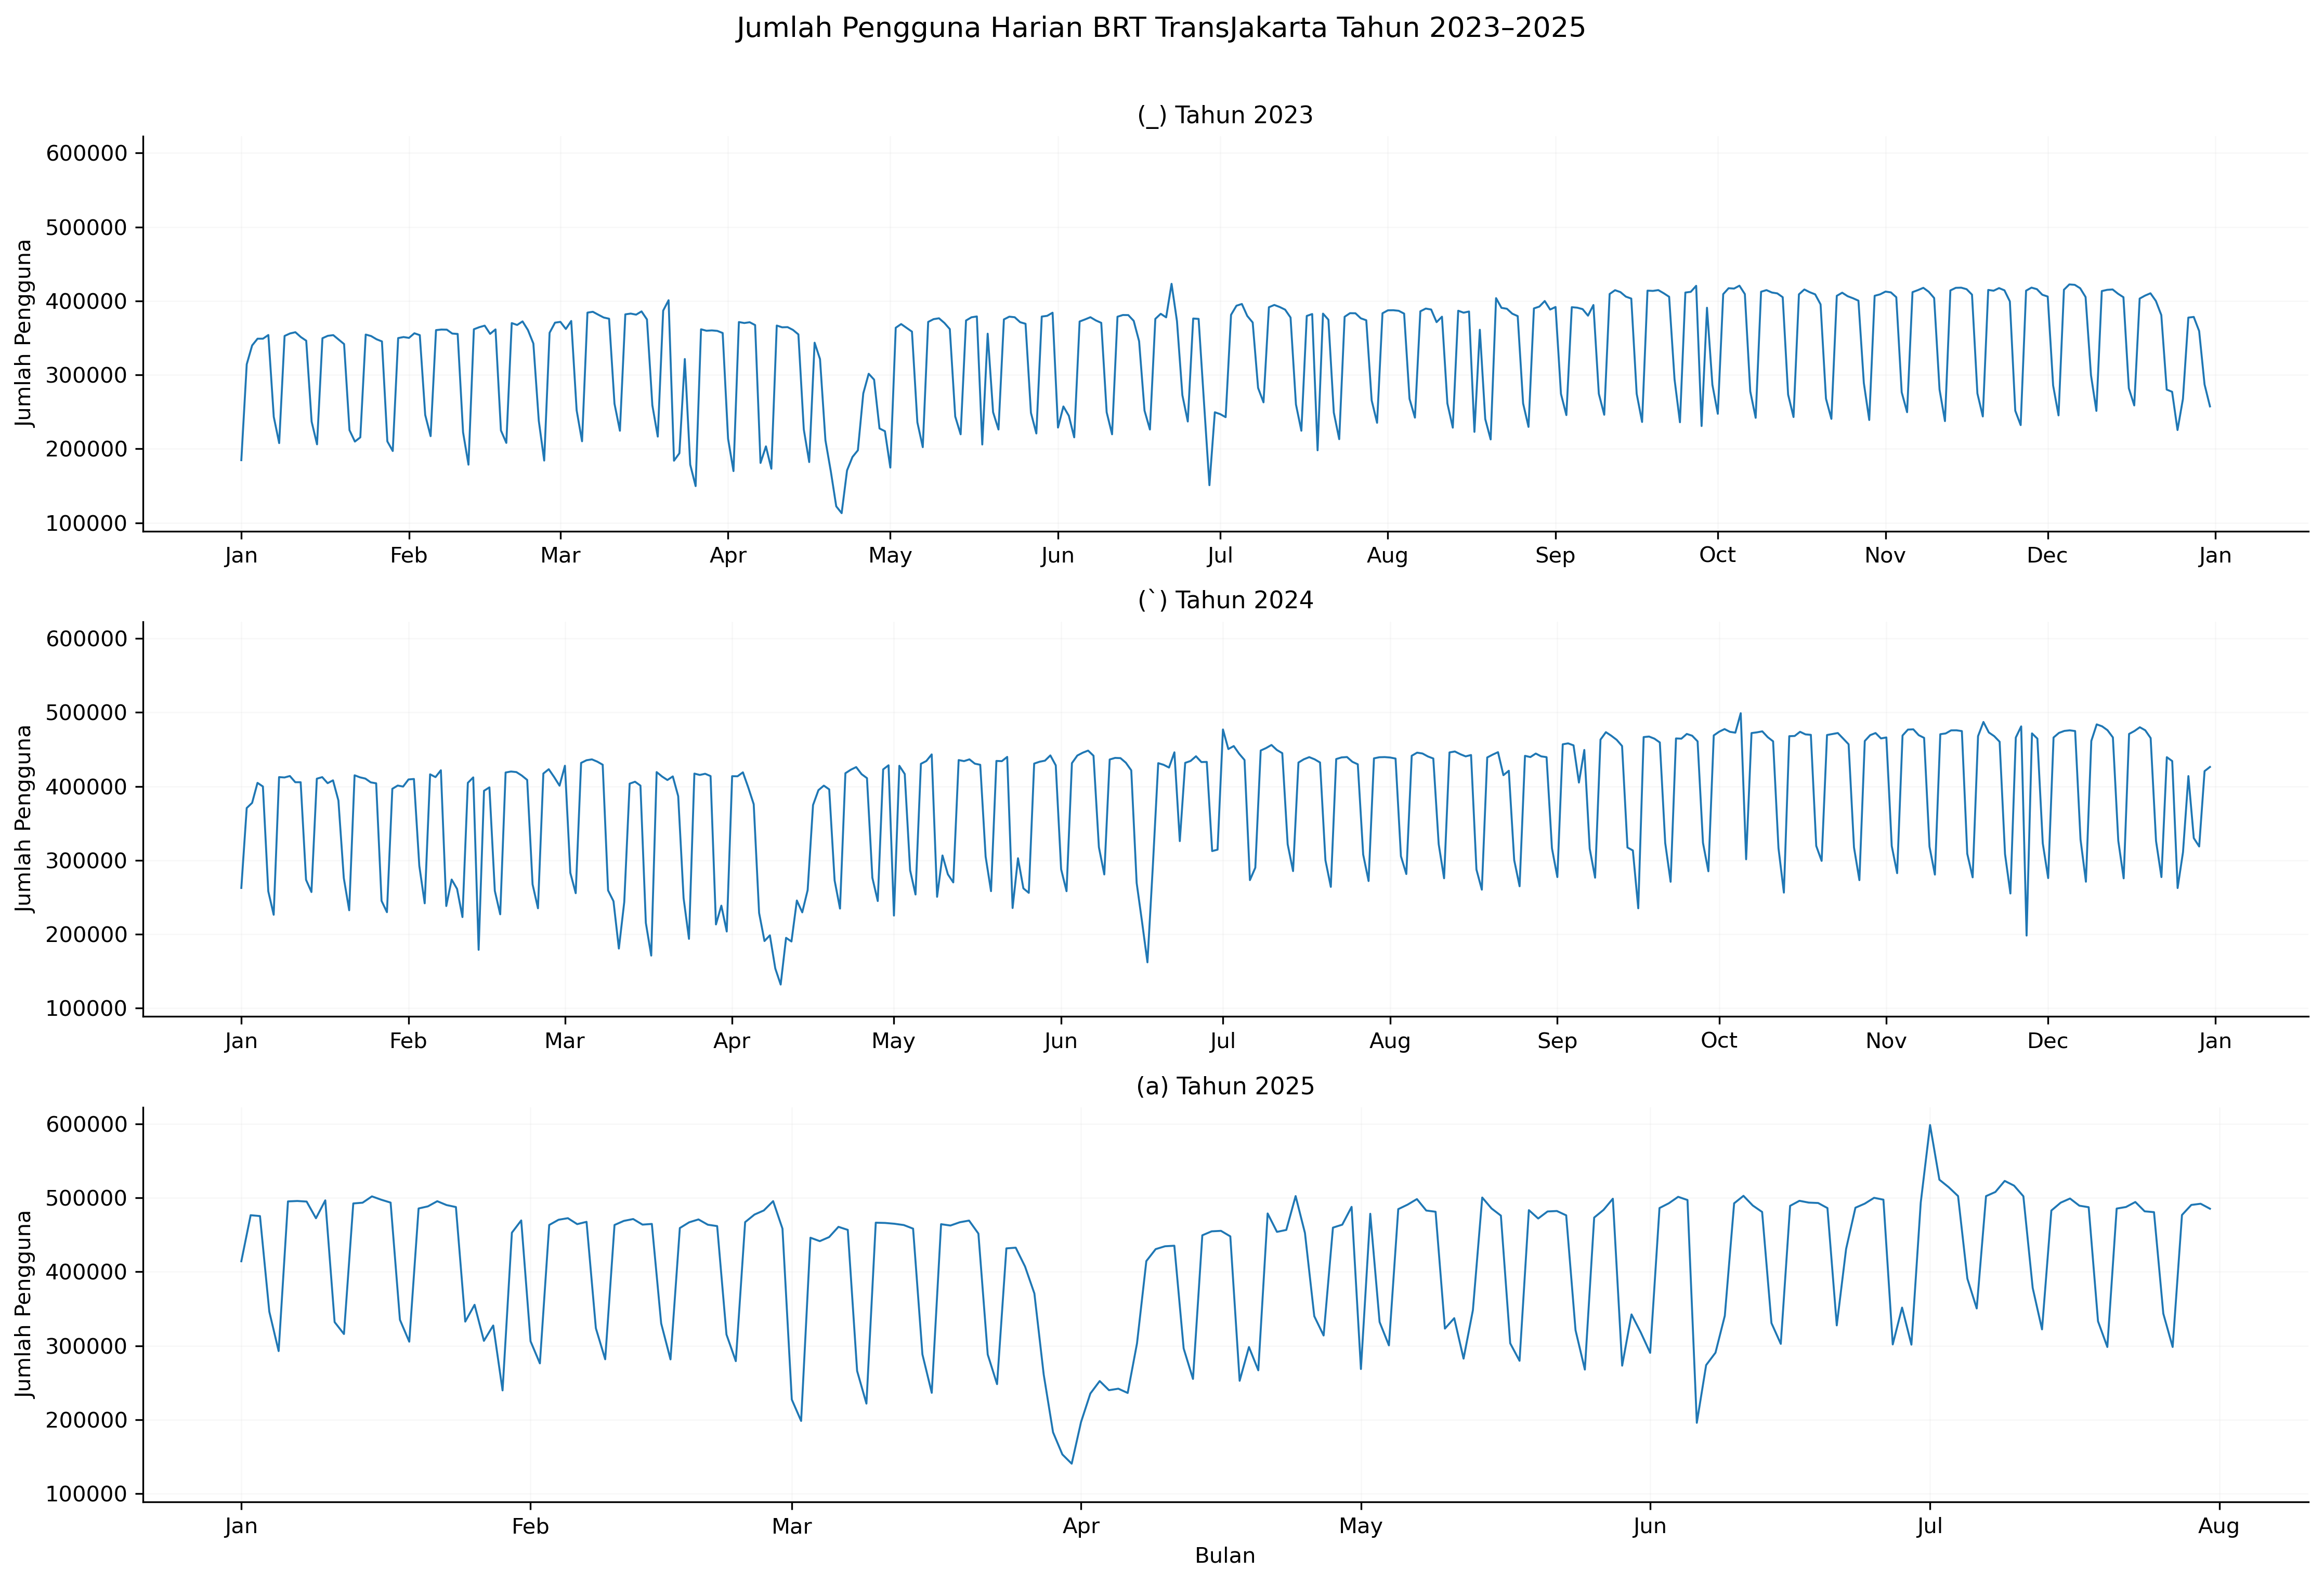

In [361]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_plot = df.copy()

date_col = "tanggal"             # sesuaikan
target_col = "pengguna"   # sesuaikan

df_plot[date_col] = pd.to_datetime(df_plot[date_col], dayfirst=True)
df_plot = df_plot.sort_values(date_col)
df_plot["Tahun"] = df_plot[date_col].dt.year

tahun_list = [2023, 2024, 2025]

fig, axes = plt.subplots(
    3, 1,
    figsize=(15, 10),
    sharey=True
)

for ax, tahun in zip(axes, tahun_list):
    data_tahun = df_plot[df_plot["Tahun"] == tahun]

    ax.plot(
        data_tahun[date_col],
        data_tahun[target_col],
        color="#1f77b4",
        linewidth=0.9
    )

    ax.set_title(f"({chr(94 + tahun - 2022)}) Tahun {tahun}", fontsize=11)
    ax.set_ylabel("Jumlah Pengguna")
    ax.grid(alpha=0.25)

    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

axes[-1].set_xlabel("Bulan")

fig.suptitle(
    "Jumlah Pengguna Harian BRT TransJakarta Tahun 2023–2025",
    fontsize=13,
    y=1.01
)

plt.tight_layout()

plt.savefig(
    "jumlah_pengguna_per_tahun.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

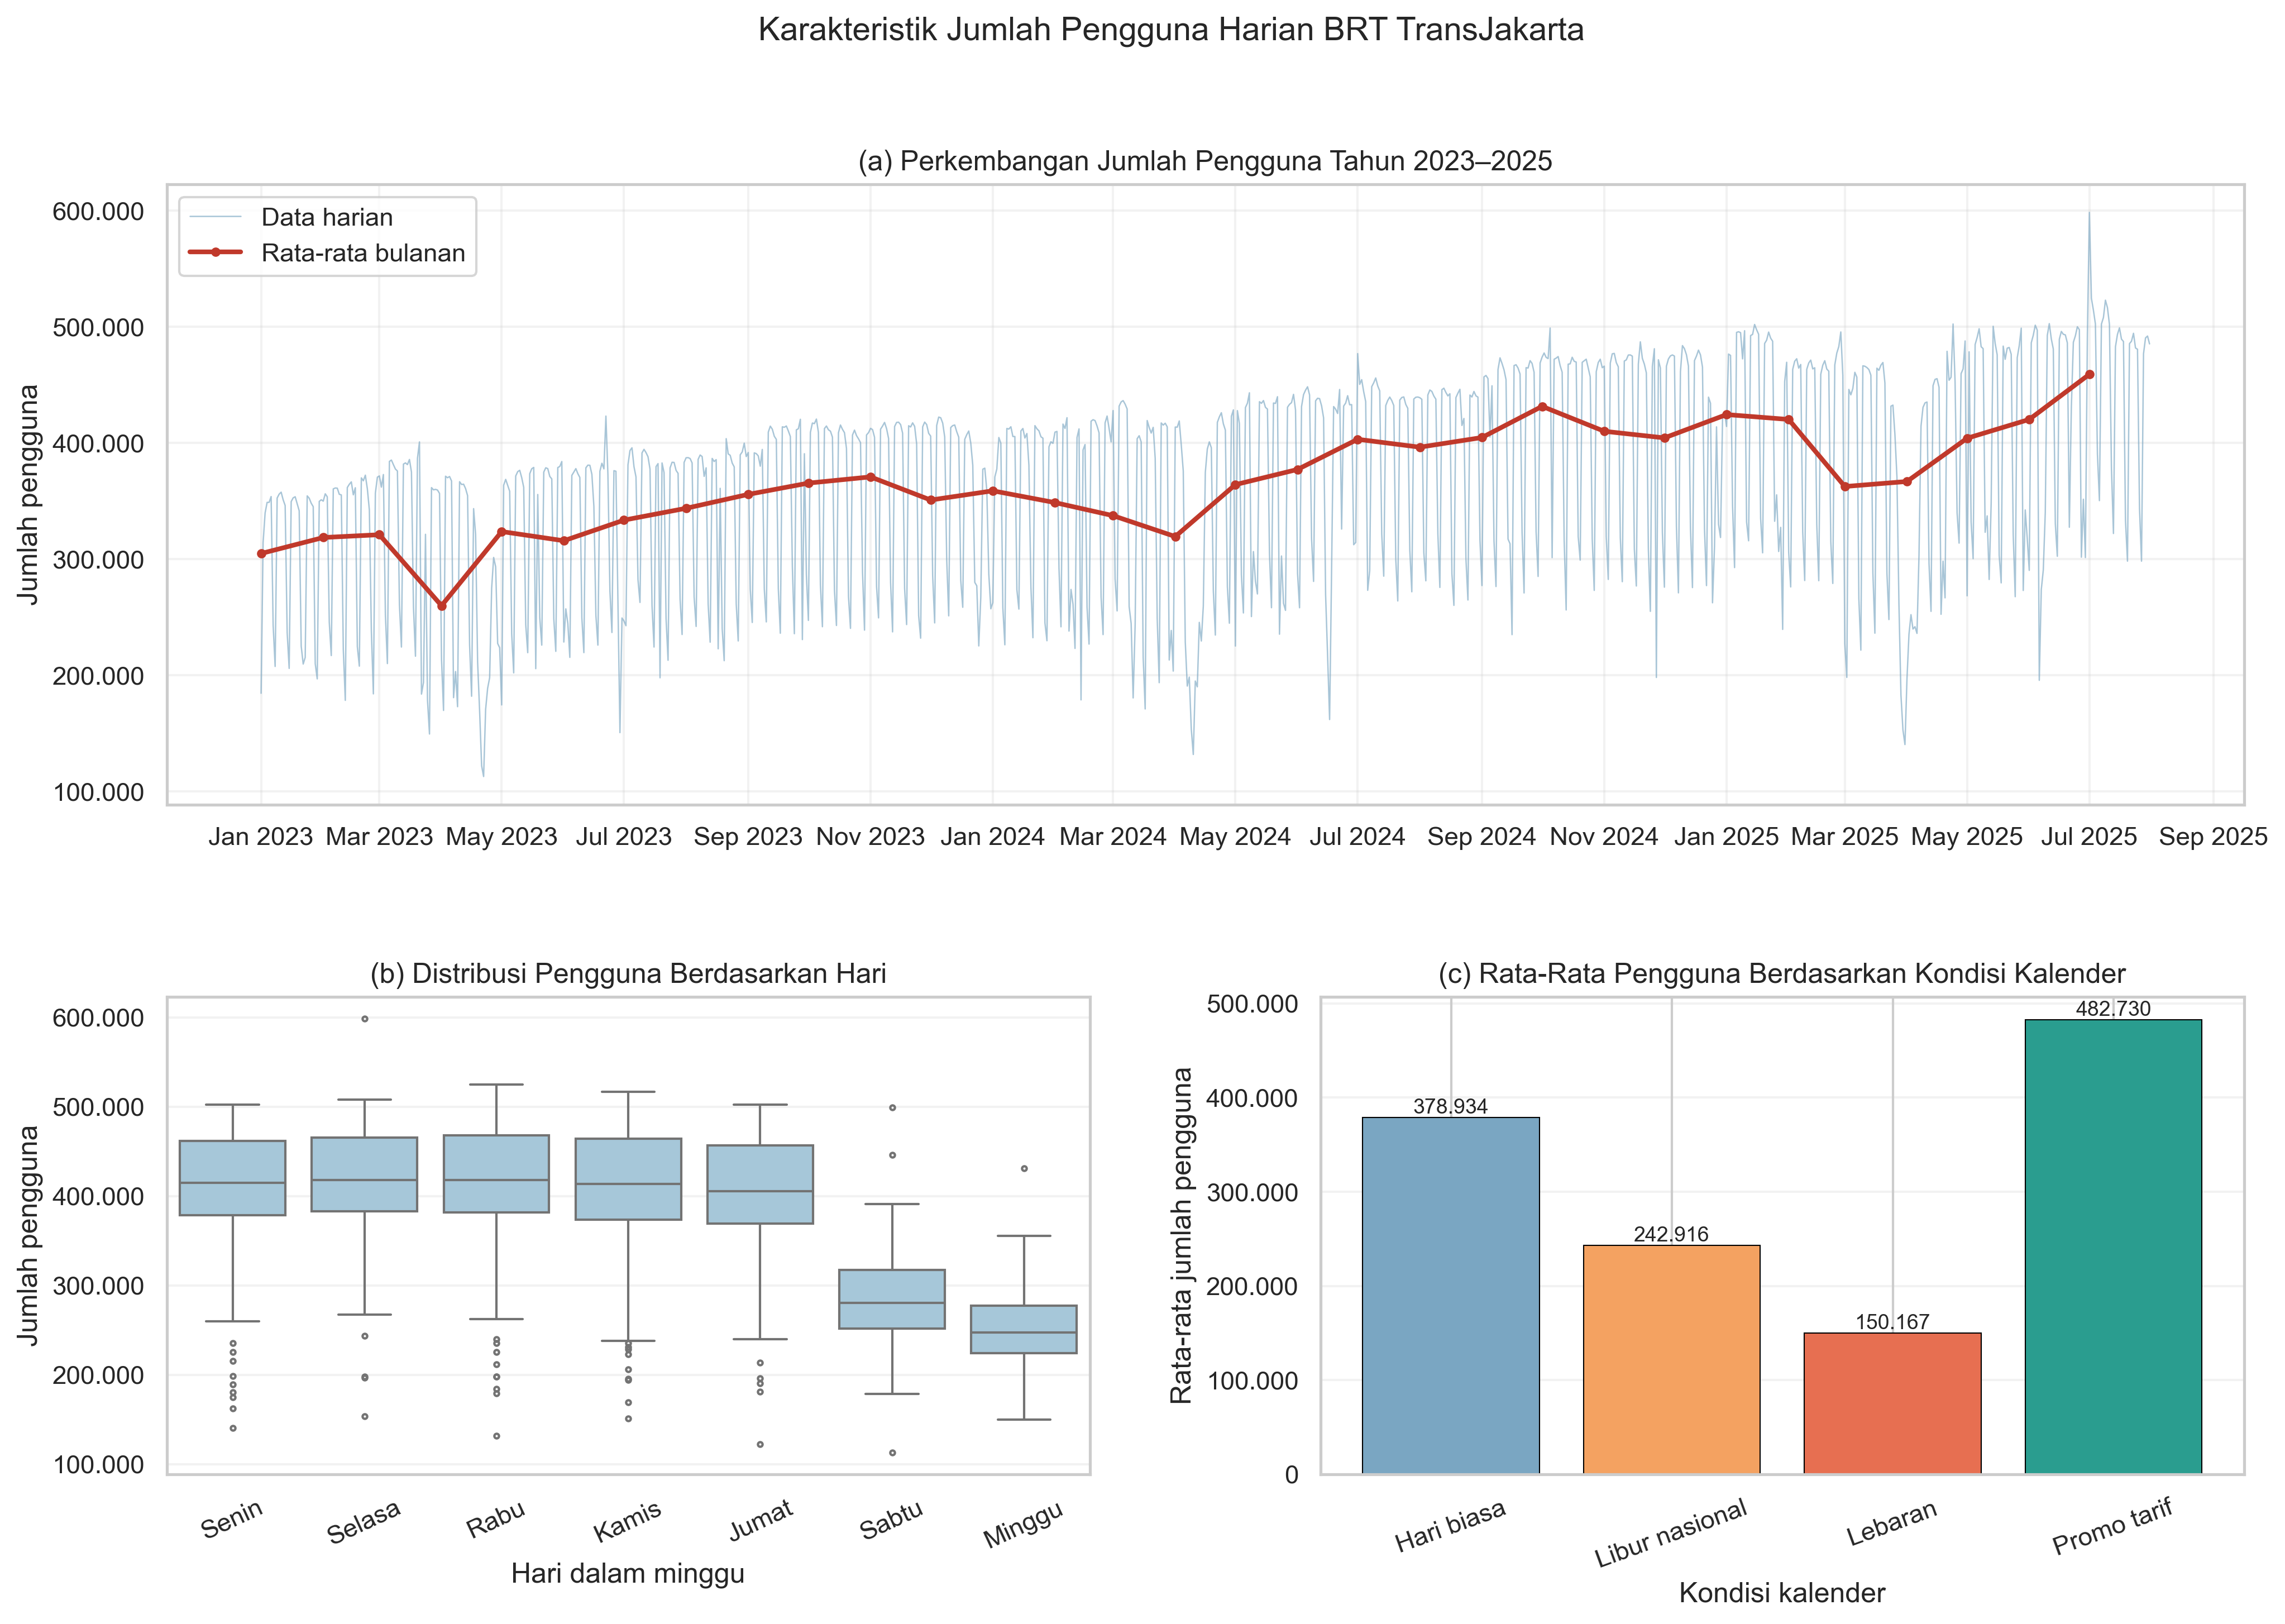

In [363]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# =========================
# SESUAIKAN NAMA KOLOM
# =========================
date_col = "tanggal"
target_col = "pengguna"

df_plot = df.copy()

df_plot[date_col] = pd.to_datetime(
    df_plot[date_col],
    dayfirst=True
)

df_plot = df_plot.sort_values(date_col)

# Format angka ribuan pada sumbu
format_ribuan = FuncFormatter(
    lambda x, pos: f"{x:,.0f}".replace(",", ".")
)

# =========================
# FITUR UNTUK VISUALISASI
# =========================

# Hari dalam minggu
nama_hari = {
    0: "Senin",
    1: "Selasa",
    2: "Rabu",
    3: "Kamis",
    4: "Jumat",
    5: "Sabtu",
    6: "Minggu"
}

urutan_hari = [
    "Senin", "Selasa", "Rabu",
    "Kamis", "Jumat", "Sabtu", "Minggu"
]

df_plot["Hari"] = (
    df_plot[date_col]
    .dt.dayofweek
    .map(nama_hari)
)

# Kategori kalender
# Urutan prioritas: Lebaran, promo tarif, libur nasional, hari biasa
df_plot["Kategori_Kalender"] = np.select(
    [
        df_plot["lebaran"] == 1,
        df_plot["promo_tarif"] == 1,
        df_plot["libur_nasional"] == 1
    ],
    [
        "Lebaran",
        "Promo tarif",
        "Libur nasional"
    ],
    default="Hari biasa"
)

urutan_kategori = [
    "Hari biasa",
    "Libur nasional",
    "Lebaran",
    "Promo tarif"
]

# Rata-rata bulanan untuk memperjelas tren
rata_bulanan = (
    df_plot
    .set_index(date_col)[target_col]
    .resample("MS")
    .mean()
)

# Rata-rata berdasarkan kategori kalender
rata_kalender = (
    df_plot
    .groupby("Kategori_Kalender")[target_col]
    .mean()
    .reindex(urutan_kategori)
)

# =========================
# MEMBUAT SATU GAMBAR
# =========================
sns.set_theme(style="whitegrid")

fig = plt.figure(figsize=(16, 10))

gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    height_ratios=[1.3, 1],
    hspace=0.35,
    wspace=0.25
)

# Panel (a): seluruh periode
ax1 = fig.add_subplot(gs[0, :])

ax1.plot(
    df_plot[date_col],
    df_plot[target_col],
    color="#7aa6c2",
    linewidth=0.6,
    alpha=0.65,
    label="Data harian"
)

ax1.plot(
    rata_bulanan.index,
    rata_bulanan.values,
    color="#c0392b",
    linewidth=2,
    marker="o",
    markersize=3,
    label="Rata-rata bulanan"
)

ax1.set_title(
    "(a) Perkembangan Jumlah Pengguna Tahun 2023–2025"
)
ax1.set_xlabel("")
ax1.set_ylabel("Jumlah pengguna")
ax1.yaxis.set_major_formatter(format_ribuan)
ax1.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax1.legend()
ax1.grid(alpha=0.25)

# Panel (b): pola mingguan
ax2 = fig.add_subplot(gs[1, 0])

sns.boxplot(
    data=df_plot,
    x="Hari",
    y=target_col,
    order=urutan_hari,
    color="#9ecae1",
    fliersize=2,
    ax=ax2
)

ax2.set_title(
    "(b) Distribusi Pengguna Berdasarkan Hari"
)
ax2.set_xlabel("Hari dalam minggu")
ax2.set_ylabel("Jumlah pengguna")
ax2.yaxis.set_major_formatter(format_ribuan)
ax2.tick_params(axis="x", rotation=25)
ax2.grid(axis="y", alpha=0.25)

# Panel (c): kondisi kalender
ax3 = fig.add_subplot(gs[1, 1])

warna = [
    "#7aa6c2",
    "#f4a261",
    "#e76f51",
    "#2a9d8f"
]

bars = ax3.bar(
    rata_kalender.index,
    rata_kalender.values,
    color=warna,
    edgecolor="black",
    linewidth=0.5
)

ax3.set_title(
    "(c) Rata-Rata Pengguna Berdasarkan Kondisi Kalender"
)
ax3.set_xlabel("Kondisi kalender")
ax3.set_ylabel("Rata-rata jumlah pengguna")
ax3.yaxis.set_major_formatter(format_ribuan)
ax3.tick_params(axis="x", rotation=20)
ax3.grid(axis="y", alpha=0.25)

# Label nilai pada diagram batang
for bar in bars:
    nilai = bar.get_height()

    ax3.text(
        bar.get_x() + bar.get_width() / 2,
        nilai,
        f"{nilai:,.0f}".replace(",", "."),
        ha="center",
        va="bottom",
        fontsize=9
    )

fig.suptitle(
    "Karakteristik Jumlah Pengguna Harian BRT TransJakarta",
    fontsize=14,
    y=0.98
)

plt.savefig(
    "karakteristik_pengguna_transjakarta.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

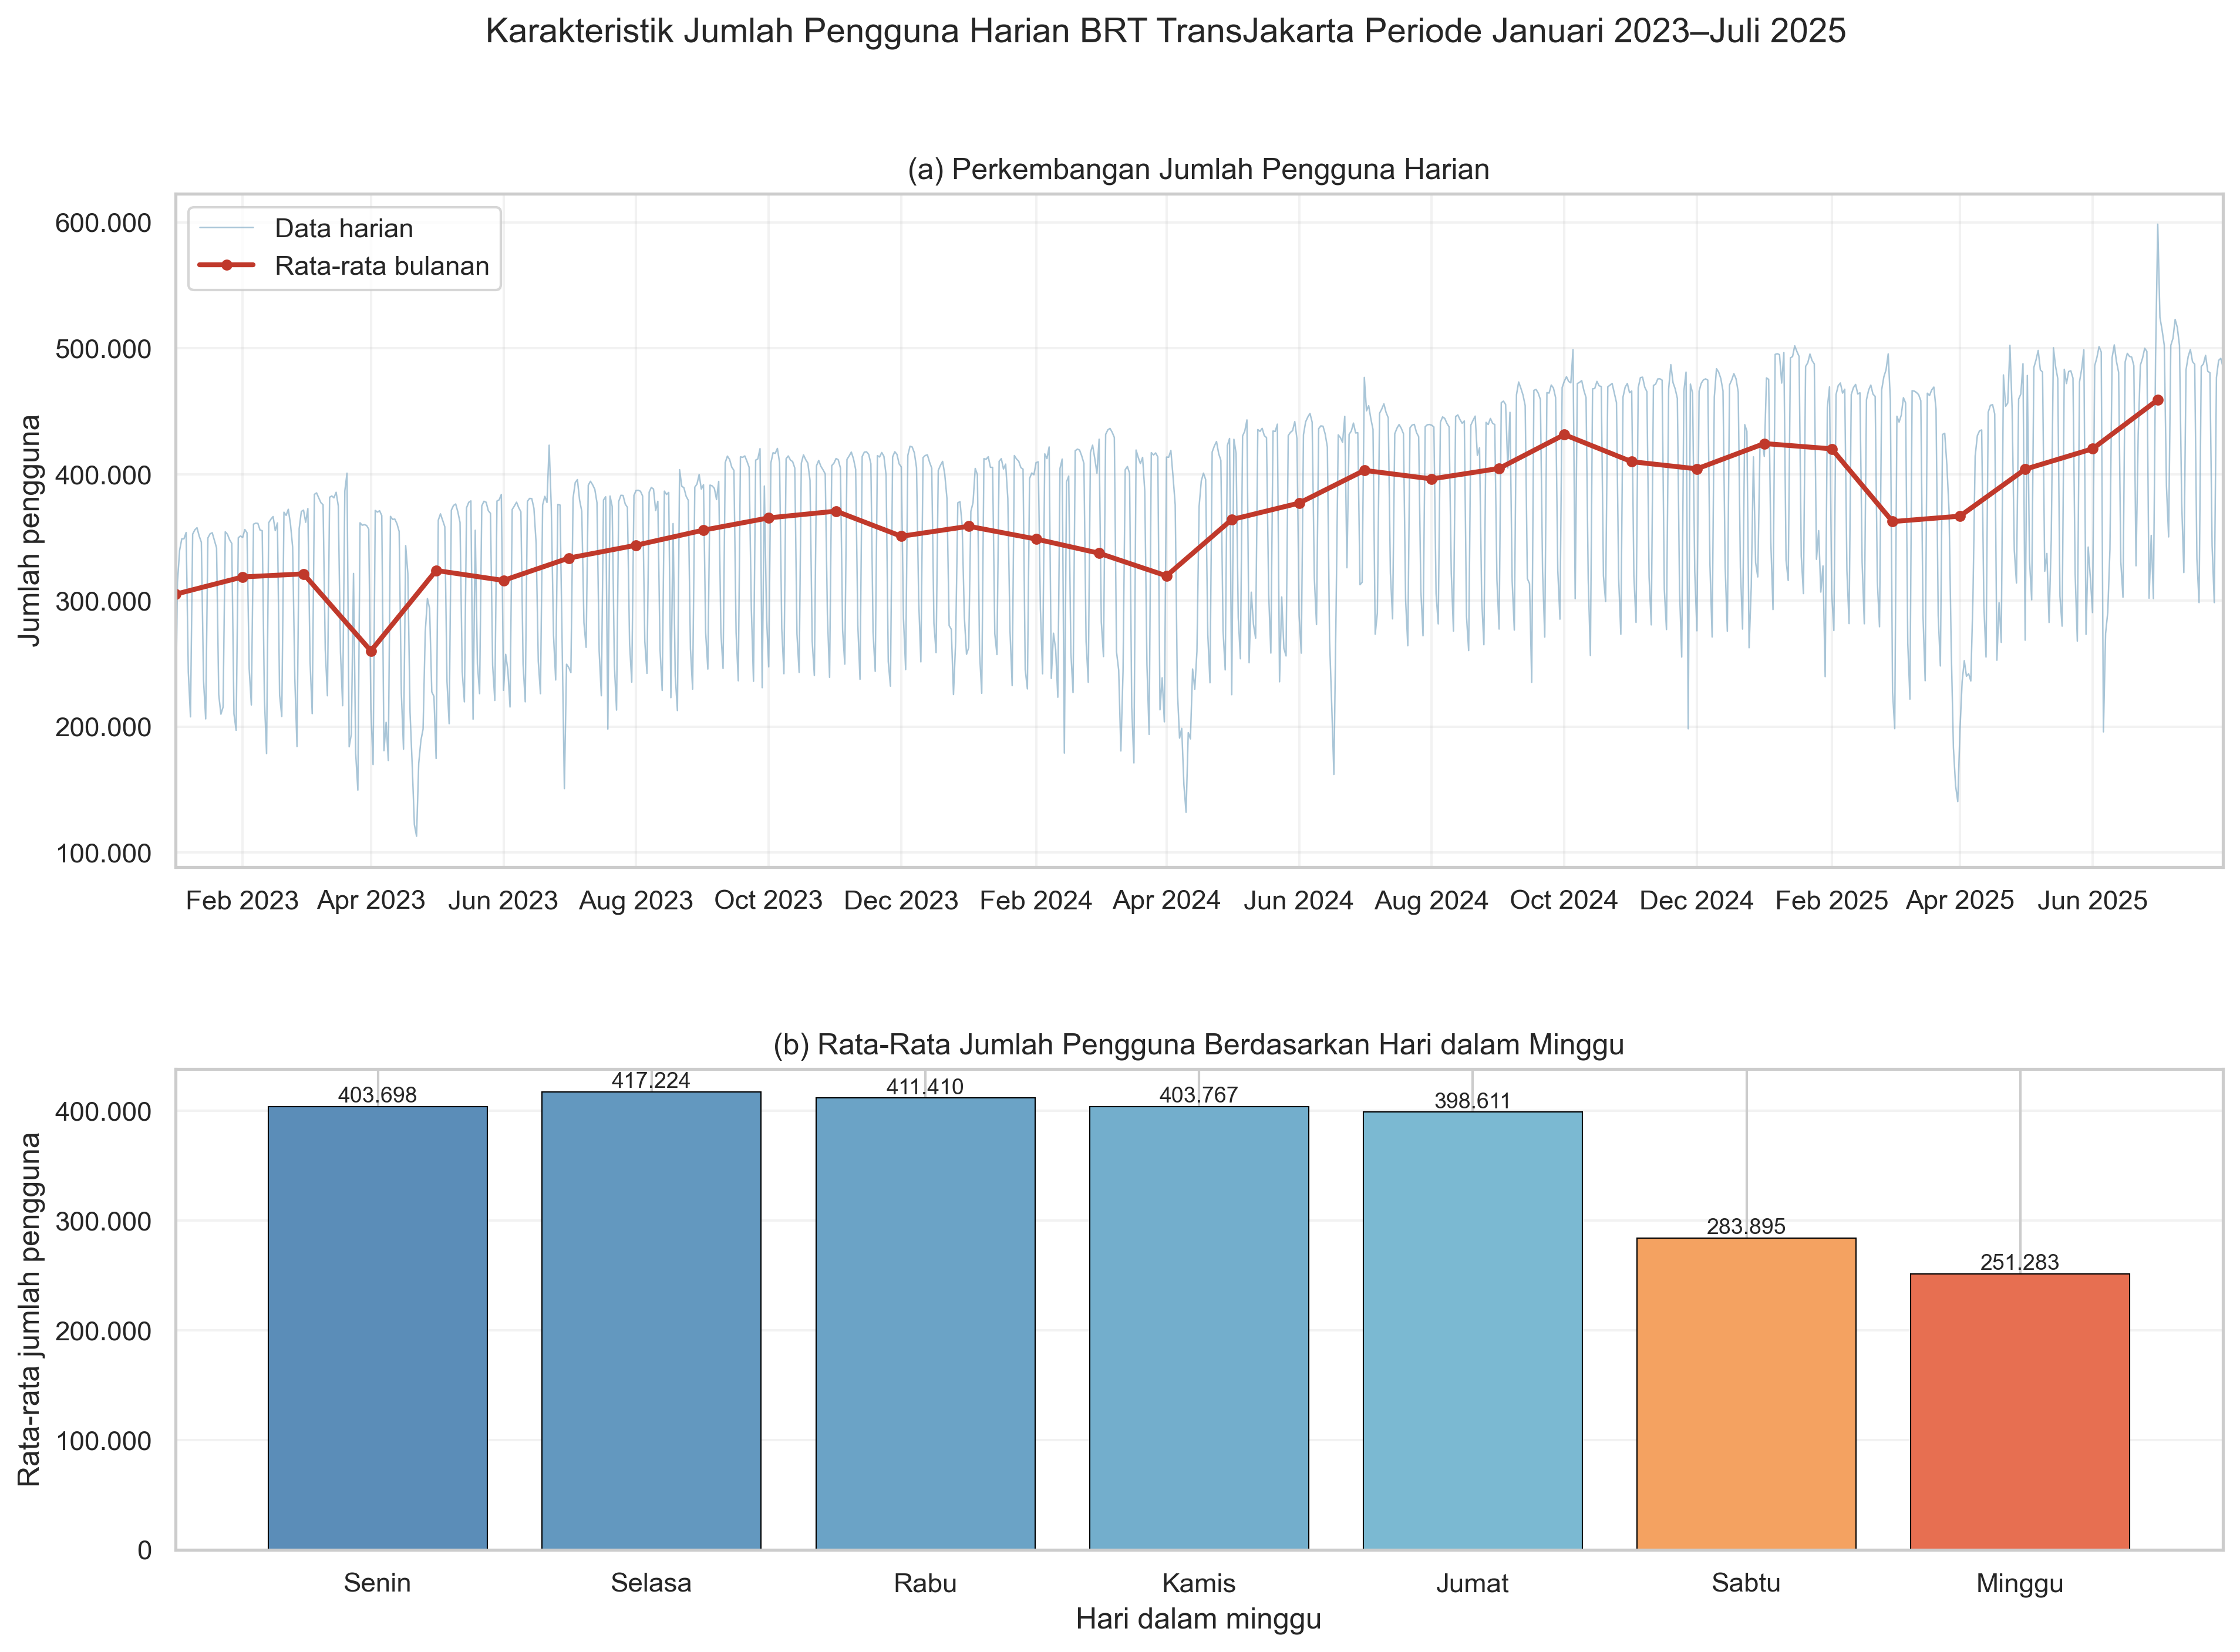

In [369]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

# =========================
# SESUAIKAN NAMA KOLOM
# =========================
date_col = "tanggal"
target_col = "pengguna"

df_plot = df.copy()

df_plot[date_col] = pd.to_datetime(
    df_plot[date_col],
    dayfirst=True
)

df_plot = df_plot.sort_values(date_col)

# Format ribuan menggunakan tanda titik
format_ribuan = FuncFormatter(
    lambda x, pos: f"{x:,.0f}".replace(",", ".")
)

# =========================
# RATA-RATA BULANAN
# =========================
rata_bulanan = (
    df_plot
    .set_index(date_col)[target_col]
    .resample("MS")
    .mean()
)

# =========================
# RATA-RATA HARIAN
# =========================
nama_hari = {
    0: "Senin",
    1: "Selasa",
    2: "Rabu",
    3: "Kamis",
    4: "Jumat",
    5: "Sabtu",
    6: "Minggu"
}

urutan_hari = [
    "Senin", "Selasa", "Rabu",
    "Kamis", "Jumat", "Sabtu", "Minggu"
]

df_plot["Hari"] = (
    df_plot[date_col]
    .dt.dayofweek
    .map(nama_hari)
)

rata_hari = (
    df_plot
    .groupby("Hari")[target_col]
    .mean()
    .reindex(urutan_hari)
)

# =========================
# MEMBUAT DUA PANEL
# =========================
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 10),
    gridspec_kw={
        "height_ratios": [1.4, 1],
        "hspace": 0.35
    }
)

# Panel (a): tren seluruh periode
axes[0].plot(
    df_plot[date_col],
    df_plot[target_col],
    color="#7aa6c2",
    linewidth=0.6,
    alpha=0.65,
    label="Data harian"
)

axes[0].plot(
    rata_bulanan.index,
    rata_bulanan.values,
    color="#c0392b",
    linewidth=2,
    marker="o",
    markersize=3.5,
    label="Rata-rata bulanan"
)

axes[0].set_title(
    "(a) Perkembangan Jumlah Pengguna Harian",
    fontsize=12
)
axes[0].set_xlabel("")
axes[0].set_ylabel("Jumlah pengguna")
axes[0].yaxis.set_major_formatter(format_ribuan)

axes[0].xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)
axes[0].xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

axes[0].set_xlim(
    df_plot[date_col].min(),
    df_plot[date_col].max()
)

axes[0].legend()
axes[0].grid(alpha=0.25)

# Panel (b): pola mingguan
warna = [
    "#5b8db8",
    "#6398bf",
    "#6ba3c6",
    "#73aecc",
    "#7bb9d2",
    "#f4a261",
    "#e76f51"
]

bars = axes[1].bar(
    rata_hari.index,
    rata_hari.values,
    color=warna,
    edgecolor="black",
    linewidth=0.5
)

axes[1].set_title(
    "(b) Rata-Rata Jumlah Pengguna Berdasarkan Hari dalam Minggu",
    fontsize=12
)
axes[1].set_xlabel("Hari dalam minggu")
axes[1].set_ylabel("Rata-rata jumlah pengguna")
axes[1].yaxis.set_major_formatter(format_ribuan)
axes[1].grid(axis="y", alpha=0.25)

# Menampilkan nilai di atas batang
for bar in bars:
    nilai = bar.get_height()

    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        nilai,
        f"{nilai:,.0f}".replace(",", "."),
        ha="center",
        va="bottom",
        fontsize=9
    )

fig.suptitle(
    "Karakteristik Jumlah Pengguna Harian BRT TransJakarta "
    "Periode Januari 2023–Juli 2025",
    fontsize=14,
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "karakteristik_pengguna_transjakarta.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# UJI SIG

In [375]:
# ============================================================
# UJI PERBEDAAN AKURASI PREDIKSI
# Hybrid vs SARIMAX dan Hybrid vs LightGBM
# Loss: Absolute Error
# Varians: HAC / Newey-West
# Hipotesis satu arah
# ============================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

from scipy.stats import t
from statsmodels.stats.multitest import multipletests


def uji_dm_hac(
    y_true,
    pred_pembanding,
    pred_hybrid,
    nama_pembanding,
    loss="absolute",
    maxlags=7,
    alpha=0.05
):
    """
    Menguji apakah model hybrid memiliki akurasi lebih baik
    daripada model pembanding.

    Hipotesis:
    H0: E(loss_pembanding - loss_hybrid) <= 0
    H1: E(loss_pembanding - loss_hybrid) > 0

    Parameter
    ---------
    y_true : array-like
        Nilai aktual.
    pred_pembanding : array-like
        Prediksi SARIMAX atau LightGBM.
    pred_hybrid : array-like
        Prediksi model hybrid.
    nama_pembanding : str
        Nama model pembanding.
    loss : {"absolute", "squared"}
        Fungsi loss yang digunakan.
    maxlags : int
        Lag maksimum HAC. Nilai 7 digunakan untuk mengakomodasi
        kemungkinan ketergantungan mingguan.
    alpha : float
        Taraf signifikansi.

    Returns
    -------
    dict
        Hasil pengujian.
    """

    # Mengubah input menjadi array satu dimensi
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    pred_pembanding = np.asarray(
        pred_pembanding, dtype=float
    ).reshape(-1)
    pred_hybrid = np.asarray(
        pred_hybrid, dtype=float
    ).reshape(-1)

    # Memastikan panjang seluruh data sama
    if not (
        len(y_true)
        == len(pred_pembanding)
        == len(pred_hybrid)
    ):
        raise ValueError(
            "Panjang y_true, pred_pembanding, dan pred_hybrid "
            "harus sama."
        )

    # Menghapus observasi yang memiliki NaN atau inf
    valid = (
        np.isfinite(y_true)
        & np.isfinite(pred_pembanding)
        & np.isfinite(pred_hybrid)
    )

    y_true = y_true[valid]
    pred_pembanding = pred_pembanding[valid]
    pred_hybrid = pred_hybrid[valid]

    n = len(y_true)

    if n < 10:
        raise ValueError(
            "Jumlah observasi terlalu sedikit untuk pengujian."
        )

    if maxlags >= n:
        raise ValueError(
            "maxlags harus lebih kecil daripada jumlah observasi."
        )

    # Error prediksi
    error_pembanding = y_true - pred_pembanding
    error_hybrid = y_true - pred_hybrid

    # Menentukan fungsi loss
    if loss == "absolute":
        loss_pembanding = np.abs(error_pembanding)
        loss_hybrid = np.abs(error_hybrid)
        nama_loss = "Absolute Error"

    elif loss == "squared":
        loss_pembanding = error_pembanding ** 2
        loss_hybrid = error_hybrid ** 2
        nama_loss = "Squared Error"
        elif loss == "percentage":
    if np.any(y_true == 0):
        raise ValueError(
            "MAPE tidak dapat dihitung karena terdapat nilai aktual nol."
        )

    loss_pembanding = np.abs(
        error_pembanding / y_true
    ) * 100

    loss_hybrid = np.abs(
        error_hybrid / y_true
    ) * 100

    nama_loss = "Absolute Percentage Error"

    else:
        raise ValueError(
            "loss harus 'absolute' atau 'squared'."
        )

    # Loss differential
    # Positif berarti loss pembanding lebih besar daripada hybrid
    loss_diff = loss_pembanding - loss_hybrid

    # Regresi loss differential terhadap konstanta
    # Koefisien konstanta = rata-rata loss differential
    X = np.ones((n, 1))

    model = sm.OLS(loss_diff, X).fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags": maxlags,
            "kernel": "bartlett",
            "use_correction": True
        },
        use_t=True
    )

    mean_loss_diff = float(model.params[0])
    standard_error = float(model.bse[0])
    dm_statistic = float(model.tvalues[0])

    # P-value satu arah:
    # H1: rata-rata loss differential > 0
    p_value_one_sided = float(
        t.sf(dm_statistic, df=model.df_resid)
    )

    hybrid_lebih_baik = (
        mean_loss_diff > 0
        and p_value_one_sided < alpha
    )

    if hybrid_lebih_baik:
        keputusan = "Tolak H0"
        kesimpulan = (
            f"Hybrid lebih akurat secara signifikan "
            f"daripada {nama_pembanding}."
        )
    else:
        keputusan = "Gagal menolak H0"
        kesimpulan = (
            f"Belum terdapat bukti bahwa hybrid lebih akurat "
            f"secara signifikan daripada {nama_pembanding}."
        )

    return {
        "Perbandingan": f"Hybrid vs {nama_pembanding}",
        "Jumlah observasi": n,
        "Loss": nama_loss,
        "Rata-rata loss pembanding":
            np.mean(loss_pembanding),
        "Rata-rata loss hybrid":
            np.mean(loss_hybrid),
        "Mean loss differential":
            mean_loss_diff,
        "Standard error HAC":
            standard_error,
        "Statistik uji":
            dm_statistic,
        "P-value satu arah":
            p_value_one_sided,
        "Keputusan awal":
            keputusan,
        "Kesimpulan awal":
            kesimpulan
    }

SyntaxError: invalid syntax (781096053.py, line 115)

In [381]:
import numpy as np
import statsmodels.api as sm

from scipy.stats import t


def uji_loss_diff_hac(
    y_true,
    pred_pembanding,
    pred_hybrid,
    nama_pembanding,
    loss="absolute",
    maxlags=7,
    alpha=0.05
):
    """
    Menguji apakah rata-rata loss model pembanding lebih besar
    daripada rata-rata loss model hybrid menggunakan standard error
    HAC/Newey-West.

    Hipotesis:
    H0: E(loss_pembanding - loss_hybrid) <= 0
    H1: E(loss_pembanding - loss_hybrid) > 0

    Catatan:
    Pengujian ini merupakan uji rata-rata loss differential dengan HAC,
    bukan uji Diebold-Mariano klasik untuk repeated fixed-horizon forecasts.
    """

    # Mengubah input menjadi array satu dimensi
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    pred_pembanding = np.asarray(
        pred_pembanding, dtype=float
    ).reshape(-1)
    pred_hybrid = np.asarray(
        pred_hybrid, dtype=float
    ).reshape(-1)

    # Memastikan panjang sama
    if not (
        len(y_true)
        == len(pred_pembanding)
        == len(pred_hybrid)
    ):
        raise ValueError(
            "Panjang y_true, pred_pembanding, dan pred_hybrid "
            "harus sama."
        )

    # Menghapus NaN dan inf
    valid = (
        np.isfinite(y_true)
        & np.isfinite(pred_pembanding)
        & np.isfinite(pred_hybrid)
    )

    y_true = y_true[valid]
    pred_pembanding = pred_pembanding[valid]
    pred_hybrid = pred_hybrid[valid]

    n = len(y_true)

    if n < 10:
        raise ValueError(
            "Jumlah observasi terlalu sedikit untuk pengujian."
        )

    if not isinstance(maxlags, int) or maxlags < 0:
        raise ValueError("maxlags harus berupa bilangan bulat nonnegatif.")

    if maxlags >= n:
        raise ValueError(
            "maxlags harus lebih kecil daripada jumlah observasi."
        )

    # Error prediksi
    error_pembanding = y_true - pred_pembanding
    error_hybrid = y_true - pred_hybrid

    # Menentukan fungsi loss
    if loss == "absolute":
        loss_pembanding = np.abs(error_pembanding)
        loss_hybrid = np.abs(error_hybrid)
        nama_loss = "Absolute Error"

    elif loss == "squared":
        loss_pembanding = error_pembanding ** 2
        loss_hybrid = error_hybrid ** 2
        nama_loss = "Squared Error"

    elif loss == "percentage":
        if np.any(y_true == 0):
            raise ValueError(
                "Absolute Percentage Error tidak dapat dihitung "
                "karena terdapat nilai aktual nol."
            )

        loss_pembanding = (
            np.abs(error_pembanding / y_true) * 100
        )

        loss_hybrid = (
            np.abs(error_hybrid / y_true) * 100
        )

        nama_loss = "Absolute Percentage Error"

    else:
        raise ValueError(
            "loss harus 'absolute', 'squared', atau 'percentage'."
        )

    # Positif berarti hybrid mempunyai loss lebih kecil
    loss_diff = loss_pembanding - loss_hybrid

    # Regresi loss differential terhadap konstanta
    X = np.ones((n, 1))

    model = sm.OLS(loss_diff, X).fit(
        cov_type="HAC",
        cov_kwds={
            "maxlags": maxlags,
            "kernel": "bartlett",
            "use_correction": True
        },
        use_t=True
    )

    mean_loss_diff = float(model.params[0])
    standard_error = float(model.bse[0])
    statistik_uji = float(model.tvalues[0])

    # P-value satu arah untuk H1: mean loss differential > 0
    p_value_one_sided = float(
        t.sf(statistik_uji, df=model.df_resid)
    )

    if mean_loss_diff > 0 and p_value_one_sided < alpha:
        keputusan = "Tolak H0"
        kesimpulan = (
            f"Terdapat bukti bahwa hybrid mempunyai rata-rata "
            f"{nama_loss.lower()} yang lebih kecil daripada "
            f"{nama_pembanding}."
        )
    else:
        keputusan = "Gagal menolak H0"
        kesimpulan = (
            f"Belum terdapat bukti yang cukup bahwa hybrid "
            f"mempunyai rata-rata {nama_loss.lower()} yang lebih "
            f"kecil daripada {nama_pembanding}."
        )

    return {
        "Perbandingan": f"Hybrid vs {nama_pembanding}",
        "Jumlah observasi": n,
        "Loss": nama_loss,
        "Lag HAC": maxlags,
        "Rata-rata loss pembanding": float(
            np.mean(loss_pembanding)
        ),
        "Rata-rata loss hybrid": float(
            np.mean(loss_hybrid)
        ),
        "Mean loss differential": mean_loss_diff,
        "Standard error HAC": standard_error,
        "Statistik uji": statistik_uji,
        "P-value satu arah": p_value_one_sided,
        "Keputusan": keputusan,
        "Kesimpulan": kesimpulan
    }

In [383]:
hasil_sarimax = uji_loss_diff_hac(
    y_true=y_test,
    pred_pembanding=pred_sarimax_asli,
    pred_hybrid=pred_hybrid_asli,
    nama_pembanding="SARIMAX",
    loss="absolute",
    maxlags=7
)

hasil_lgbm = uji_loss_diff_hac(
    y_true=y_test,
    pred_pembanding=pred_lgbm,
    pred_hybrid=pred_hybrid_asli,
    nama_pembanding="LightGBM",
    loss="absolute",
    maxlags=7
)

hasil_df = pd.DataFrame([
    hasil_sarimax,
    hasil_lgbm
])

display(hasil_df)

,Perbandingan,Jumlah observasi,Loss,Lag HAC,Rata-rata loss pembanding,Rata-rata loss hybrid,Mean loss differential,Standard error HAC,Statistik uji,P-value satu arah,Keputusan,Kesimpulan
0,Hybrid vs SARIMAX,61,Absolute Error,7,24918.888333,22364.065706,2554.822628,743.840869,3.434636,0.000541,Tolak H0,Terdapat bukti bahwa hybrid mempunyai rata-rat...
1,Hybrid vs LightGBM,61,Absolute Error,7,27439.199740,22364.065706,5075.134034,3655.364788,1.388407,0.085073,Gagal menolak H0,Belum terdapat bukti yang cukup bahwa hybrid m...


In [385]:
from statsmodels.stats.multitest import multipletests

p_values = hasil_df["P-value satu arah"].to_numpy()

reject, p_adjusted, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="holm"
)

hasil_df["P-value Holm"] = p_adjusted
hasil_df["Keputusan setelah Holm"] = np.where(
    reject,
    "Tolak H0",
    "Gagal menolak H0"
)

display(hasil_df)

,Perbandingan,Jumlah observasi,Loss,Lag HAC,Rata-rata loss pembanding,Rata-rata loss hybrid,Mean loss differential,Standard error HAC,Statistik uji,P-value satu arah,Keputusan,Kesimpulan,P-value Holm,Keputusan setelah Holm
0,Hybrid vs SARIMAX,61,Absolute Error,7,24918.888333,22364.065706,2554.822628,743.840869,3.434636,0.000541,Tolak H0,Terdapat bukti bahwa hybrid mempunyai rata-rat...,0.001082,Tolak H0
1,Hybrid vs LightGBM,61,Absolute Error,7,27439.199740,22364.065706,5075.134034,3655.364788,1.388407,0.085073,Gagal menolak H0,Belum terdapat bukti yang cukup bahwa hybrid m...,0.085073,Gagal menolak H0


In [120]:
hasil_akhir.to_excel(
    "hasil_uji_signifikansi_model.xlsx",
    index=False
)

In [387]:
import numpy as np
from scipy import stats

def dm_test(actual, pred1, pred2, h=1, crit="MAE"):
    actual = np.asarray(actual, dtype=float)
    pred1 = np.asarray(pred1, dtype=float)
    pred2 = np.asarray(pred2, dtype=float)

    e1 = actual - pred1
    e2 = actual - pred2

    if crit == "MSE":
        d = e1**2 - e2**2
    elif crit == "MAE":
        d = np.abs(e1) - np.abs(e2)
    else:
        raise ValueError("crit harus 'MSE' atau 'MAE'")

    T = len(d)
    d_mean = np.mean(d)

    gamma0 = np.var(d, ddof=0)
    var_d = gamma0
    for lag in range(1, h):
        gamma = np.cov(d[lag:], d[:-lag])[0, 1]
        weight = 1 - lag / h
        var_d += 2 * weight * gamma
    var_d /= T

    dm_stat = d_mean / np.sqrt(var_d)

    hln_correction = np.sqrt((T + 1 - 2*h + h*(h-1)/T) / T)
    dm_stat_adj = dm_stat * hln_correction

    p_value = 2 * (1 - stats.t.cdf(np.abs(dm_stat_adj), df=T-1))

    return dm_stat_adj, p_value


def wilcoxon_test(actual, pred1, pred2, crit="MAE"):
    """
    Wilcoxon Signed-Rank Test
    H0: median absolute error kedua model sama
    H1: median absolute error kedua model beda signifikan
    """
    actual = np.asarray(actual, dtype=float)
    pred1 = np.asarray(pred1, dtype=float)
    pred2 = np.asarray(pred2, dtype=float)

    if crit == "MAE":
        err1 = np.abs(actual - pred1)
        err2 = np.abs(actual - pred2)
    elif crit == "MSE":
        err1 = (actual - pred1) ** 2
        err2 = (actual - pred2) ** 2
    else:
        raise ValueError("crit harus 'MSE' atau 'MAE'")

    stat, p = stats.wilcoxon(err1, err2)
    return stat, p


pairs = {
    "SARIMAX vs LightGBM": ("pred_sarimax_asli", "pred_lgbm"),
    "SARIMAX vs Hybrid":   ("pred_sarimax_asli", "pred_hybrid_asli"),
    "LightGBM vs Hybrid":  ("pred_lgbm", "pred_hybrid_asli"),
}

preds = {
    "pred_sarimax_asli": pred_sarimax_asli,
    "pred_lgbm": pred_lgbm,
    "pred_hybrid_asli": pred_hybrid_asli,
}

print("=== Diebold-Mariano Test ===")
for label, (m1, m2) in pairs.items():
    stat, p = dm_test(y_test, preds[m1], preds[m2], h=1, crit="MAE")
    better = m1 if stat < 0 else m2
    sig = "SIGNIFIKAN (p<0.05)" if p < 0.05 else "tidak signifikan"
    print(f"{label:25s} DM={stat:7.4f}  p-value={p:.4f}  -> {sig} (lebih akurat: {better if p<0.05 else '-'})")

print("\n=== Wilcoxon Signed-Rank Test ===")
for label, (m1, m2) in pairs.items():
    stat, p = wilcoxon_test(y_test, preds[m1], preds[m2], crit="MAE")
    sig = "SIGNIFIKAN (p<0.05)" if p < 0.05 else "tidak signifikan"
    print(f"{label:25s} W={stat:7.4f}  p-value={p:.4f}  -> {sig}")

=== Diebold-Mariano Test ===
SARIMAX vs LightGBM       DM=-0.5596  p-value=0.5778  -> tidak signifikan (lebih akurat: -)
SARIMAX vs Hybrid         DM= 3.4521  p-value=0.0010  -> SIGNIFIKAN (p<0.05) (lebih akurat: pred_hybrid_asli)
LightGBM vs Hybrid        DM= 1.2169  p-value=0.2284  -> tidak signifikan (lebih akurat: -)

=== Wilcoxon Signed-Rank Test ===
SARIMAX vs LightGBM       W=892.0000  p-value=0.7008  -> tidak signifikan
SARIMAX vs Hybrid         W=519.0000  p-value=0.0022  -> SIGNIFIKAN (p<0.05)
LightGBM vs Hybrid        W=845.0000  p-value=0.4704  -> tidak signifikan


In [389]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Pastikan semuanya 1 dimensi dan berada pada skala asli
y_true = np.asarray(y_test, dtype=float).reshape(-1)

prediksi_model = {
    "SARIMAX": np.asarray(pred_sarimax_asli, dtype=float).reshape(-1),
    "LightGBM": np.asarray(pred_lgbm, dtype=float).reshape(-1),
    "Hybrid SARIMAX-LightGBM": np.asarray(
        pred_hybrid_asli,
        dtype=float
    ).reshape(-1)
}

hasil_evaluasi = []

for nama_model, y_pred in prediksi_model.items():

    if len(y_true) != len(y_pred):
        raise ValueError(
            f"Panjang y_test dan prediksi {nama_model} tidak sama: "
            f"{len(y_true)} != {len(y_pred)}"
        )

    valid = np.isfinite(y_true) & np.isfinite(y_pred)

    aktual = y_true[valid]
    prediksi = y_pred[valid]

    mae = mean_absolute_error(aktual, prediksi)

    rmse = np.sqrt(
        mean_squared_error(aktual, prediksi)
    )

    if np.any(aktual == 0):
        mape = np.nan
        print(
            f"MAPE {nama_model} tidak dihitung karena "
            "terdapat nilai aktual nol."
        )
    else:
        mape = np.mean(
            np.abs((aktual - prediksi) / aktual)
        ) * 100

    hasil_evaluasi.append({
        "Model": nama_model,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

hasil_evaluasi = pd.DataFrame(hasil_evaluasi)

# Urutkan berdasarkan MAPE terkecil
hasil_evaluasi = (
    hasil_evaluasi
    .sort_values("MAPE (%)")
    .reset_index(drop=True)
)

print(hasil_evaluasi.round({
    "MAE": 2,
    "RMSE": 2,
    "MAPE (%)": 4
}))

                     Model       MAE      RMSE  MAPE (%)
0  Hybrid SARIMAX-LightGBM  22364.07  30489.99    5.6688
1                  SARIMAX  24918.89  32161.33    6.1053
2                 LightGBM  27439.20  48278.42    7.8895
